In [207]:
import os
from os import listdir
from os.path import isfile, join

import numpy as np
import matplotlib.pyplot as plt
from random import sample

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf

from scipy.signal import welch
from scipy.stats import kurtosis, skew
import lightgbm as lgb

import seaborn as sns

import sys
from pathlib import Path
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from tqdm import tqdm
from itertools import product

import glob
import pandas as pd
from datetime import datetime

from concurrent.futures import ProcessPoolExecutor, as_completed
from tqdm import tqdm
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.neighbors import LocalOutlierFactor
import json
from numpy.lib.stride_tricks import sliding_window_view

np.random.seed(seed=1)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'USING DEVICE: {device}')

USING DEVICE: cpu


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
# Source - https://stackoverflow.com/a/3207973
# Posted by pycruft, modified by community. See post 'Timeline' for change history
# Retrieved 2026-11-13, License - CC BY-SA 4.0

files_path  = '/content/drive/MyDrive/2nd_test'
onlyfiles = [f for f in sorted(listdir(files_path)) if isfile(join(files_path, f))]
onlyfiles[:5]

['2004.02.12.10.32.39',
 '2004.02.12.10.42.39',
 '2004.02.12.10.52.39',
 '2004.02.12.11.02.39',
 '2004.02.12.11.12.39']

In [208]:
def show_with_subplots(data, anomalies=None):
  fig, axs = plt.subplots(4,1, figsize=(12,12))
  cols = ['ch0','ch1','ch2','ch3']
  seq = []
  if isinstance(data,pd.DataFrame):
    seq = cols
  elif isinstance(data,np.ndarray):
    seq = range(data.shape[0])
  # for i, col_name in enumerate(['ch0','ch1','ch2','ch3']):
  for i,axis in enumerate(seq):
    axs[i].plot(data[axis])
    if anomalies:
      time_axis = np.linspace(0,len(data[axis])-1,len(data[axis]))
      axs[i].scatter(x=time_axis[anomalies[axis]], y=data[axis,anomalies[axis]], c='r')
    axs[i].set_title(cols[i])

  plt.xlabel('time')
  plt.ylabel('acc')
  plt.show()

In [ ]:


# 1. Moved to the top level so Python's multiprocessing pickle can find it
def _load_single_file_task(args):
  idx, file_path = args
  arr = (
      pd.read_csv(
          file_path,
          sep=r'\s+',  # Handles spaces and tabs automatically
          header=None,
          engine='c',  # Forces the high-performance C parser
      )
      .to_numpy()
      .T
  )
  return idx, arr


def load_all_files_parallel():
  """Loads N files in parallel and packs them directly into a pre-allocated

  3D NumPy array of shape (N_files, 4_channels, M_measurements).
  """
  file_paths = [os.path.join(files_path, f) for f in onlyfiles]
  n_files = len(file_paths)

  if n_files == 0:
    raise ValueError('No files found to load.')

  # 2. Load the first file to determine exact dimensions
  _, first_arr = _load_single_file_task((0, file_paths[0]))
  n_channels, n_measurements = first_arr.shape  # Expected: (4, 20480)

  # 3. Pre-allocate the final 3D array in memory
  data_3d = np.empty((n_files, n_channels, n_measurements), dtype=np.float64)
  data_3d[0] = first_arr

  # 4. Prepare tasks for the remaining files (index + path tuples)
  tasks = [(i, path) for i, path in enumerate(file_paths[1:], start=1)]

  print(f'Loading {n_files} files in parallel...')
  with ProcessPoolExecutor() as executor:
    # Submit all tasks using the top-level helper function
    futures = [executor.submit(_load_single_file_task, task) for task in tasks]

    # Fill the pre-allocated array as each process finishes
    for future in as_completed(futures):
      idx, arr = future.result()
      data_3d[idx] = arr

  print(f'Successfully loaded shape: {data_3d.shape}')
  return data_3d

In [ ]:
all_seqs = load_all_files_parallel()
all_seqs

Loading 984 files in parallel...
Successfully loaded shape: (984, 4, 20480)


array([[[-0.049, -0.042,  0.015, ..., -0.012, -0.012,  0.02 ],
        [-0.071, -0.073,  0.   , ...,  0.007,  0.093,  0.076],
        [-0.132, -0.007,  0.007, ...,  0.056,  0.017, -0.042],
        [-0.01 , -0.105,  0.   , ..., -0.007, -0.044, -0.029]],

       [[-0.088,  0.022, -0.015, ...,  0.12 ,  0.098,  0.01 ],
        [-0.127, -0.178, -0.066, ...,  0.144, -0.046,  0.029],
        [ 0.154, -0.073, -0.259, ...,  0.088,  0.042, -0.112],
        [ 0.022, -0.022, -0.056, ...,  0.073,  0.024, -0.042]],

       [[ 0.112,  0.049, -0.027, ..., -0.068, -0.105, -0.01 ],
        [-0.01 , -0.012, -0.017, ...,  0.151,  0.083, -0.076],
        [-0.005, -0.046, -0.012, ...,  0.044,  0.002,  0.146],
        [ 0.022,  0.02 ,  0.098, ..., -0.042, -0.046,  0.022]],

       ...,

       [[-0.005, -0.347, -0.168, ..., -0.967, -0.876,  0.076],
        [-0.012,  0.159,  0.063, ...,  0.242, -0.239, -0.356],
        [-0.071, -0.173, -0.11 , ..., -0.125,  0.034, -0.039],
        [ 0.017, -0.034, -0.046, ...

In [ ]:
np.save('nasa_bearing.npy', all_seqs)

In [11]:
# data = np.load('nasa_bearing.npy')
all_seqs = np.load('/content/drive/MyDrive/nasa_bearing.npy')
all_seqs

array([[[-0.049, -0.042,  0.015, ..., -0.012, -0.012,  0.02 ],
        [-0.071, -0.073,  0.   , ...,  0.007,  0.093,  0.076],
        [-0.132, -0.007,  0.007, ...,  0.056,  0.017, -0.042],
        [-0.01 , -0.105,  0.   , ..., -0.007, -0.044, -0.029]],

       [[-0.088,  0.022, -0.015, ...,  0.12 ,  0.098,  0.01 ],
        [-0.127, -0.178, -0.066, ...,  0.144, -0.046,  0.029],
        [ 0.154, -0.073, -0.259, ...,  0.088,  0.042, -0.112],
        [ 0.022, -0.022, -0.056, ...,  0.073,  0.024, -0.042]],

       [[ 0.112,  0.049, -0.027, ..., -0.068, -0.105, -0.01 ],
        [-0.01 , -0.012, -0.017, ...,  0.151,  0.083, -0.076],
        [-0.005, -0.046, -0.012, ...,  0.044,  0.002,  0.146],
        [ 0.022,  0.02 ,  0.098, ..., -0.042, -0.046,  0.022]],

       ...,

       [[-0.005, -0.347, -0.168, ..., -0.967, -0.876,  0.076],
        [-0.012,  0.159,  0.063, ...,  0.242, -0.239, -0.356],
        [-0.071, -0.173, -0.11 , ..., -0.125,  0.034, -0.039],
        [ 0.017, -0.034, -0.046, ...

In [ ]:
def load_single(file_name, return_pd=False):
  file_path = join(files_path,file_name)
  if return_pd:
    return pd.read_csv(file_path, sep="\t",names=[f'ch{i}' for i in range(4)])
  else:
    return np.loadtxt(file_path)

def load_all_files():
  return np.stack([load_single(f).T for f in onlyfiles], axis=0)

In [ ]:
load_all_files()

array([[[-0.049, -0.042,  0.015, ..., -0.012, -0.012,  0.02 ],
        [-0.071, -0.073,  0.   , ...,  0.007,  0.093,  0.076],
        [-0.132, -0.007,  0.007, ...,  0.056,  0.017, -0.042],
        [-0.01 , -0.105,  0.   , ..., -0.007, -0.044, -0.029]],

       [[-0.088,  0.022, -0.015, ...,  0.12 ,  0.098,  0.01 ],
        [-0.127, -0.178, -0.066, ...,  0.144, -0.046,  0.029],
        [ 0.154, -0.073, -0.259, ...,  0.088,  0.042, -0.112],
        [ 0.022, -0.022, -0.056, ...,  0.073,  0.024, -0.042]],

       [[ 0.112,  0.049, -0.027, ..., -0.068, -0.105, -0.01 ],
        [-0.01 , -0.012, -0.017, ...,  0.151,  0.083, -0.076],
        [-0.005, -0.046, -0.012, ...,  0.044,  0.002,  0.146],
        [ 0.022,  0.02 ,  0.098, ..., -0.042, -0.046,  0.022]],

       ...,

       [[-0.078, -0.073,  0.   , ...,  0.073,  0.061, -0.073],
        [-0.054, -0.107, -0.103, ...,  0.112, -0.1  , -0.146],
        [ 0.063,  0.161,  0.107, ...,  0.127, -0.081,  0.029],
        [-0.044, -0.042,  0.042, ...

In [ ]:
load_single(onlyfiles[1])

array([[-0.088, -0.127,  0.154,  0.022],
       [ 0.022, -0.178, -0.073, -0.022],
       [-0.015, -0.066, -0.259, -0.056],
       ...,
       [ 0.12 ,  0.144,  0.088,  0.073],
       [ 0.098, -0.046,  0.042,  0.024],
       [ 0.01 ,  0.029, -0.112, -0.042]], shape=(20480, 4))

In [ ]:


sample_file = load_single(onlyfiles[0], return_pd=True)
sample_file.head()

,ch0,ch1,ch2,ch3
0,-0.049,-0.071,-0.132,-0.010
1,-0.042,-0.073,-0.007,-0.105
2,0.015,0.000,0.007,0.000
3,-0.051,0.020,-0.002,0.100
4,-0.107,0.010,0.127,0.054


In [ ]:
sample_file.describe()

,ch0,ch1,ch2,ch3
count,20480.000000,20480.000000,20480.000000,20480.000000
mean,-0.010196,-0.012695,-0.014541,-0.010026
std,0.073477,0.090056,0.108436,0.053168
min,-0.386000,-0.513000,-0.911000,-0.264000
25%,-0.059000,-0.073000,-0.081000,-0.046000
50%,-0.010000,-0.015000,-0.015000,-0.010000
75%,0.037000,0.046000,0.051000,0.027000
max,0.454000,0.464000,1.023000,0.193000


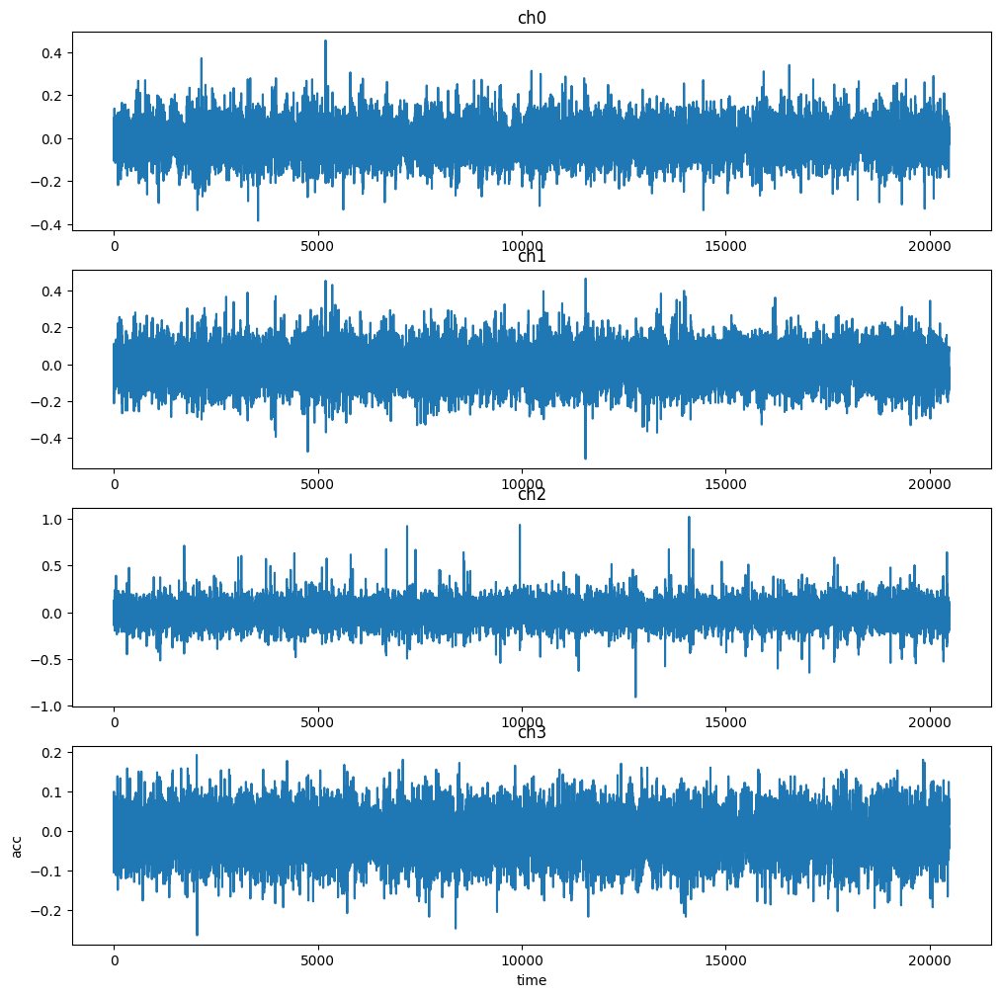

In [ ]:
show_with_subplots(sample_file)


In [ ]:
last_file = load_single(onlyfiles[-1], return_pd=True)
last_file.head()
last_file.describe()

,ch0,ch1,ch2,ch3
count,20480.000000,20480.000000,20480.000000,20480.000000
mean,-0.001162,-0.000701,-0.000664,-0.001695
std,0.001000,0.001021,0.000996,0.001280
min,-0.005000,-0.002000,-0.005000,-0.005000
25%,-0.002000,-0.002000,-0.002000,-0.002000
50%,-0.002000,0.000000,0.000000,-0.002000
75%,0.000000,0.000000,0.000000,0.000000
max,0.002000,0.002000,0.002000,0.002000


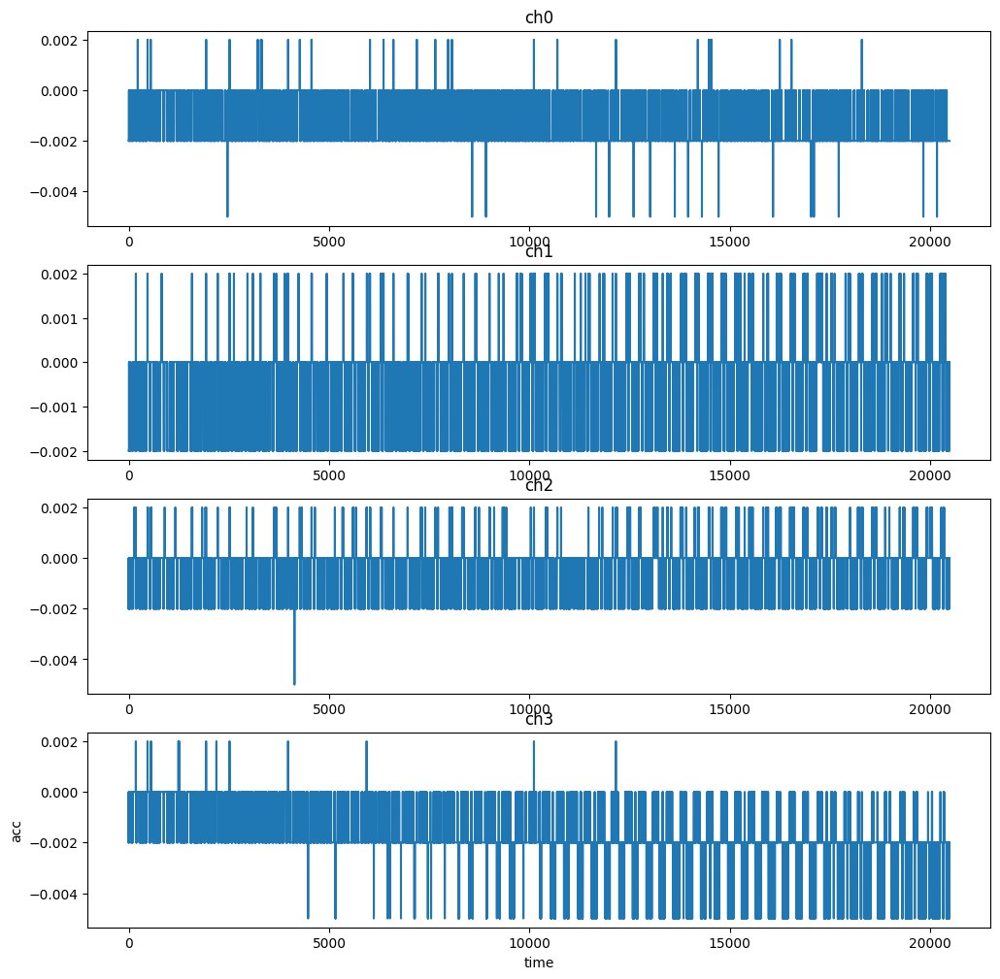

In [ ]:
show_with_subplots(last_file)

## Sensor lifetime-measurements mean and std

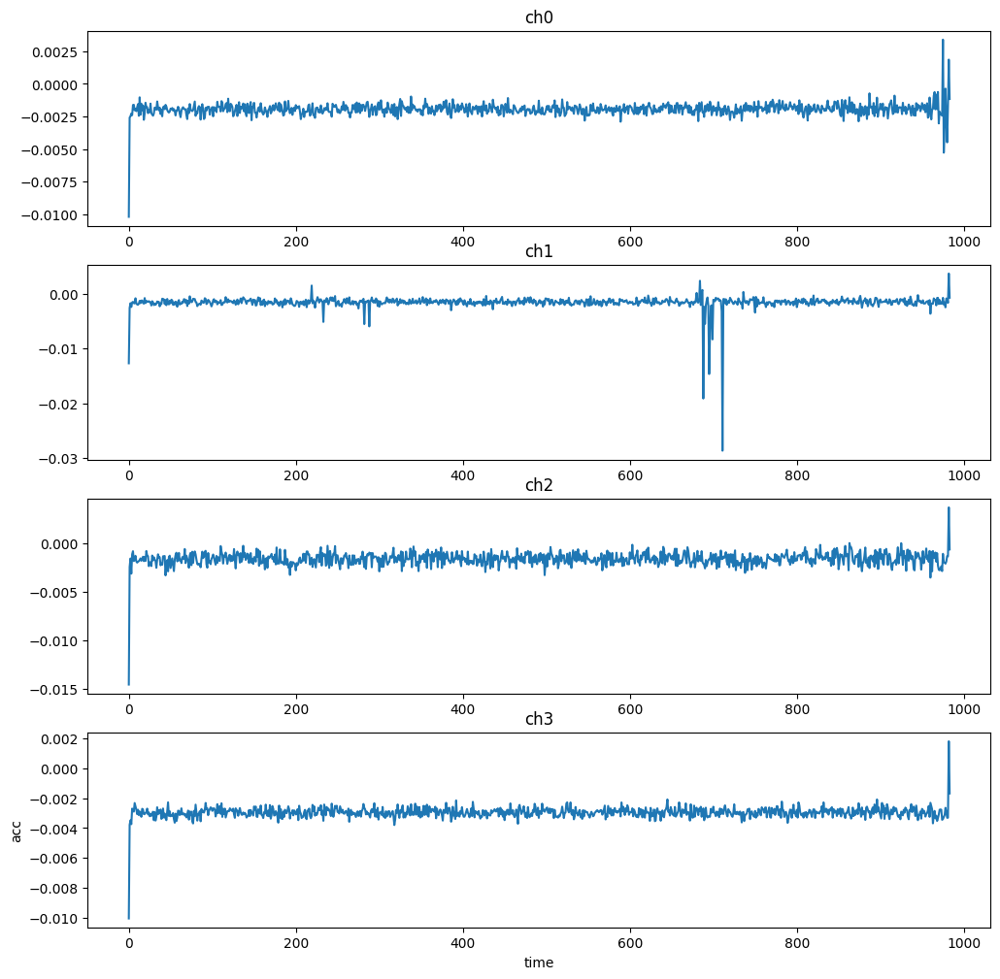

In [ ]:
file_mean = all_seqs.mean(axis=2)
show_with_subplots(file_mean.T)

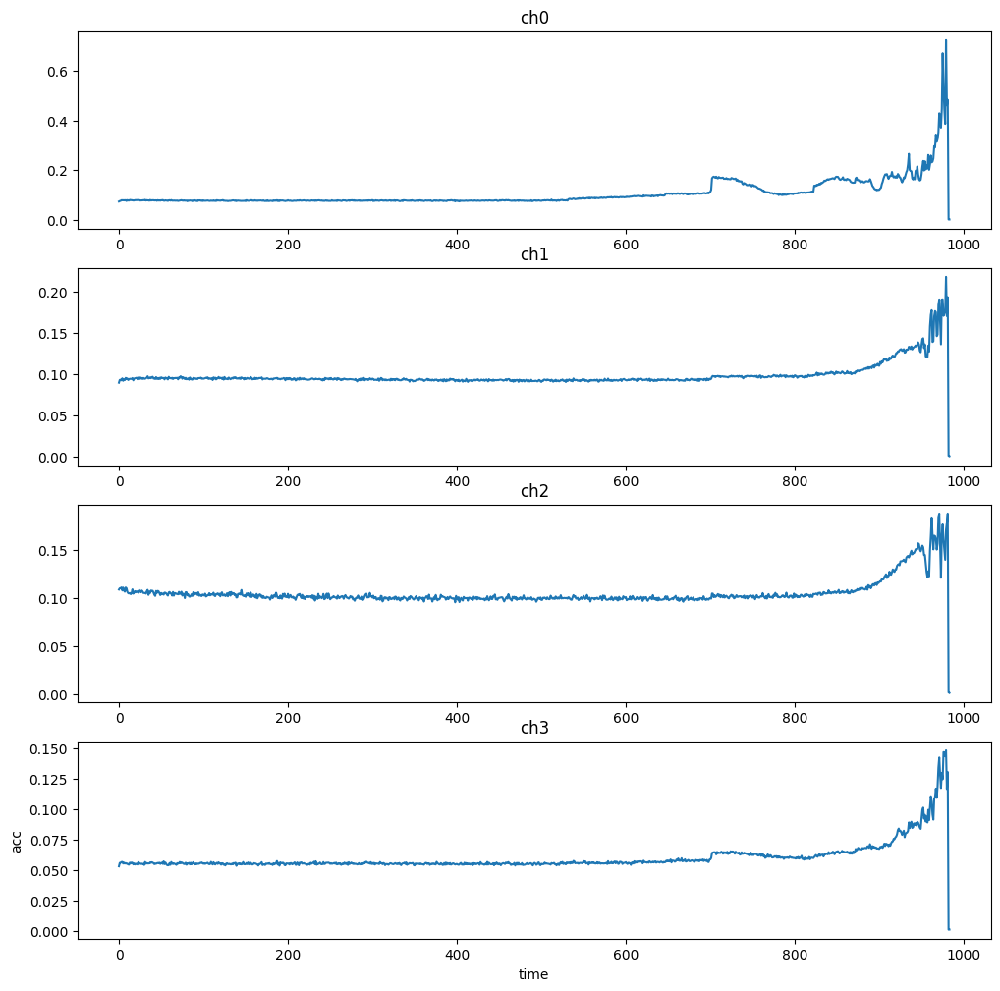

In [ ]:
file_std = all_seqs.std(axis=2)
show_with_subplots(file_std.T)

View first 30 recording

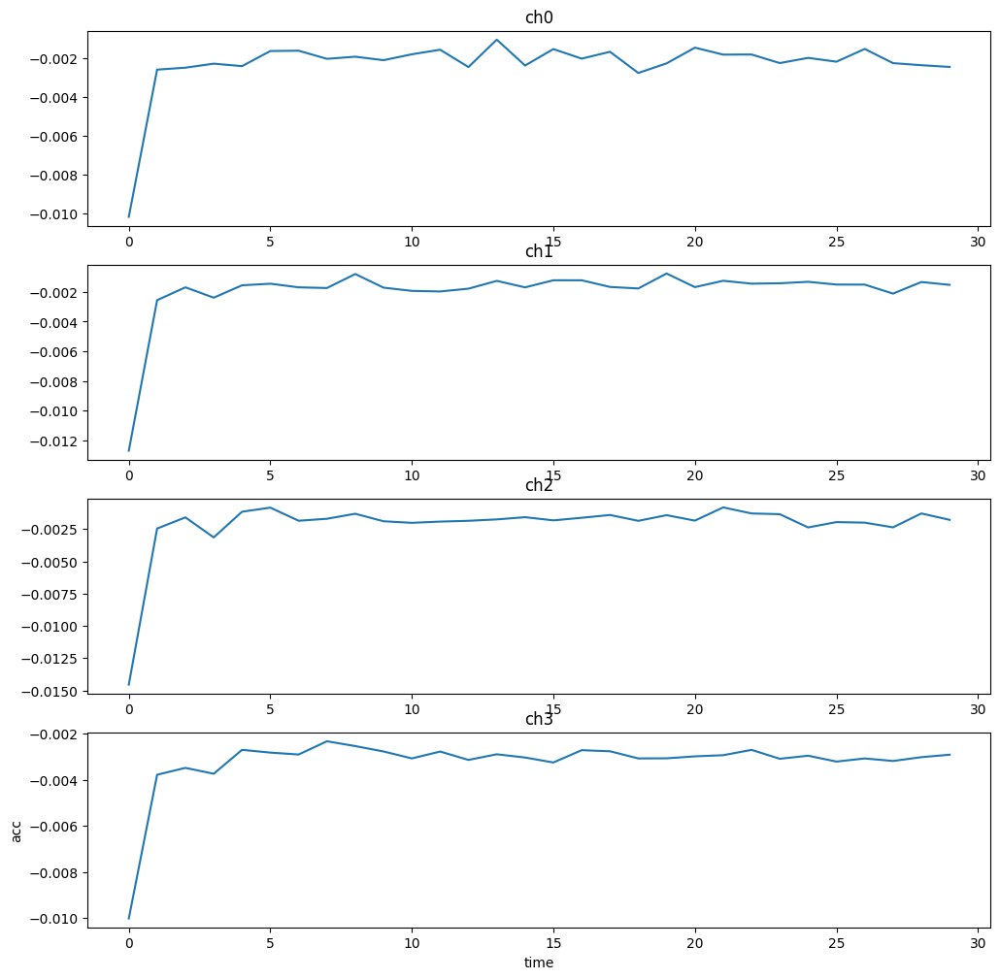

In [ ]:
first_file_mean = all_seqs[:30].mean(axis=2)
show_with_subplots(first_file_mean.T)

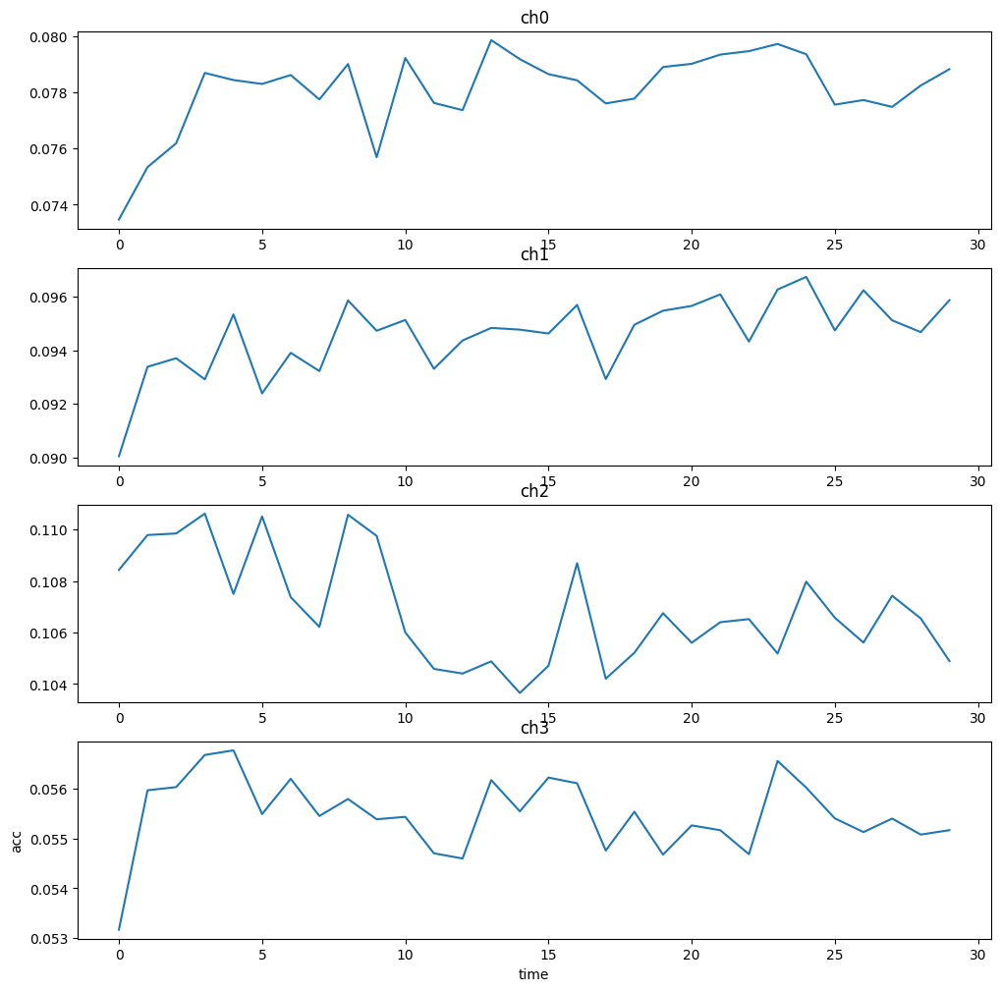

In [ ]:
first_file_std = all_seqs[:30].std(axis=2)
show_with_subplots(first_file_std.T)

Skip first 5 files/recordings

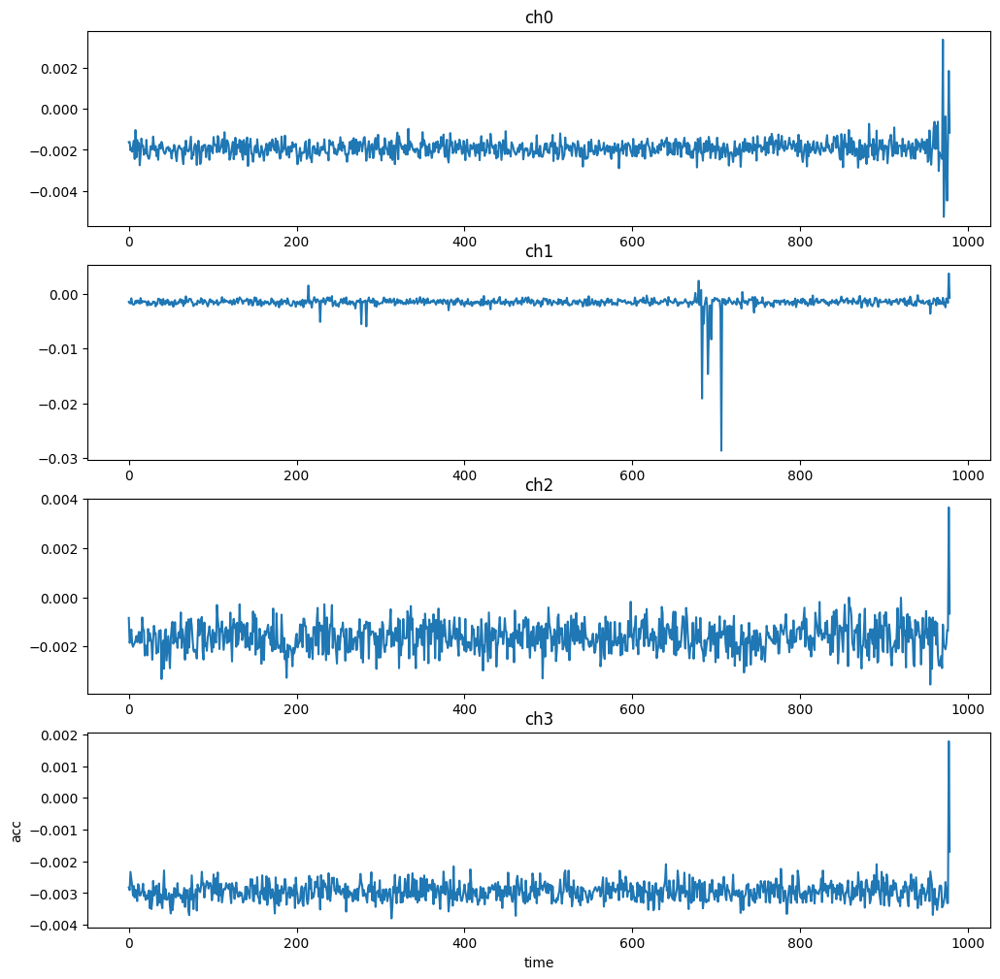

In [ ]:
skip_init_file_mean = all_seqs[5:].mean(axis=2)
show_with_subplots(skip_init_file_mean.T)

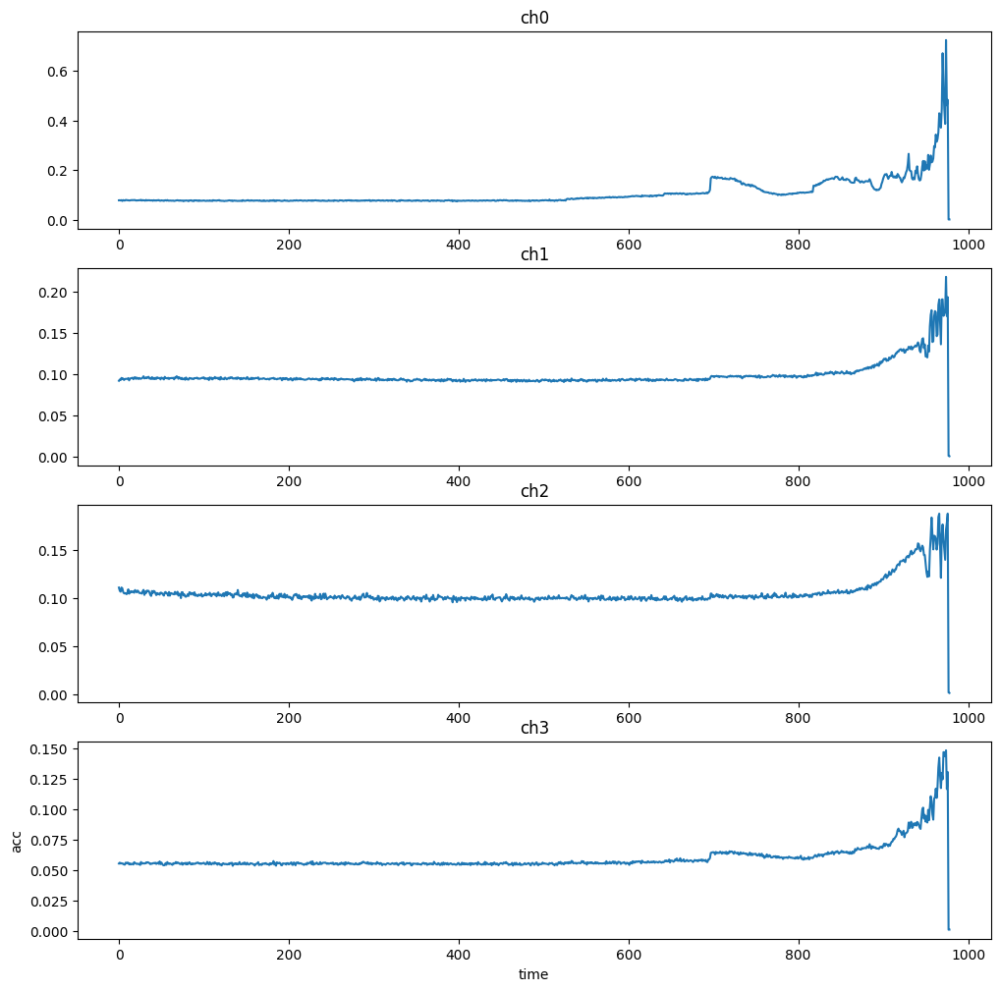

In [ ]:
skip_init_file_std = all_seqs[5:].std(axis=2)
show_with_subplots(skip_init_file_std.T)

Remove first 5 recordings

In [12]:
all_seqs_old = all_seqs.copy()
all_seqs = all_seqs[5:]
all_seqs.shape

(979, 4, 20480)

## Starting, global, and final behavior

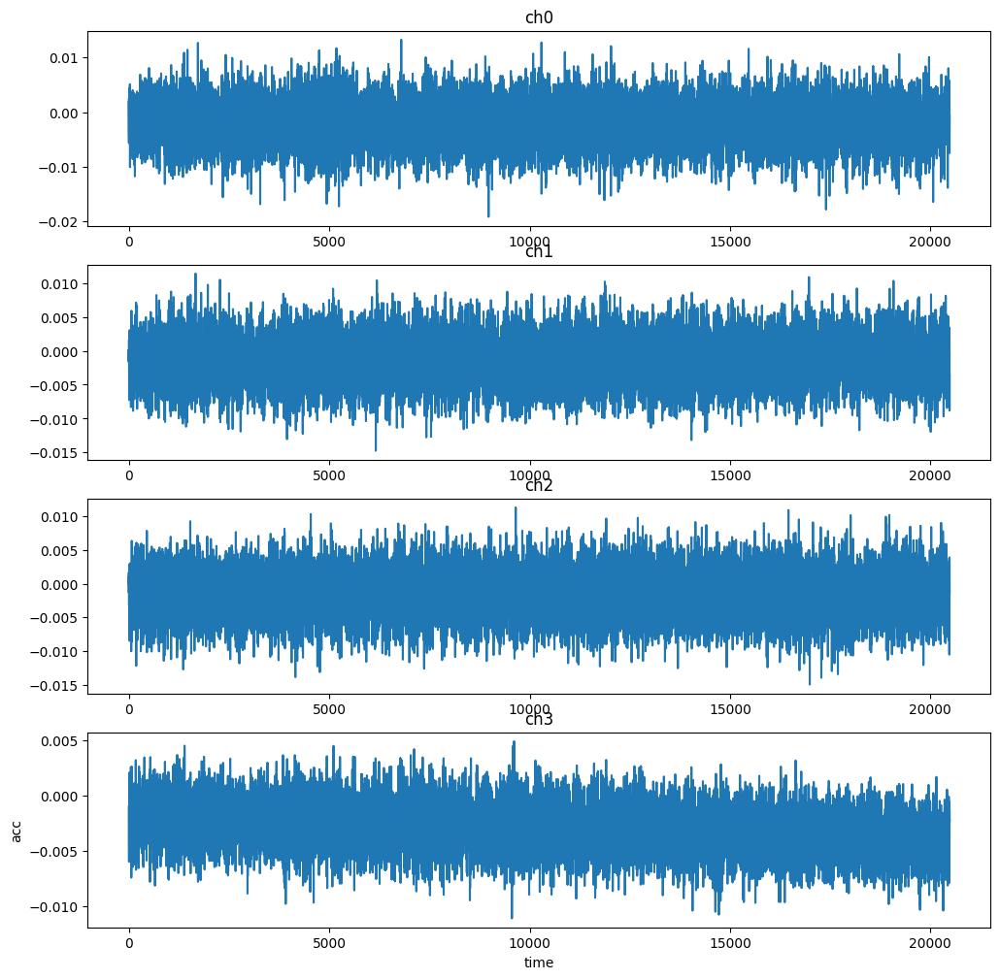

In [218]:
avgs = all_seqs.mean(axis=0)
show_with_subplots(avgs)

First 48 recordings


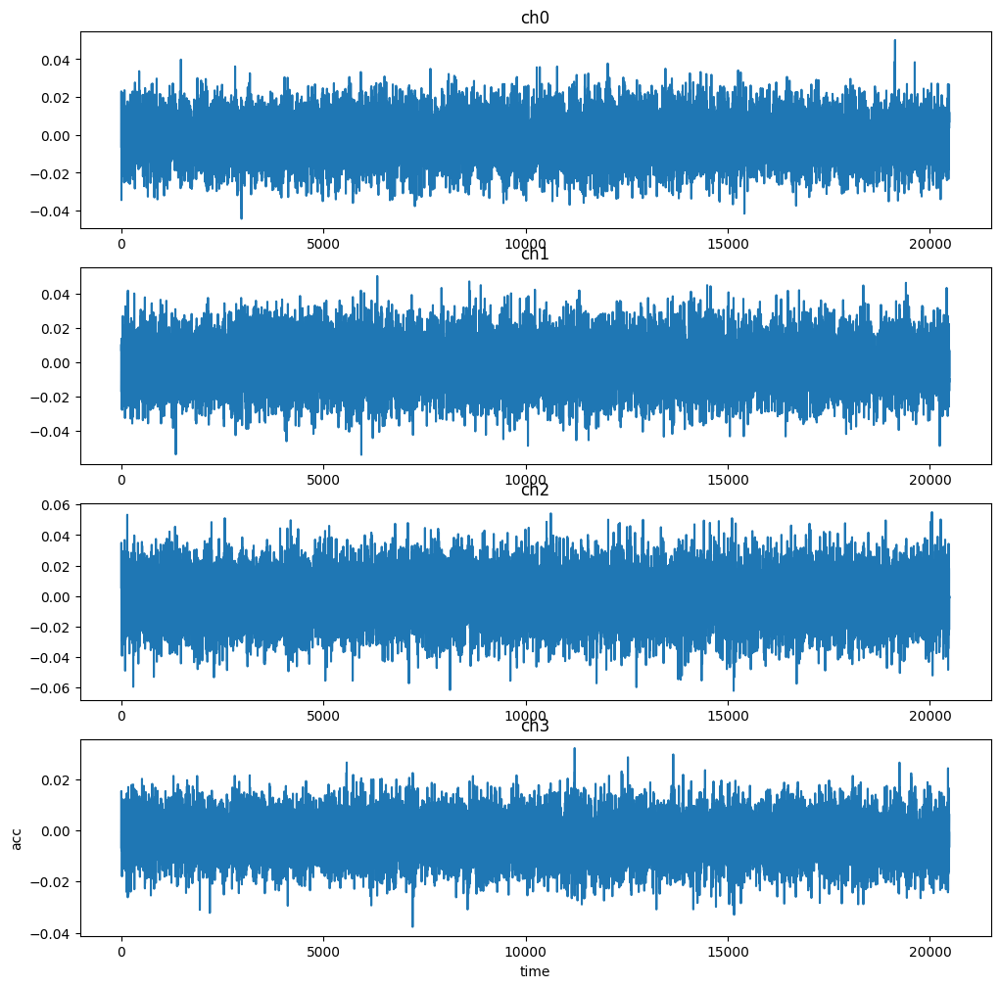

Last 48 recordings


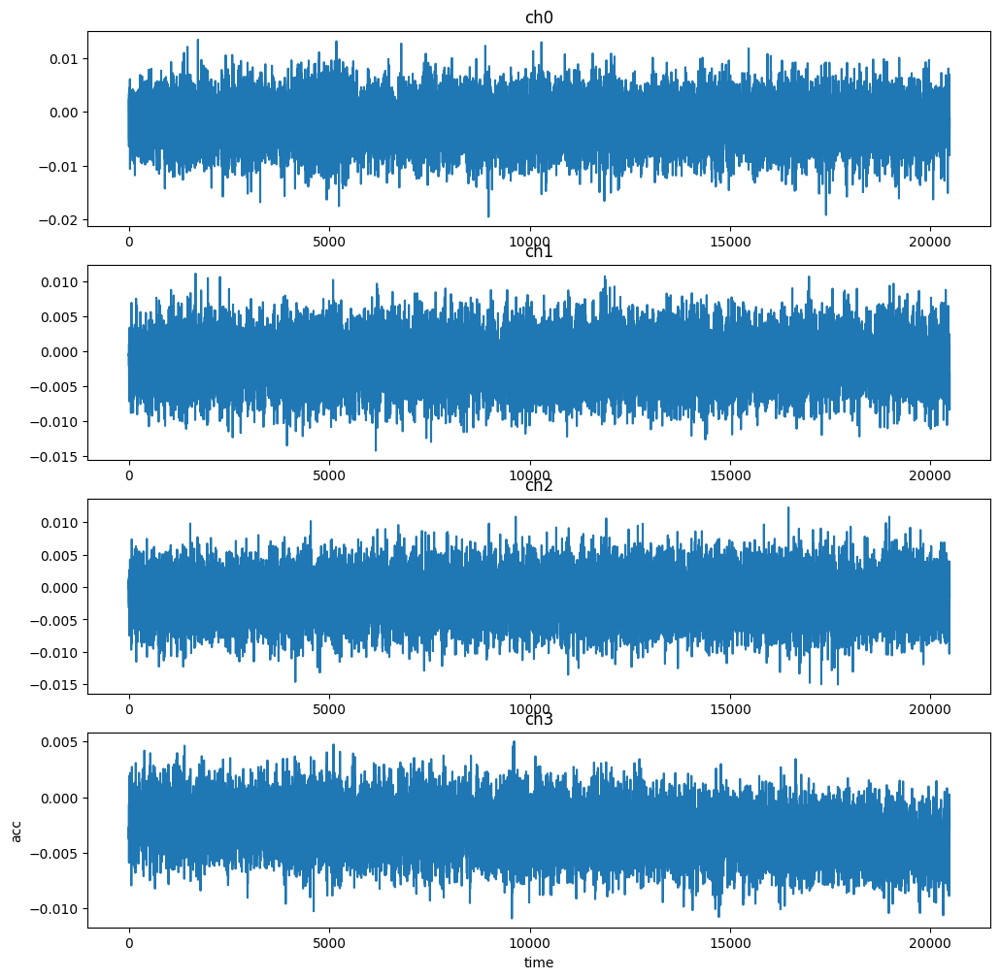

In [219]:
first_k = int(len(all_seqs)*0.05)
print(f'First {first_k} recordings')
early_avgs = all_seqs[:first_k].mean(axis=0)

show_with_subplots(early_avgs)


print(f'Last {first_k} recordings')
final_avgs = all_seqs[first_k:].mean(axis=0)
show_with_subplots(final_avgs)

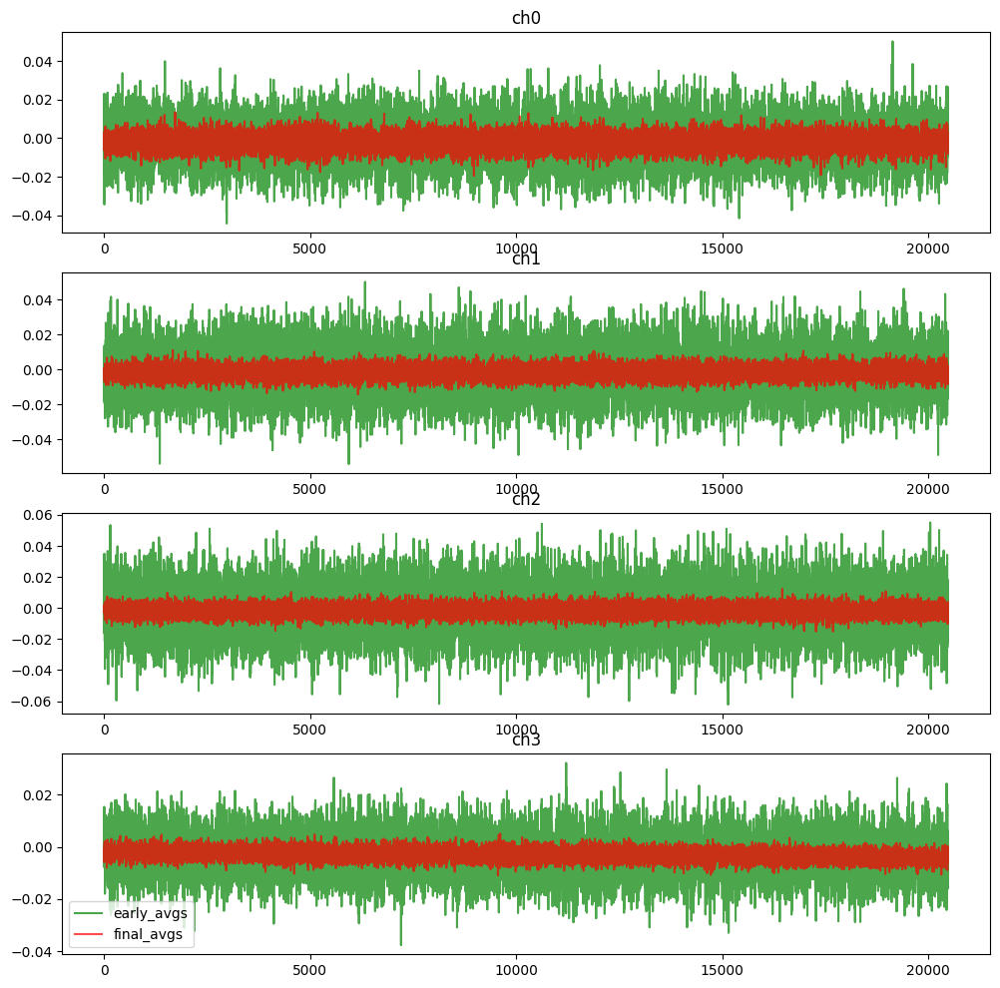

In [ ]:
fig, axs = plt.subplots(4,1, figsize=(12,12))
cols = ['ch0','ch1','ch2','ch3']
# for i, col_name in enumerate(['ch0','ch1','ch2','ch3']):
for i in range(4):
  axs[i].plot(early_avgs[i], c='green', label='early_avgs', alpha=0.7)
  # axs[i].plot(avgs[i], c='blue', label='global_avgs', alpha=0.7)
  axs[i].plot(final_avgs[i], c='red', label='final_avgs', alpha=0.7)

  axs[i].set_title(cols[i])
plt.legend()
plt.show()

In [ ]:
stds = all_seqs.std(axis=0)
stds

array([[0.10668533, 0.11701791, 0.11962213, ..., 0.11643282, 0.11179115,
        0.1202799 ],
       [0.10058798, 0.10224082, 0.09848553, ..., 0.10056575, 0.1013254 ,
        0.10151352],
       [0.10139158, 0.10855082, 0.10281475, ..., 0.10705848, 0.10816529,
        0.10376795],
       [0.0610923 , 0.06056147, 0.05879424, ..., 0.06076215, 0.06142029,
        0.06130873]], shape=(4, 20480))

In [ ]:
stds.shape

(4, 20480)

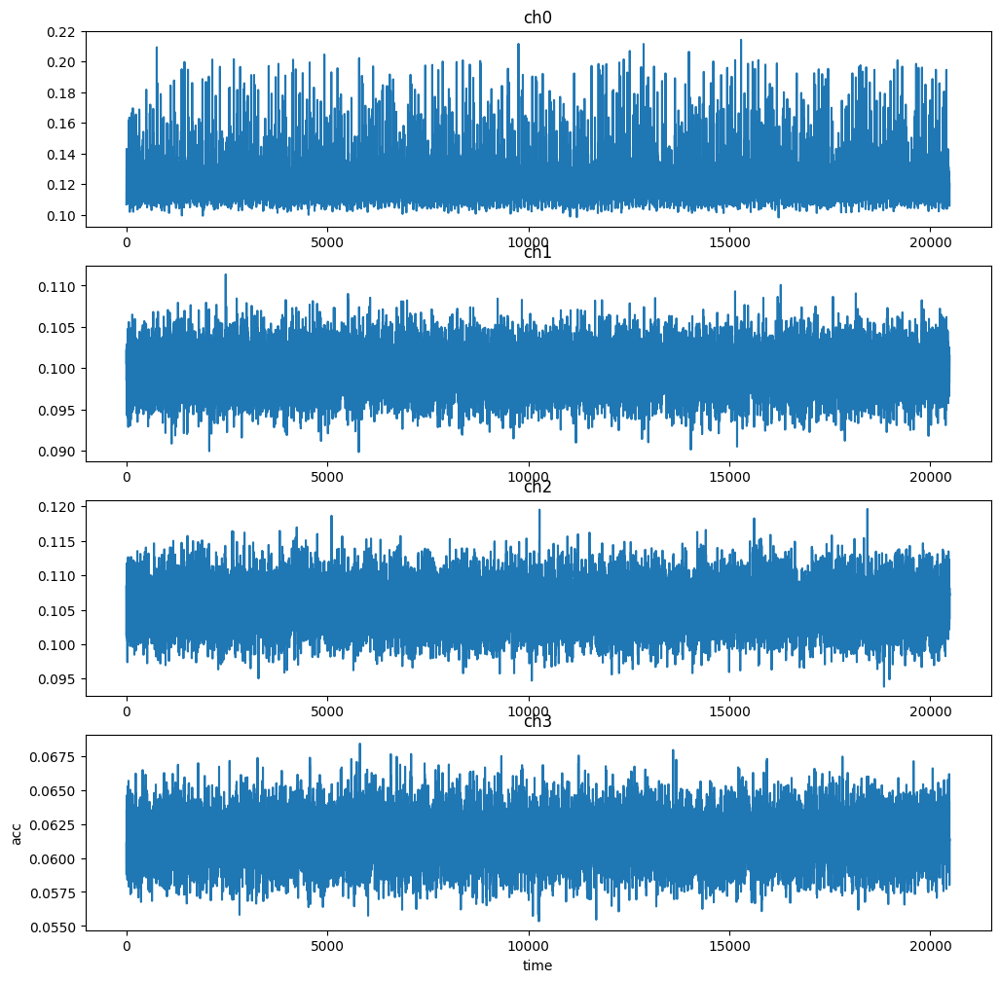

In [ ]:
show_with_subplots(stds)

48


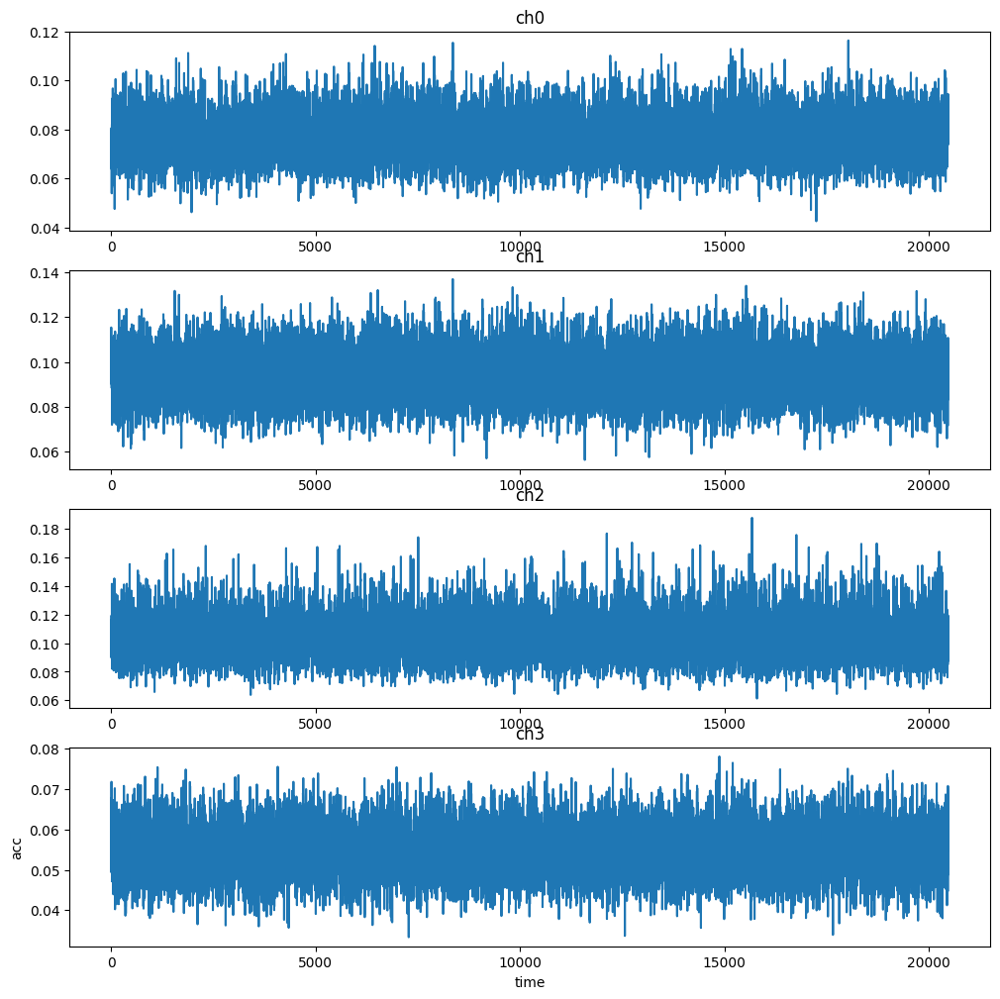

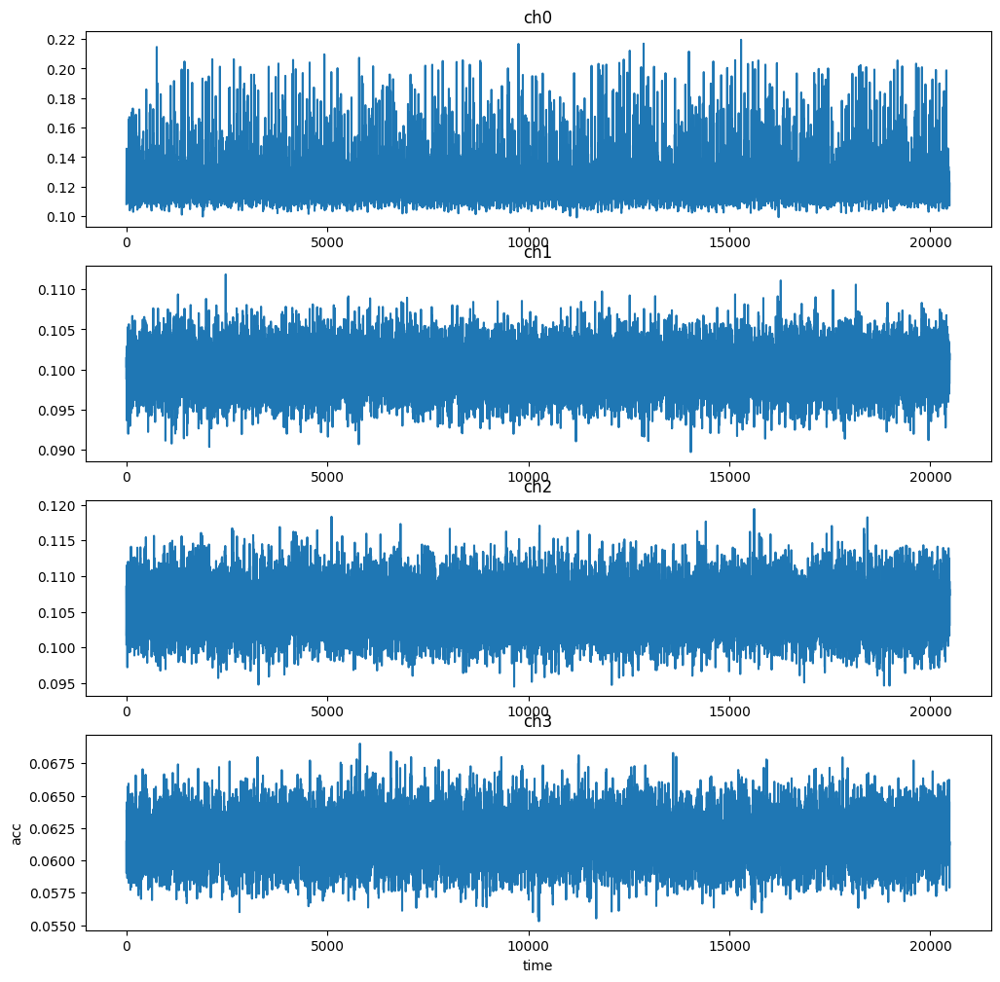

In [217]:
first_k = int(len(all_seqs)*0.05)
print(first_k)
early_stds = all_seqs[:first_k].std(axis=0)

show_with_subplots(early_stds)

print()

final_stds = all_seqs[first_k:].std(axis=0)
show_with_subplots(final_stds)

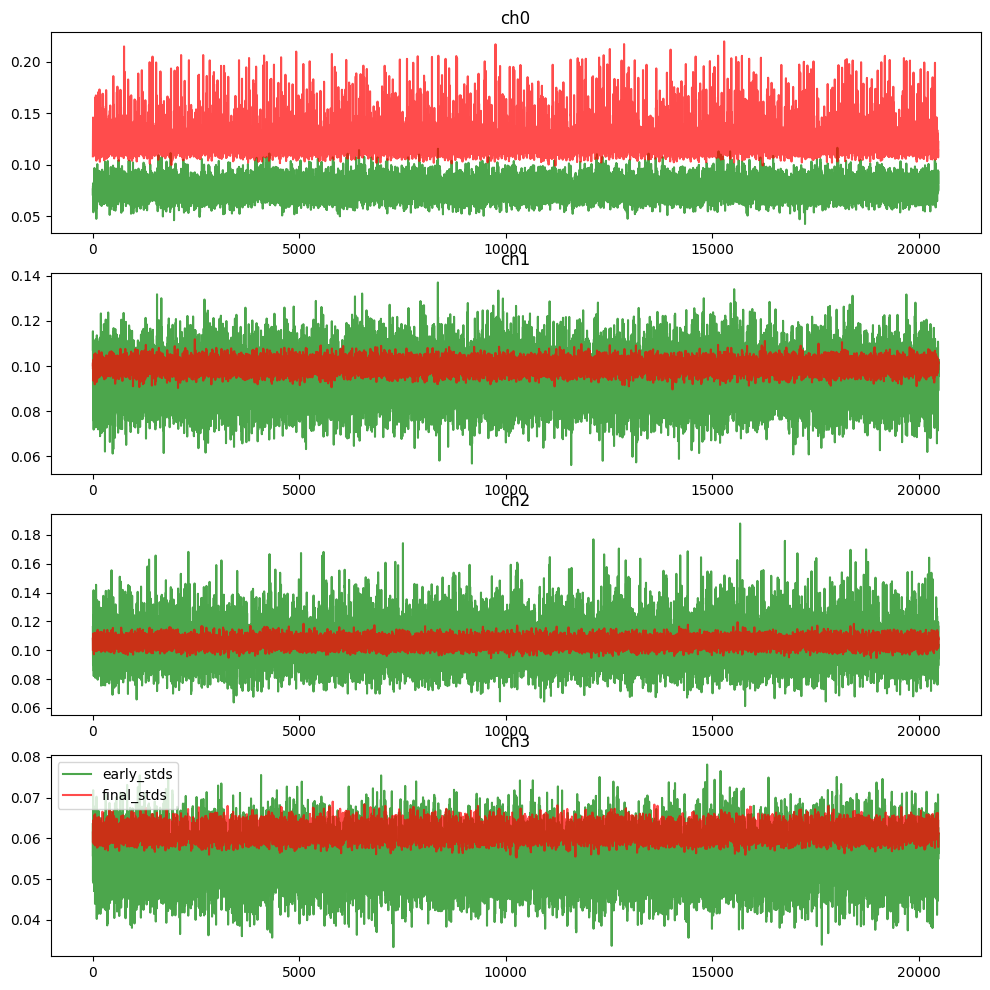

In [ ]:
fig, axs = plt.subplots(4,1, figsize=(12,12))
cols = ['ch0','ch1','ch2','ch3']
for i in range(4):
  axs[i].plot(early_stds[i], c='green', label='early_stds', alpha=0.7)
  axs[i].plot(final_stds[i], c='red', label='final_stds', alpha=0.7)

  axs[i].set_title(cols[i])
plt.legend()
plt.show()

Stationarity check

In [ ]:
"""
CHECK STATIONARITY
"""

def check_stationarity(series):
    result = adfuller(series.dropna())
    print('ADF Statistic:', result[0])
    print('p-value:', result[1])
    print('Critical Values:', result[4])


"""
CHECK STATIONARITY
"""
def check_stationarity(series, kpss_regression='c', verbose=True):
    for col in series.columns:
        print(col, '\n---------')
        seq = series[col].dropna()

        print('ADF (H0: NOT STATIONARY)')
        adf_result = adfuller(seq)
        if adf_result[0] < adf_result[4]['1%']:
            print("REJECT H0 -> STATIONARY")
        else:
            print("CANNOT REJECT H0 -> NOT STATIONARY")
        if verbose:
            print('\tADF Statistic:', adf_result[0])
            print('\tp-value:', adf_result[1])
            adf_critical_values = {k: float(round(v, 5)) for k, v in adf_result[4].items()}
            print('\tCritical Values:', adf_critical_values)
        print()

        # suppress kpss warnings
        import warnings
        warnings.filterwarnings("ignore")
        print(f'KPSS {kpss_regression} (H0: STATIONARY)')
        kpss_result = kpss(seq, regression=kpss_regression, nlags="auto")
        if kpss_result[0] < kpss_result[3]['10%']:
            print("CANNOT REJECT H0 -> STATIONARY")
        else:
            print("REJECT H0 -> NOT STATIONARY")
        if verbose:
            print('\tKPSS Statistic:', kpss_result[0])
            print('\tp-value:', kpss_result[1])
            # print('Lags:', kpss_result[2])
            print('\tCritical Values:', kpss_result[3])
        print('\n')

In [ ]:
early = all_seqs[50]
check_stationarity(pd.DataFrame(early.T, columns=['ch0','ch1','ch2','ch3']))

ch0 
---------
ADF (H0: NOT STATIONARY)
REJECT H0 -> STATIONARY
	ADF Statistic: -10.78244480589098
	p-value: 2.2373153125166104e-19
	Critical Values: {'1%': -3.43067, '5%': -2.86168, '10%': -2.56685}

KPSS c (H0: STATIONARY)
CANNOT REJECT H0 -> STATIONARY
	KPSS Statistic: 0.020017224724315427
	p-value: 0.1
	Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}


ch1 
---------
ADF (H0: NOT STATIONARY)
REJECT H0 -> STATIONARY
	ADF Statistic: -15.68718480195151
	p-value: 1.4485906792706028e-28
	Critical Values: {'1%': -3.43067, '5%': -2.86168, '10%': -2.56685}

KPSS c (H0: STATIONARY)
CANNOT REJECT H0 -> STATIONARY
	KPSS Statistic: 0.02862481452978343
	p-value: 0.1
	Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}


ch2 
---------
ADF (H0: NOT STATIONARY)
REJECT H0 -> STATIONARY
	ADF Statistic: -21.496479551354764
	p-value: 0.0
	Critical Values: {'1%': -3.43067, '5%': -2.86168, '10%': -2.56685}

KPSS c (H0: STATIONARY)
CANNOT REJECT H0 -> STATIO

In [ ]:
late = all_seqs[-5]
check_stationarity(pd.DataFrame(late.T, columns=['ch0','ch1','ch2','ch3']))

ch0 
---------
ADF (H0: NOT STATIONARY)
REJECT H0 -> STATIONARY
	ADF Statistic: -20.790949696235693
	p-value: 0.0
	Critical Values: {'1%': -3.43067, '5%': -2.86168, '10%': -2.56685}

KPSS c (H0: STATIONARY)
REJECT H0 -> NOT STATIONARY
	KPSS Statistic: 0.4730989833655117
	p-value: 0.047725454196956826
	Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}


ch1 
---------
ADF (H0: NOT STATIONARY)
REJECT H0 -> STATIONARY
	ADF Statistic: -22.18359949378064
	p-value: 0.0
	Critical Values: {'1%': -3.43067, '5%': -2.86168, '10%': -2.56685}

KPSS c (H0: STATIONARY)
CANNOT REJECT H0 -> STATIONARY
	KPSS Statistic: 0.004965993868051033
	p-value: 0.1
	Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}


ch2 
---------
ADF (H0: NOT STATIONARY)
REJECT H0 -> STATIONARY
	ADF Statistic: -28.8306080811304
	p-value: 0.0
	Critical Values: {'1%': -3.43067, '5%': -2.86168, '10%': -2.56685}

KPSS c (H0: STATIONARY)
CANNOT REJECT H0 -> STATIONARY
	KPSS Statistic: 0.00

In [ ]:
window_size = 5

for seq in all_data:
  i = 0
  moving_avg = []
  moving_std = []

  #consider every window of size 3
  while i < len(seq) - window_size + 1:

      # Calculate the average of current window
      window_average = round(np.sum(seq[
        i:i+window_size]) / window_size, 2)

      # Store the average of current
      # window in moving average list
      moving_avg.append(window_average)

      # Shift window to right by one position
      i += 1

  print(moving_avg)

Distribution comparison of "normal" (i.e. early) and "anomalous" (i.e. late) recordings

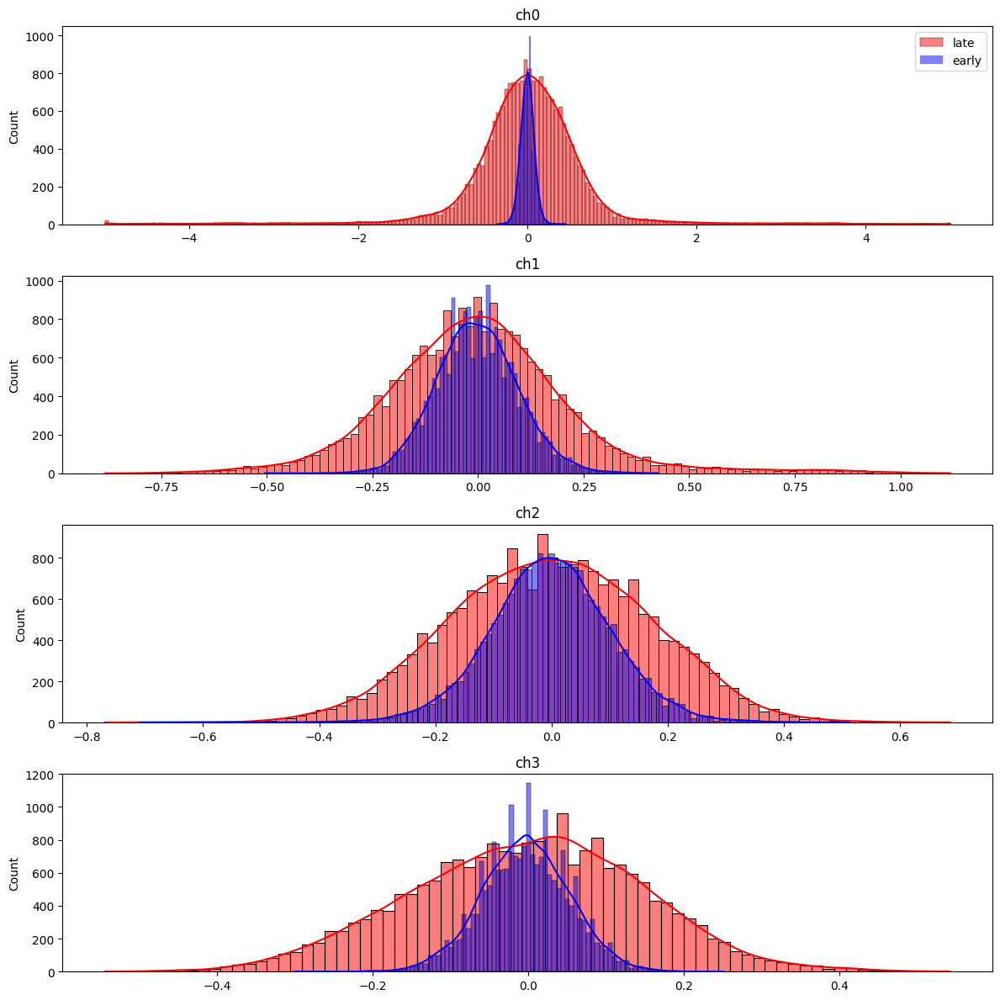

In [ ]:
late = all_seqs[-1]
late = all_seqs[-5]
fig, axs = plt.subplots(4, 1, figsize=(12, 12))
for i in range(4):
  sns.histplot(late[i], kde=True, color='red', ax=axs[i], label='late')
  sns.histplot(early[i], kde=True, color='blue', ax=axs[i], label='early')
  axs[i].set_title(f'ch{i}')
axs[0].legend()
plt.tight_layout()
plt.show()

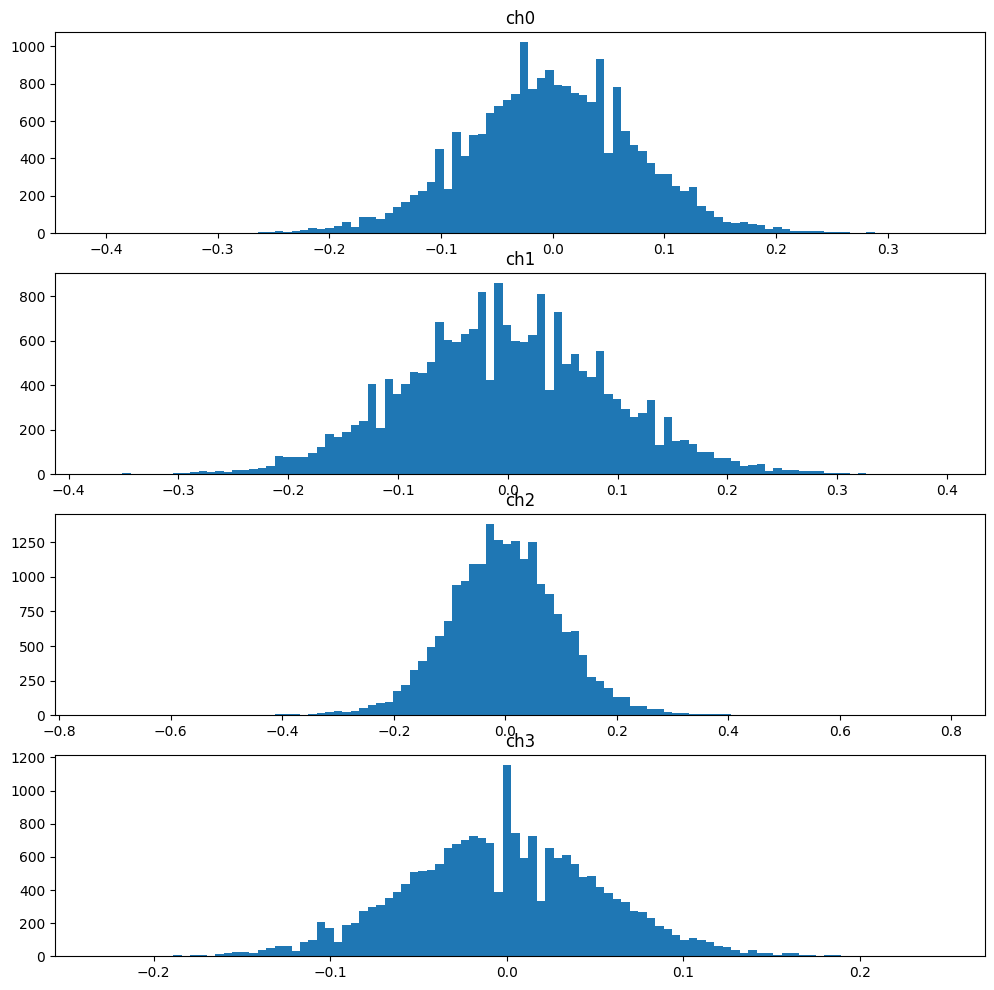

mean = [-0.00188418 -0.00156099 -0.00139307 -0.00270454]
std = [0.07548887 0.09405881 0.10372819 0.05558076]


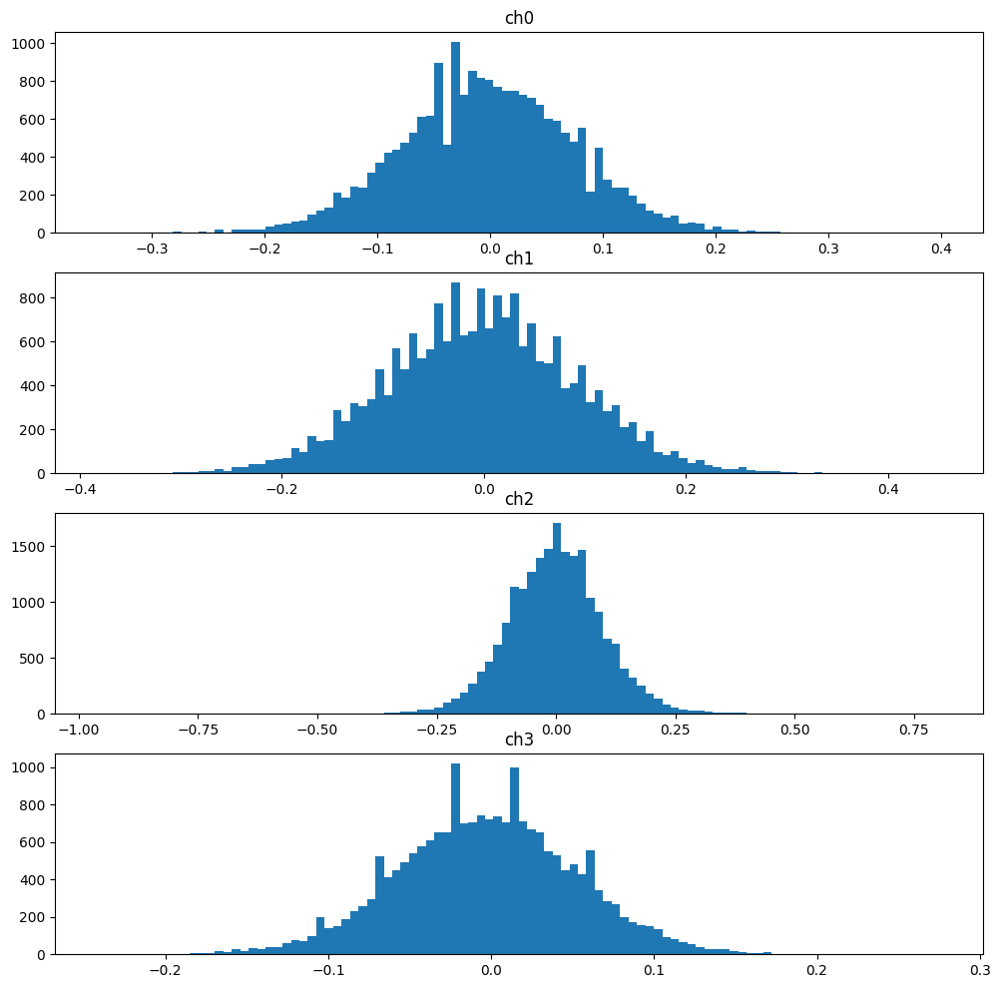

mean = [-0.00181763 -0.00172954 -0.00119419 -0.00255405]
std = [0.07628623 0.09343291 0.10007951 0.05477281]


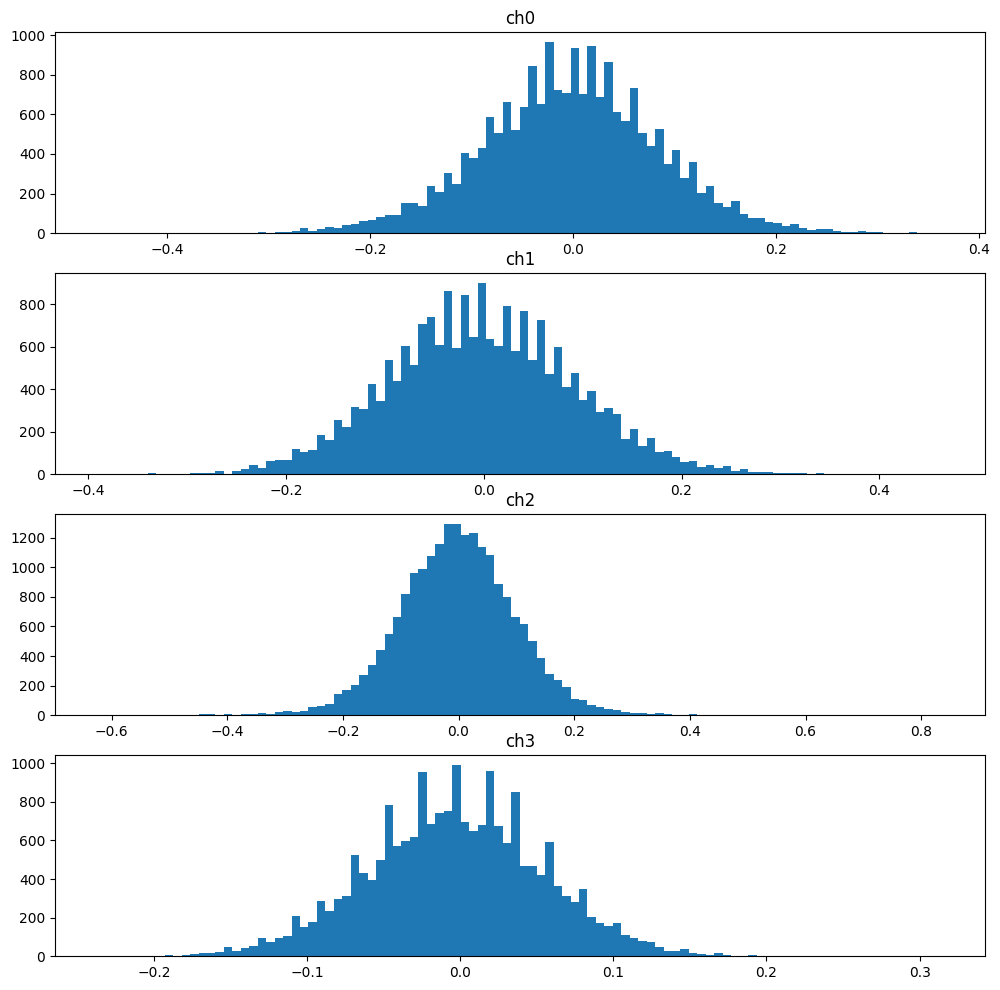

mean = [-0.00235474 -0.00211362 -0.00169106 -0.00309756]
std = [0.08786926 0.09377322 0.1018653  0.05746332]


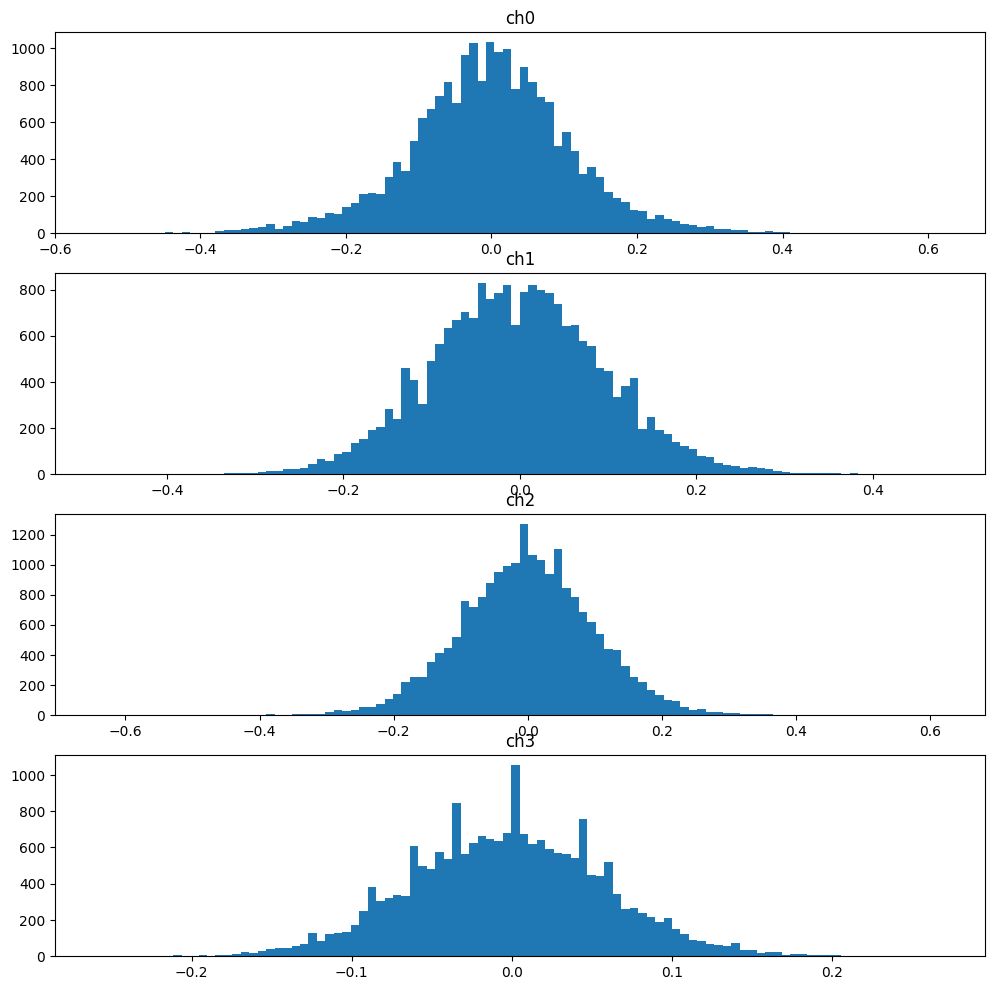

mean = [-0.00157129 -0.00204878 -0.00189556 -0.00276396]
std = [0.11120203 0.09812312 0.10072302 0.06011807]


In [216]:
def plot_distribution(data, title):
  fig,axs=plt.subplots(4,1,figsize=(12,12))
  for i in range(4):
    axs[i].hist(data[i], bins=100)
    axs[i].set_title(f'ch{i}')
  plt.show()

tot_samples=4
for sample_id in sorted(sample(range(0, len(all_seqs)), tot_samples)):
  plot_distribution(all_seqs[sample_id],sample_id)
  means = all_seqs[sample_id].mean(axis=1)
  stds = all_seqs[sample_id].std(axis=1)
  print('mean =', means)
  print('std =', stds)

## Feat engineering

In [ ]:
def __band_power(psd, freqs, f_low, f_high):
    """Integrate PSD between f_low and f_high (inclusive)."""
    idx = (freqs >= f_low) & (freqs < f_high)
    return np.trapezoid(psd[idx], freqs[idx])

def __extract_features_multivariate(sequences):
    """
    sequences: np.ndarray of shape (C, L)
               C = number of independent channels, L = length
    Returns: dict with features per channel (prefixed) + cross-channel features
    """
    C, L = sequences.shape
    feats = {}

    # ----- per-channel features -----
    for c in range(C):
        x = sequences[c].astype(np.float32)
        prefix = f"ch{c}_"

        # time-domain
        mean = np.mean(x)
        std  = np.std(x)
        rms  = np.sqrt(np.mean(x**2))
        x_max, x_min = x.max(), x.min()
        p2p  = x_max - x_min
        skew = pd.Series(x).skew()
        kurt = pd.Series(x).kurtosis()
        mad  = np.median(np.abs(x - np.median(x)))
        crest = x_max / rms if rms else 0.0
        pct_over_3std = (np.abs(x - mean) > 3*std).mean()

        # stationarity
        try:
            adf_p = adfuller(x, maxlag=1, autolag=None).pvalue
        except Exception:
            adf_p = np.nan

        # frequency-domain

        FS      = 20480                 # sampling rate [Hz]
        NPERSEG = 128                 # Welch window length
        BANDS   = [(0,20), (20,40), (40,80), (80,160), (160,512)]
        f, Pxx = welch(x, fs=FS, nperseg=NPERSEG)
        band_powers = [__band_power(Pxx, f, lo, hi) for lo, hi in BANDS]
        low_power  = band_powers[0]
        high_power = band_powers[-1]
        hi_lo_ratio = high_power / low_power if low_power else np.nan

        peak_idx = np.argsort(Pxx)[-2:][::-1]   # two tallest bins
        pk1_f, pk1_a = f[peak_idx[0]], Pxx[peak_idx[0]]
        pk2_f, pk2_a = f[peak_idx[1]], Pxx[peak_idx[1]]

        feats.update({
            prefix+"mean": mean,
            prefix+"std": std,
            prefix+"rms": rms,
            prefix+"max": x_max,
            prefix+"min": x_min,
            prefix+"peak_to_peak": p2p,
            prefix+"skew": skew,
            prefix+"kurtosis": kurt,
            prefix+"mad": mad,
            prefix+"crest_factor": crest,
            prefix+"pct_over_3std": pct_over_3std,
            prefix+"adf_pvalue": adf_p,
            prefix+"band_0_20": band_powers[0],
            prefix+"band_20_40": band_powers[1],
            prefix+"band_40_80": band_powers[2],
            prefix+"band_80_160": band_powers[3],
            prefix+"band_160_512": band_powers[4],
            prefix+"hi_lo_ratio": hi_lo_ratio,
            prefix+"peak1_freq": pk1_f,
            prefix+"peak1_amp": pk1_a,
            prefix+"peak2_freq": pk2_f,
            prefix+"peak2_amp": pk2_a,
        })

    # ----- cross-channel features -----
    if C > 1:
        # correlation matrix (upper triangle only)
        corr = np.corrcoef(sequences)
        upper = corr[np.triu_indices(C, k=1)]
        feats["cross_corr_mean"] = np.nanmean(upper)
        feats["cross_corr_std"]  = np.nanstd(upper)

        # variance ratio across channels (how balanced)
        var_per_ch = sequences.var(axis=1)
        feats["var_ratio_max_min"] = var_per_ch.max() / (var_per_ch.min()+1e-12)

    return feats


In [14]:


# Pre-define constants outside the loop to avoid re-allocation
FS = 20480  # Sampling rate [Hz]
NPERSEG = 128  # Welch window length
BANDS = [(0, 20), (20, 40), (40, 80), (80, 160), (160, 512)]


def _extract_single_file_features(args):
  """Worker function to extract features for a single file (runs in parallel)."""
  file_idx, sequences = args
  C, L = sequences.shape
  feats = {}

  # Pre-compute Welch once per file if possible, or per channel
  # (Welch on 20480 points with nperseg=128 is fast, but we can optimize band extraction)

  for c in range(C):
    x = sequences[c].astype(np.float32)
    prefix = f'ch{c}_'

    # ----- Time-domain (Vectorized via NumPy/SciPy) -----
    mean = np.mean(x)
    std = np.std(x)
    rms = np.sqrt(np.mean(x**2))
    x_max, x_min = x.max(), x.min()
    p2p = x_max - x_min

    # Fast NumPy-native skew & kurtosis (replaces pd.Series overhead)
    sk = skew(x)
    kur = kurtosis(x)  # Fisher's definition (normal = 0) or Pearson's depending on version

    median_x = np.median(x)
    mad = np.median(np.abs(x - median_x))
    crest = x_max / rms if rms > 0 else 0.0
    pct_over_3std = np.mean(np.abs(x - mean) > 3 * std)

    # ----- Stationarity -----
    try:
      adf_p = adfuller(x, maxlag=1, autolag=None).pvalue
    except Exception:
      # assumption
      adf_p = 1.0

    # ----- Frequency-domain (Welch) -----
    f, Pxx = welch(x, fs=FS, nperseg=NPERSEG)

    # Vectorized band power calculation using vectorized NumPy search
    band_powers = np.empty(len(BANDS))
    for b_idx, (lo, hi) in enumerate(BANDS):
      idx = (f >= lo) & (f < hi)
      band_powers[b_idx] = np.trapezoid(Pxx[idx], f[idx]) if np.any(idx) else 0.0

    low_power = band_powers[0]
    high_power = band_powers[-1]
    hi_lo_ratio = high_power / (low_power + 1e-12)

    # Two tallest peaks in PSD
    peak_idx = np.argsort(Pxx)[-2:][::-1]
    pk1_f, pk1_a = f[peak_idx[0]], Pxx[peak_idx[0]]
    pk2_f, pk2_a = f[peak_idx[1]], Pxx[peak_idx[1]]

    feats.update({
        prefix + 'mean': mean,
        prefix + 'std': std,
        prefix + 'rms': rms,
        prefix + 'max': x_max,
        prefix + 'min': x_min,
        prefix + 'peak_to_peak': p2p,
        prefix + 'skew': sk,
        prefix + 'kurtosis': kur,
        prefix + 'mad': mad,
        prefix + 'crest_factor': crest,
        prefix + 'pct_over_3std': pct_over_3std,
        prefix + 'adf_pvalue': adf_p,
        # prefix + 'band_0_20': band_powers[0],
        # prefix + 'band_20_40': band_powers[1],
        # prefix + 'band_40_80': band_powers[2],
        # prefix + 'band_80_160': band_powers[3],
        # prefix + 'band_160_512': band_powers[4],
        prefix + 'hi_lo_ratio': hi_lo_ratio,
        prefix + 'peak1_freq': pk1_f,
        prefix + 'peak1_amp': pk1_a,
        prefix + 'peak2_freq': pk2_f,
        prefix + 'peak2_amp': pk2_a,
    })

  # ----- Cross-channel features -----
  if C > 1:
    corr = np.corrcoef(sequences)
    upper = corr[np.triu_indices(C, k=1)]
    feats['cross_corr_mean'] = np.nanmean(upper)
    feats['cross_corr_std'] = np.nanstd(upper)

    var_per_ch = sequences.var(axis=1)
    feats['var_ratio_max_min'] = var_per_ch.max() / (var_per_ch.min() + 1e-12)

  return file_idx, feats


def extract_features_parallel(all_seqs):
  n_files = all_seqs.shape[0]
  feature_list = [None] * n_files

  tasks = [(i, all_seqs[i]) for i in range(n_files)]

  print(f'Extracting features across {n_files} files in parallel...')
  with ProcessPoolExecutor() as executor:
    futures = [
        executor.submit(_extract_single_file_features, task) for task in tasks
    ]

    for future in tqdm(as_completed(futures), total=n_files):
      file_idx, feats = future.result()
      feature_list[file_idx] = feats

  return pd.DataFrame(feature_list)

X_features = extract_features_parallel(all_seqs)

Extracting features across 979 files in parallel...


Output streaming troncato alle ultime 5000 righe.
/tmp/ipykernel_1556/2464044573.py:38: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(x, maxlag=1, autolag=None).pvalue
/tmp/ipykernel_1556/2464044573.py:38: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(x, maxlag=1, autolag=None).pvalue
 36%|███▌      | 354/979 [01:33<03:23,  3.08it/s]/tmp/

In [ ]:
# Assume data_3d is your loaded array of shape (N_files, 4_axes, M_measurements)
n_files, n_axes, n_measurements = all_seqs.shape


feature_list = []
for i in trange(n_files):
  feature_list.append(__extract_features_multivariate(all_seqs[i]))

X_features = pd.DataFrame(feature_list)

  3%|▎         | 34/979 [00:06<03:07,  5.04it/s]


KeyboardInterrupt: 

In [ ]:
cols_to_drop = [f'ch{ch}_{band}' for band in ['band_0_20','band_20_40','band_40_80','band_80_160','band_160_512'] for ch in range(4)]
cols_to_drop
X_slim = X_features.drop(columns=cols_to_drop)
X_slim.shape

KeyError: "['ch0_band_0_20', 'ch1_band_0_20', 'ch2_band_0_20', 'ch3_band_0_20', 'ch0_band_20_40', 'ch1_band_20_40', 'ch2_band_20_40', 'ch3_band_20_40', 'ch0_band_40_80', 'ch1_band_40_80', 'ch2_band_40_80', 'ch3_band_40_80', 'ch0_band_80_160', 'ch1_band_80_160', 'ch2_band_80_160', 'ch3_band_80_160', 'ch0_band_160_512', 'ch1_band_160_512', 'ch2_band_160_512', 'ch3_band_160_512'] not found in axis"

<Axes: >

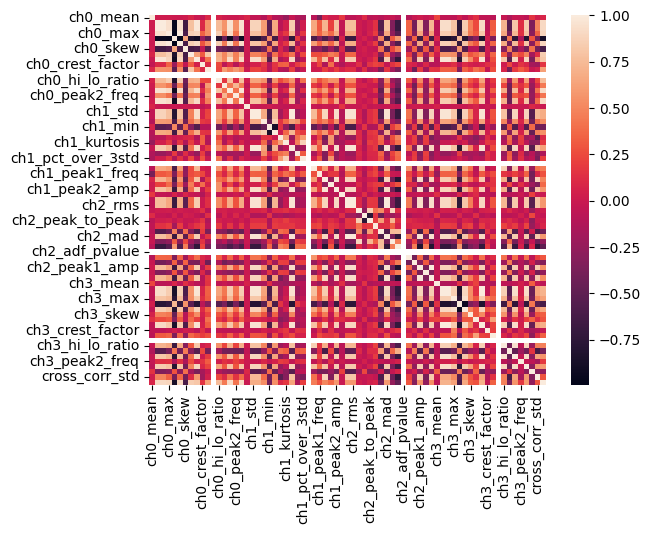

In [ ]:
sns.heatmap(X_features.corr())

<Axes: >

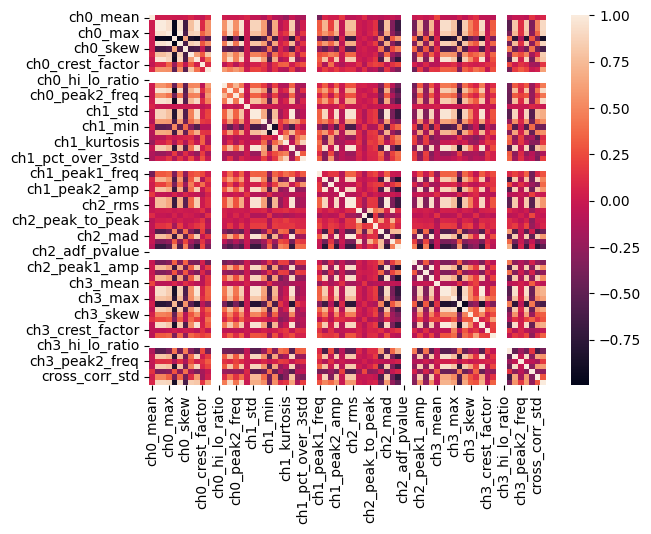

In [ ]:
sns.heatmap(X_slim.corr())

# Sequence Detectors

In [15]:
seqs_means = all_seqs.mean(axis=2)
seqs_stds = all_seqs.std(axis=2)

def plot_seq_preds(preds, method_name, convolve=False):
  x_axis = np.arange(preds.shape[0])
  fig, axs = plt.subplots(4,2,figsize=(18,15))
  if preds.shape != seqs_stds.shape:
    preds = np.broadcast_to(preds[:, None], seqs_stds.shape)
  for ch in range(4):

    anom_indices = np.where(preds[:, ch])[0]

    seq_mean = seqs_means[:,ch]
    normal_mean = np.where(~preds[:,ch].astype(bool), seq_mean, np.nan)
    anom_mean = np.where(preds[:,ch].astype(bool), seq_mean, np.nan)

    seq_std = seqs_stds[:,ch]
    normal_std = np.where(~preds[:,ch].astype(bool), seq_std, np.nan)
    anom_std = np.where(preds[:,ch].astype(bool), seq_std, np.nan)

    axs[ch][0].plot(x_axis, normal_mean, c='green', label='normal')
    axs[ch][0].plot(x_axis, anom_mean, c='red', label='anomaly')
    axs[ch][0].title.set_text(f'ch_{ch}')
    axs[ch][0].set_ylabel('Mean')

    axs[ch][1].plot(x_axis, normal_std, c='green', label='normal')
    axs[ch][1].plot(x_axis, anom_std, c='red', label='anomaly')
    axs[ch][1].title.set_text(f'ch_{ch}')
    axs[ch][1].set_ylabel('Std Dev')

    if len(anom_indices) > 0:
      if convolve:
        sustained = np.convolve(preds[:, ch].astype(int), np.ones(3, dtype=int), mode='valid') == 3
        anom_indices = np.where(sustained)[0]
      first_anom_id = anom_indices[0]
      axs[ch][0].scatter(x_axis[first_anom_id], seq_mean[first_anom_id], c='purple', s=80, zorder=5, label='first anomaly')
      axs[ch][1].scatter(x_axis[first_anom_id], seq_std[first_anom_id], c='purple', s=80, zorder=5, label='first anomaly')


  plt.suptitle(f'{method_name} Predictions - Recording Mean & Std Dev over Time')
  plt.xlabel('Sequence')
  plt.legend()
  plt.tight_layout()
  plt.show()

In [16]:
def compute_thresholds(scores):
  thresh_3std = np.mean(scores) + 3*np.std(scores)
  thresh_99perc = np.percentile(scores, 99)
  return {
    'thresh_3std': thresh_3std,
    'thresh_99perc': thresh_99perc
  }

In [ ]:
def compute_thresh_and_plot_preds(anomaly_scores, model_name, baseline_size, convolve=False):
  thresh_preds = {}
  for thr_name,thr_val in compute_thresholds(anomaly_scores[:baseline_size]).items():
    is_anom = anomaly_scores > thr_val
    plot_seq_preds(is_anom, f'{thr_name} ({thr_val:.5f}) - {model_name}', convolve=convolve)
    thresh_preds[thr_name]= is_anom
  return thresh_preds

## LOF

In [ ]:


class LofDetector():
  # n_neighbors': [10, 20, 35, 50, 75],
  # 'metric': ['euclidean', 'manhattan'],
  def __init__(self, novelty=False, n_neighbors=20, metric='euclidean', contamination='auto'):
    self.model = LocalOutlierFactor(novelty=novelty, n_neighbors=n_neighbors, metric=metric, contamination=contamination)
    self.novelty=novelty
    self.contamination=contamination
    self.n_neighbors = self.model.n_neighbors
    self.metric = self.model.metric

  def _extract_labels(self, predictions):
    return np.where(predictions==1,0,1)

  def score_samples(self, X):
    if self.novelty:
      return self.model.score_samples(X)

  def fit(self, X):
    if self.novelty:
      return self.model.fit(X)

  def predict(self, X):
    if self.novelty:
      labels = self.model.predict(X)
      return self._extract_labels(labels)

  def fit_predict(self, X):
    labels = self.model.fit_predict(X)
    return self._extract_labels(labels)

### Unsup

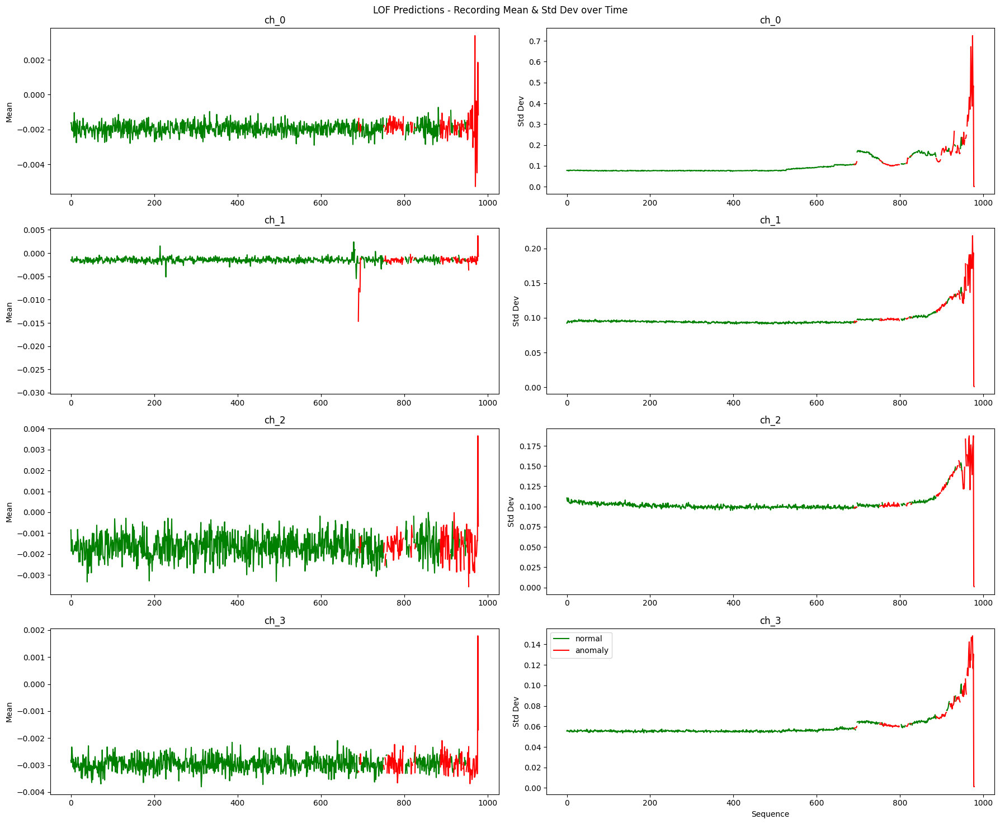

In [ ]:
k_baseline = 50
scaler = StandardScaler()
scaler.fit(X_features[:k_baseline])

X_scaled = scaler.transform(X_features)

lof = LofDetector()
preds = lof.fit_predict(X_scaled)

plot_seq_preds(preds, 'LOF')

### Novelty

Total anomalous files flagged: 466 out of 979


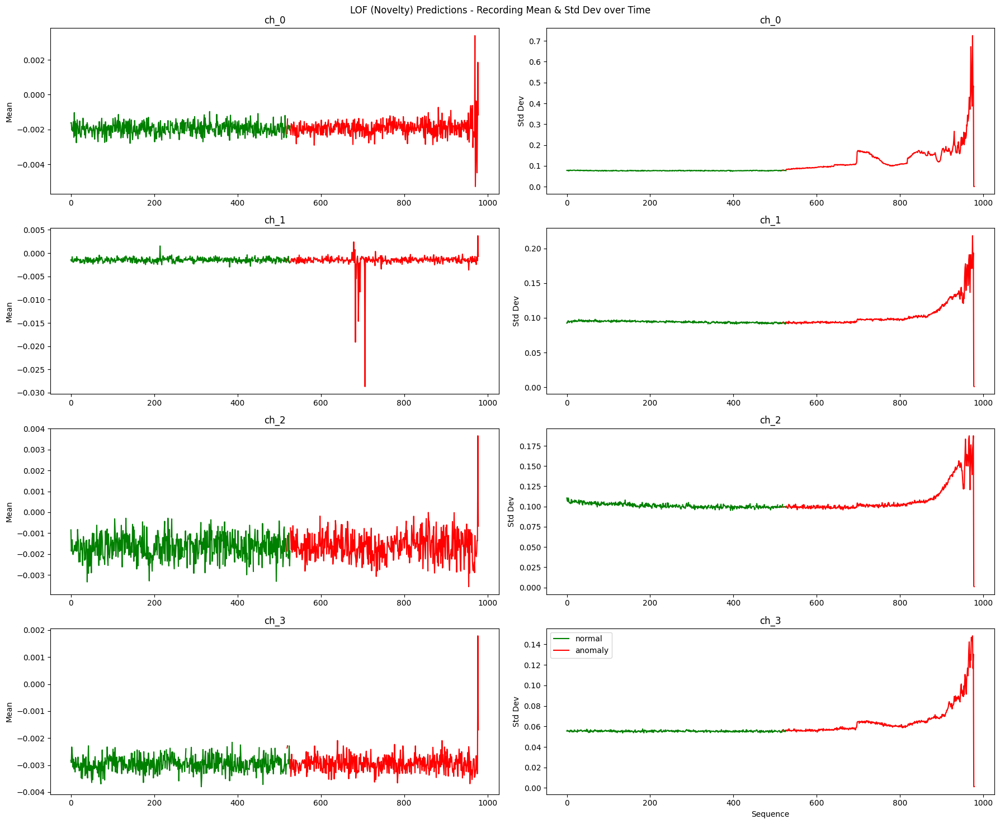

In [ ]:
k_baseline = 150
scaler = StandardScaler()
scaler.fit(X_features[:k_baseline])

X_scaled = scaler.transform(X_features)
X_baseline = X_scaled[:k_baseline]

# 3. Initialize LOF with novelty=True (allows scoring new/unseen files)
lof = LofDetector(contamination='auto', novelty=True)

# 4. Fit ONLY on the healthy baseline
lof.fit(X_baseline)

# 5. Score the entire dataset (or future files)
# score_samples returns negative outlier factor (lower/more negative = more anomalous)
raw_scores = lof.score_samples(X_scaled)
anomaly_scores = -raw_scores  # Convert so higher = more anomalous

predictions = lof.predict(X_scaled)
anomalous_mask = predictions.astype(bool)

print(f'Total anomalous files flagged: {anomalous_mask.sum()} out of {len(X_scaled)}')

plot_seq_preds(anomalous_mask, 'LOF (Novelty)')

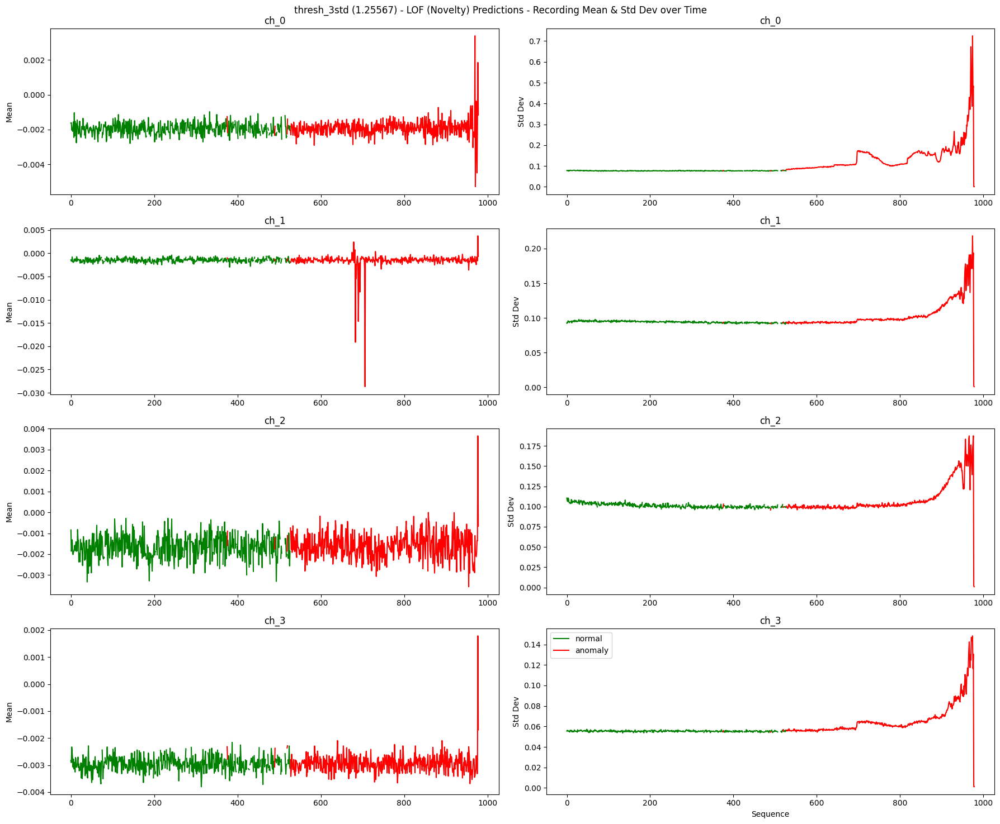

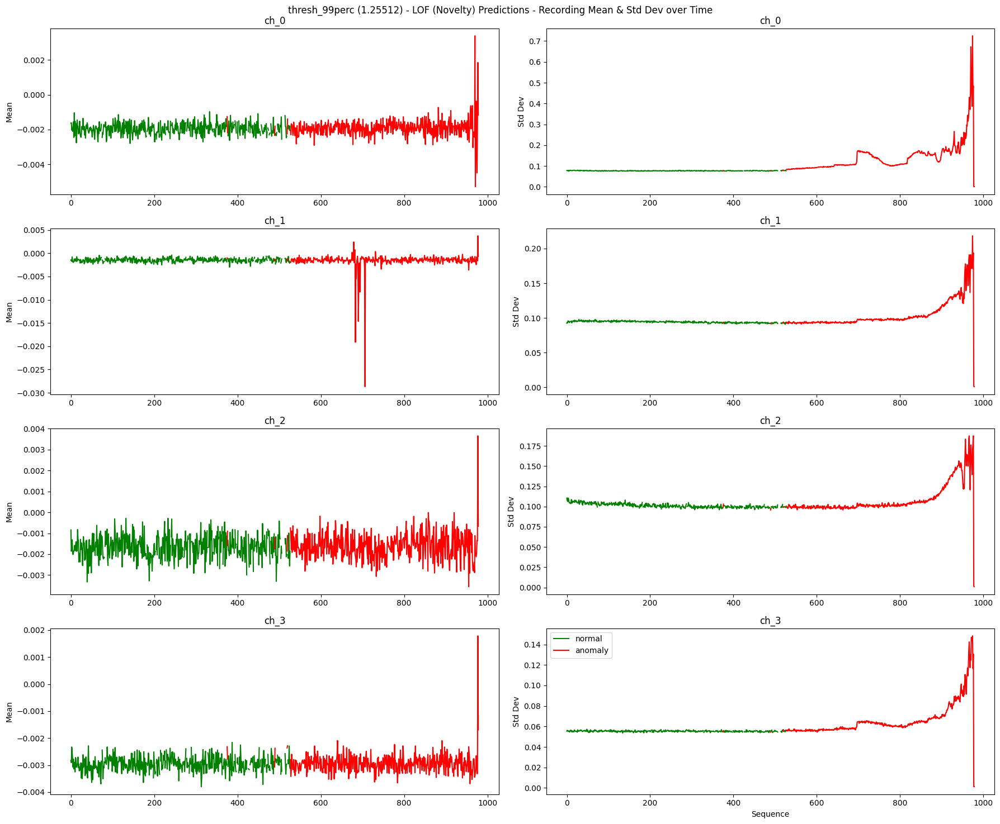

In [ ]:
compute_thresh_and_plot_preds(anomaly_scores, 'LOF (Novelty)', k_baseline)

## IsolationForest

In [ ]:
from sklearn.ensemble import IsolationForest

# 2. Establish the Healthy Baseline
# Let's assume the first 5% of the test files represent normal operation
k_baseline = 150
scaler = StandardScaler()
scaler.fit(X_features[:k_baseline])
X_scaled = scaler.transform(X_features)
X_baseline = X_scaled[:k_baseline]

# 3. Train an Anomaly/Novelty Detection model on the baseline
# IsolationForest with 'novelty=True' learns what "normal" looks like
model = IsolationForest(contamination='auto', random_state=42)
model.fit(X_scaled)

# 4. Score all files (lower or negative scores indicate higher anomaly/degradation)
# decision_function returns anomaly score (higher = more normal, lower/negative = more anomalous)
if_anomaly_scores = -model.decision_function(X_features)

# Alternatively, convert to a 0-to-1 degradation health index (0 = healthy, 1 = failed)
# Using negative decision function normalized
raw_scores = -if_anomaly_scores
health_index = (raw_scores - raw_scores.min()) / (raw_scores.max() - raw_scores.min())

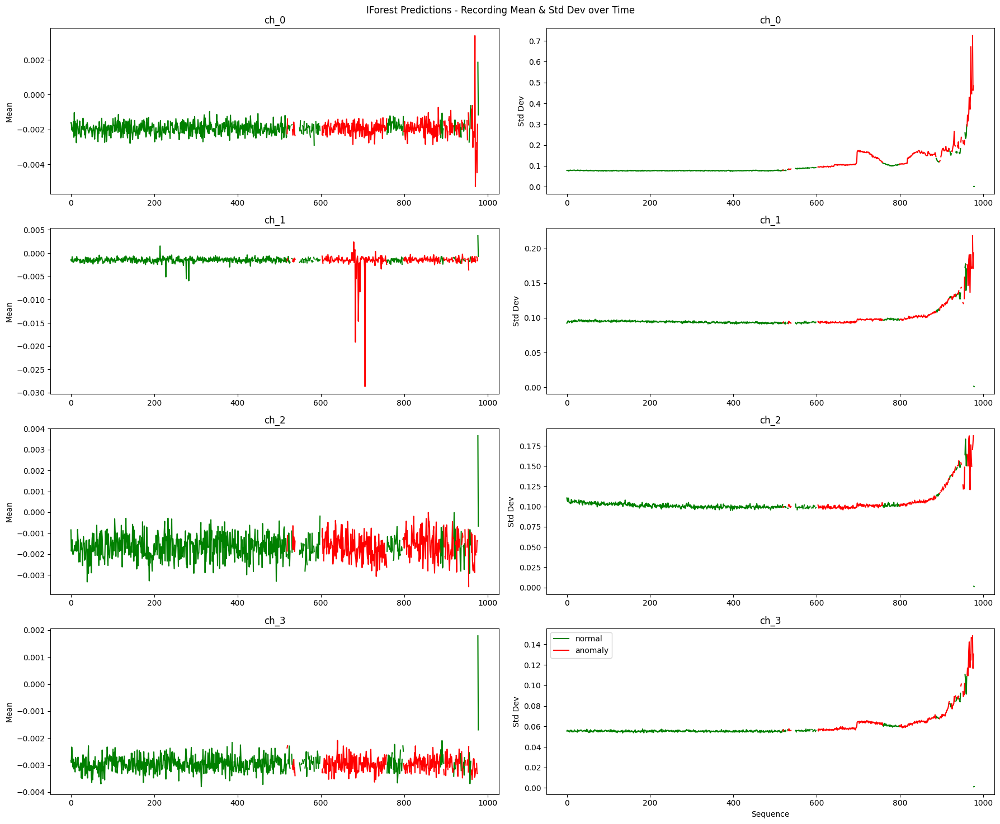

In [ ]:
is_anom = model.predict(X_features)==-1
plot_seq_preds(is_anom, f'IForest')

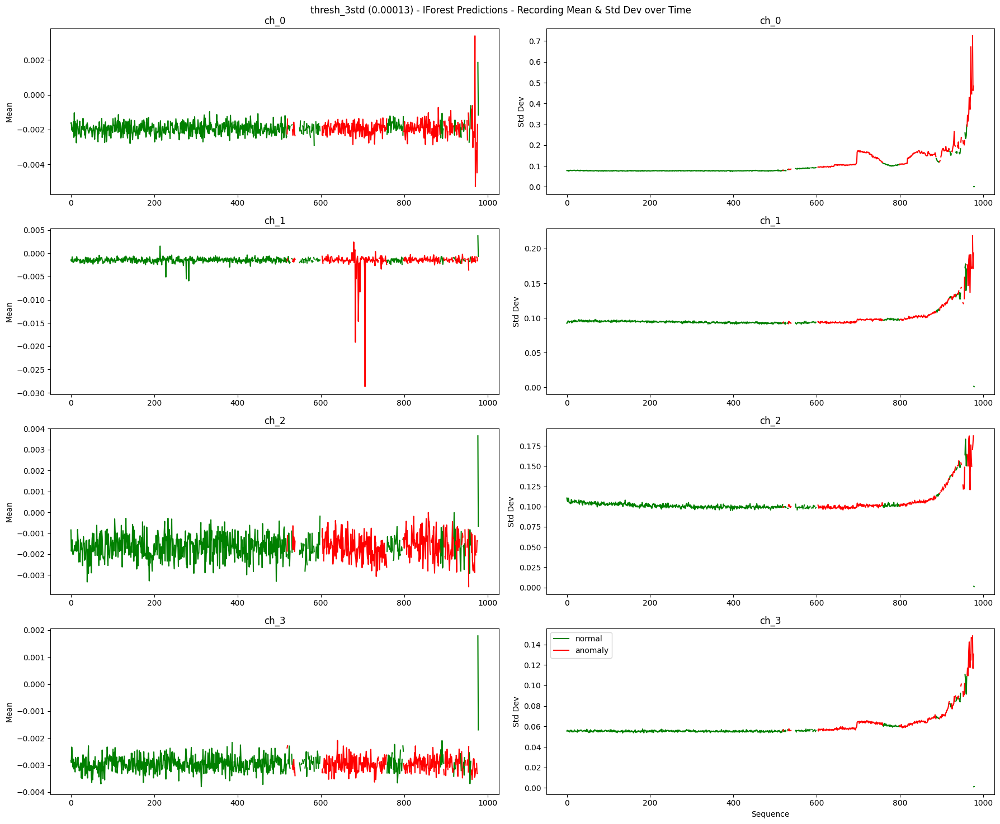

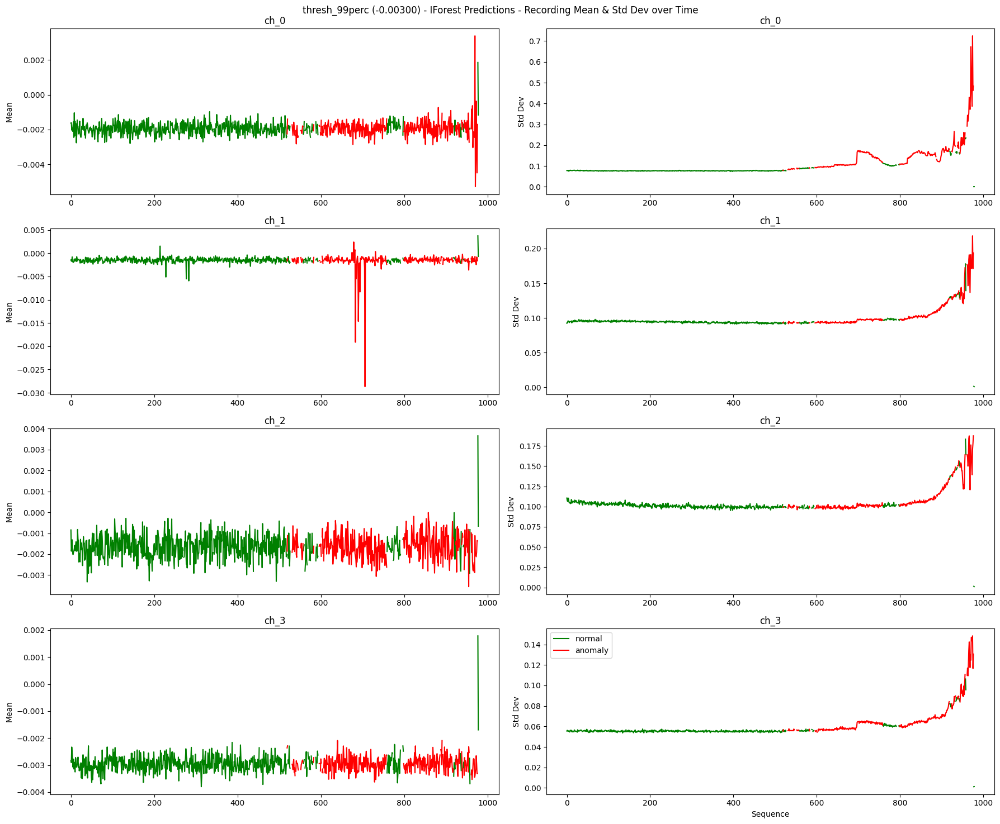

In [ ]:
compute_thresh_and_plot_preds(if_anomaly_scores, 'IForest', k_baseline)

## OneClass SVM

In [214]:
from sklearn.svm import OneClassSVM
import numpy as np

class FeatEngOCSVM():
    def __init__(self, model=None, kernel='rbf', nu=0.01, gamma='scale'):
        self.model = OneClassSVM(kernel=kernel, nu=nu, gamma=gamma)
        self.fitted = False

        self.gamma = self.model.gamma if self.model.gamma in ['scale', 'auto'] else float(self.model.gamma)
        self.nu = self.model.nu
        self.kernel = self.model.kernel
        self.model_name = self.__class__.__name__
        self.fitted = False
        self.__supports = None  # to store support vectors after fitting

    def fit(self, X):
        self.model.fit(X)
        self.fitted = True
        self.__supports = self.model.support_vectors_

    @property
    def supports(self):
        if not self.fitted:
            raise RuntimeError("The model must be fitted before accessing support vectors.")
        return self.__supports

    def decision_function(self, X):
        # X: precomputed kernel matrix between test samples and support vectors
        scores = self.model.decision_function(X)
        return scores

    def predict(self, X):
        if not self.fitted:
            raise RuntimeError("The model must be fitted before prediction.")
        pred_scores = self.model.predict(X)
        pred_labels = self._extract_labels(pred_scores)
        return pred_labels

    def score_samples(self, X):
        return self.model.score_samples(X)

    def _extract_labels(self, df_results):
        return np.where(df_results > 0, 0, 1)

In [ ]:
import plotly.express as px
px.line(seqs_stds[:,0])

In [215]:
from sklearn.preprocessing import RobustScaler

k_baseline = 150
scaler = RobustScaler()
scaler.fit(X_features[:k_baseline])
X_scaled = scaler.transform(X_features)
X_baseline = X_scaled[:k_baseline]

ocsvm = FeatEngOCSVM()
ocsvm.fit(X_baseline)

ocsvm_scores = -ocsvm.decision_function(X_scaled)

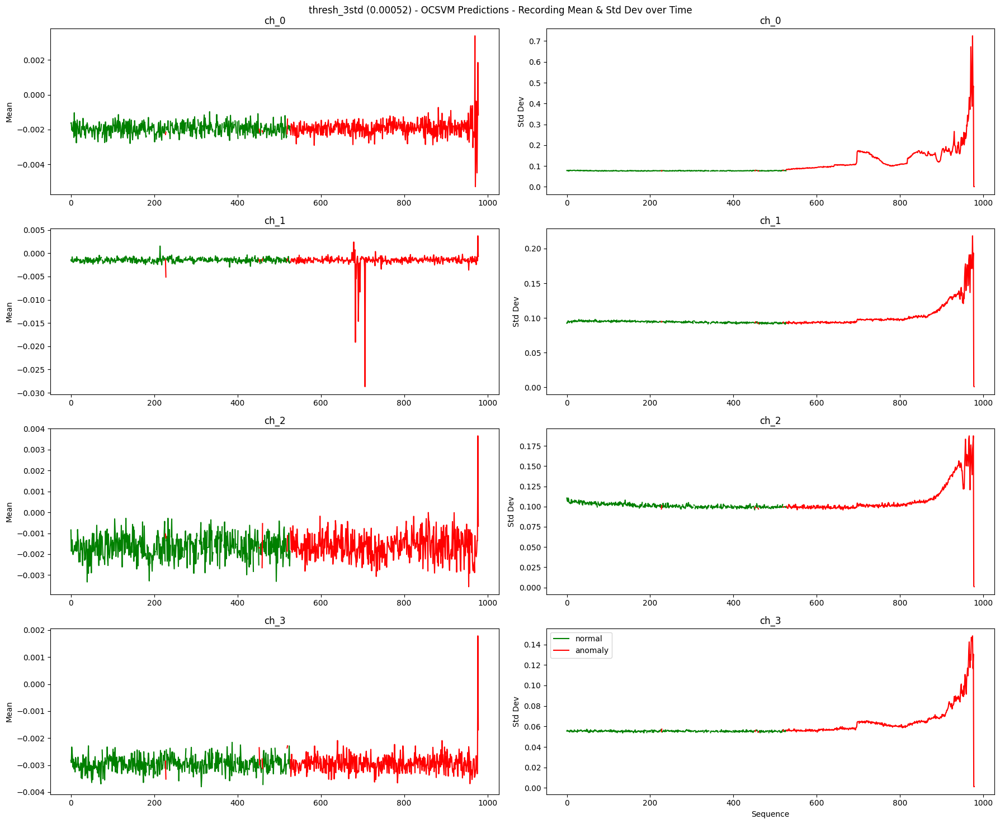

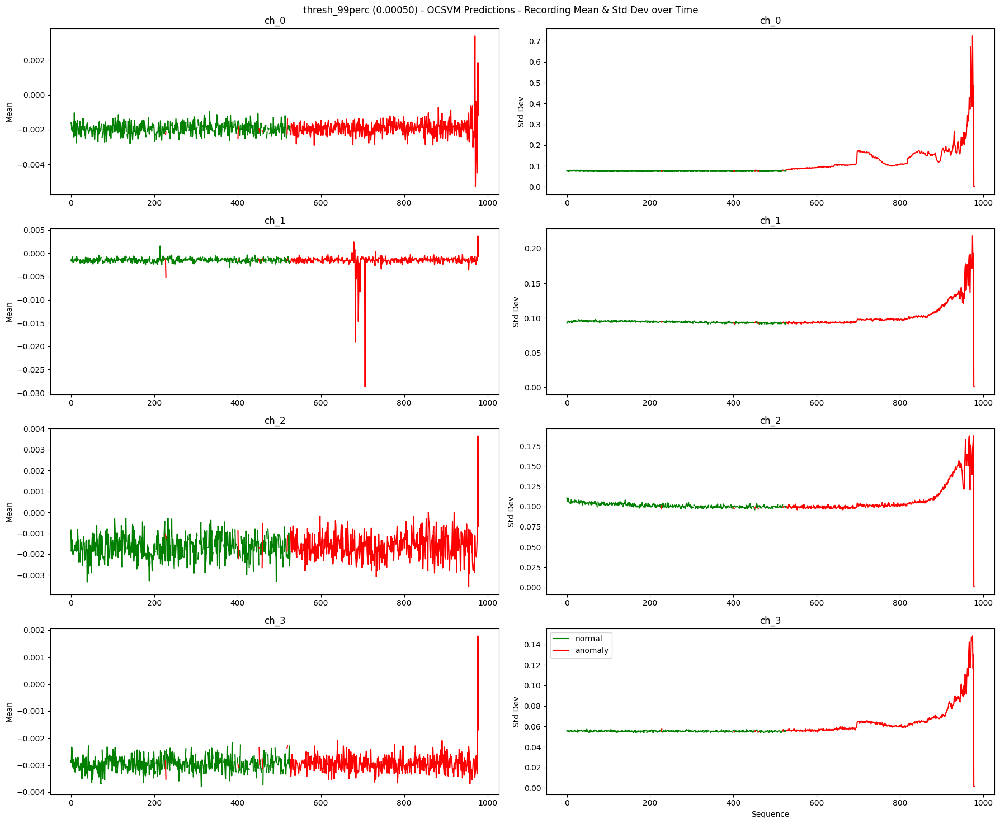

In [ ]:
compute_thresh_and_plot_preds(ocsvm_scores, 'OCSVM', k_baseline)

# Per-axis prediction

## Z-score

In [9]:
import numpy as np
np.stack([[0,1,2],[2,3,4]])

array([[0, 1, 2],
       [2, 3, 4]])

In [209]:
def z_score_anomaly(data, mean, std, stds_thresh=3):
  z_scores = (data - mean) / std
  anoms = np.abs(z_scores) > stds_thresh
  seq_anom_score = anoms.sum() / np.prod(data.shape)
  return anoms, seq_anom_score

In [210]:
first_k = 150
clean_mean = all_seqs[:first_k].mean(axis=(0,2), keepdims=True).squeeze(0)
clean_std = all_seqs[:first_k].std(axis=(0,2), keepdims=True).squeeze(0)

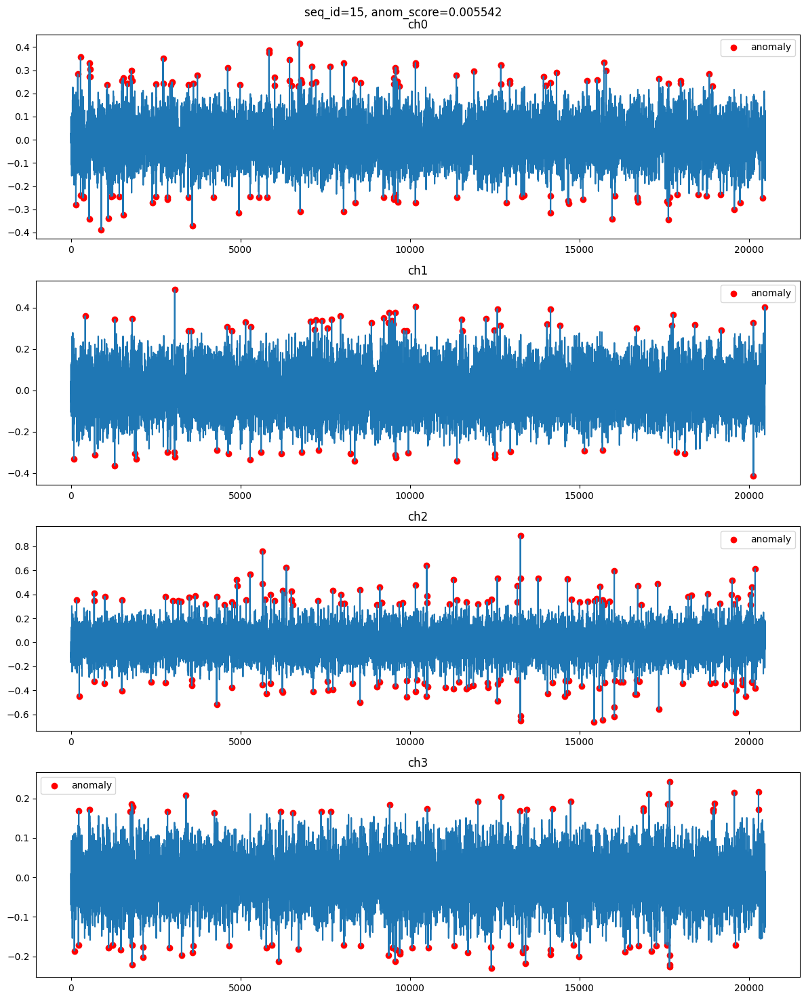

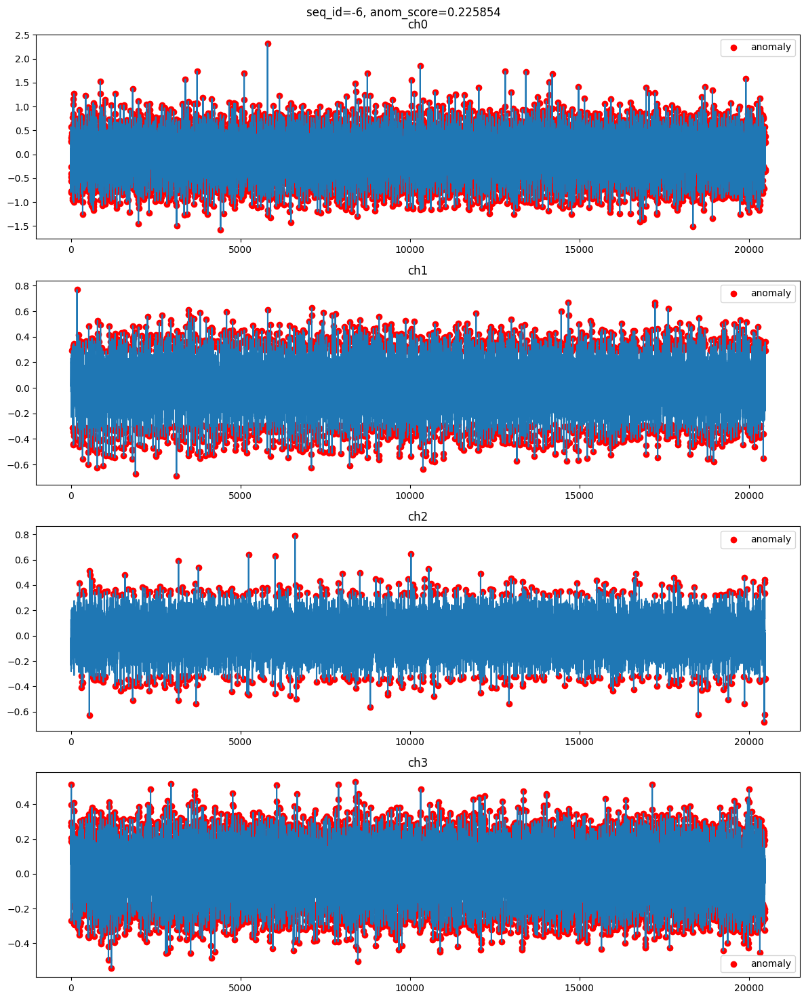

In [211]:
for seq_id in [15,-6]:
  test_data = all_seqs[seq_id]
  anoms, anom_score = z_score_anomaly(test_data, clean_mean, clean_std)
  fig, axs = plt.subplots(4, 1, figsize=(12, 15))
  for i in range(4):
    axs[i].plot(test_data[i])
    time_axis = np.linspace(0, len(test_data[i]) - 1, len(test_data[i]))
    axs[i].scatter(x=time_axis[anoms[i]], y=test_data[i][anoms[i]], c='r', label='anomaly')
    axs[i].title.set_text(f'ch{i}')
    axs[i].legend()

  plt.suptitle(f'seq_id={seq_id}, anom_score={anom_score:.6f}')
  plt.tight_layout()
  plt.legend()
  plt.show()
  print()

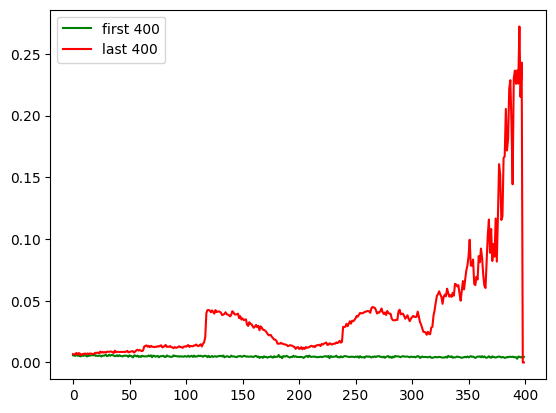

In [221]:
tot_seqs_for_anom_score = 400
first_anom_scores = []
last_anom_scores = []
for i in range(tot_seqs_for_anom_score):
  test_data = all_seqs[i]
  anoms, seq_anom_score = z_score_anomaly(test_data, clean_mean, clean_std)
  first_anom_scores.append(seq_anom_score)

  test_data = all_seqs[-(tot_seqs_for_anom_score-i)]
  anoms, seq_anom_score = z_score_anomaly(test_data, clean_mean, clean_std)
  last_anom_scores.append(seq_anom_score)


plt.plot(first_anom_scores, c='green', label=f'first {tot_seqs_for_anom_score}')
plt.plot(last_anom_scores, c='red', label=f'last {tot_seqs_for_anom_score}')
plt.legend()
plt.show()

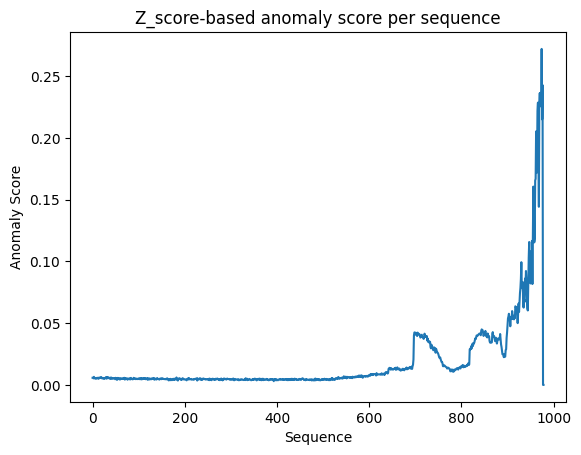

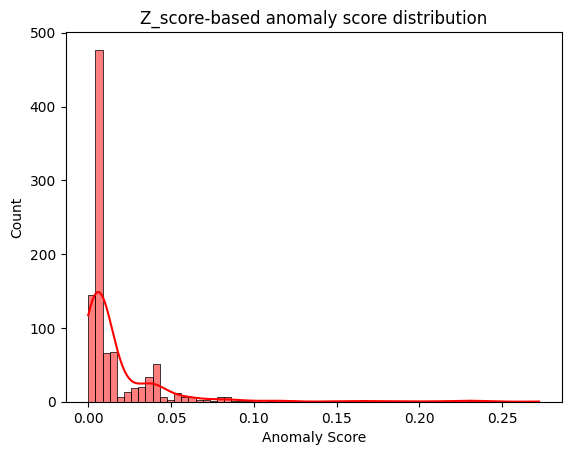

In [223]:
tot_anom_scores = np.array([z_score_anomaly(seq, clean_mean, clean_std)[1] for seq in all_seqs])
plt.plot(tot_anom_scores)
plt.title('Z_score-based anomaly score per sequence')
plt.xlabel('Sequence')
plt.ylabel('Anomaly Score')
plt.show()
print()

plt.title('Z_score-based anomaly score distribution')
sns.histplot(tot_anom_scores, kde=True, color='red', label='late')
plt.xlabel('Anomaly Score')
plt.show()

<Axes: ylabel='Count'>

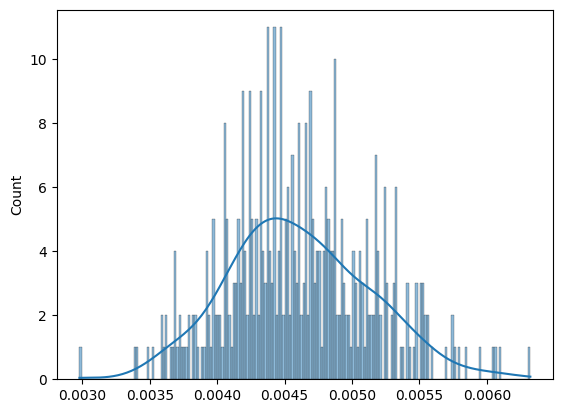

In [ ]:
sns.histplot(first_anom_scores, bins=200, kde=True)

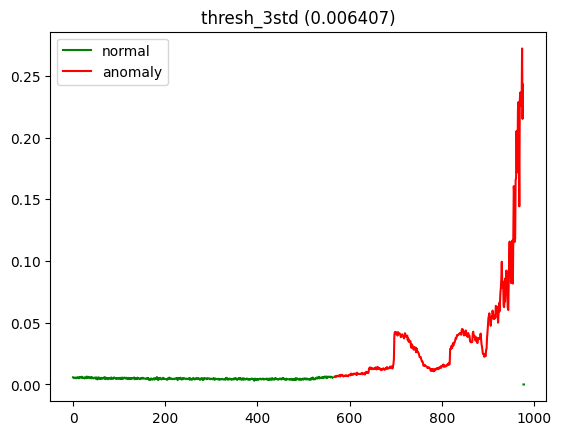

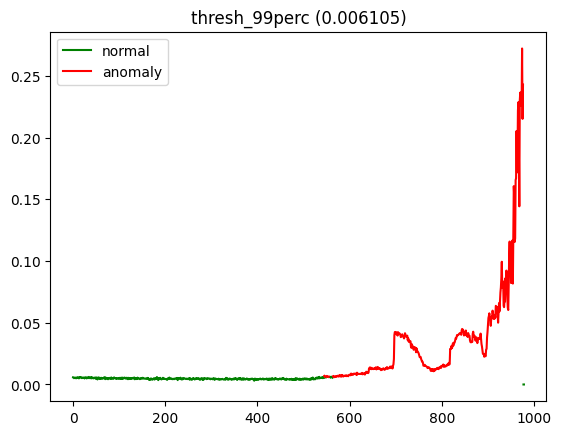

In [224]:
thresholds = compute_thresholds(first_anom_scores)

x_axis = np.arange(len(tot_anom_scores))

for thresh_name, thresh in thresholds.items():
  is_anom = tot_anom_scores > thresh
  normal_y = np.where(~is_anom, tot_anom_scores, np.nan)
  anom_y = np.where(is_anom, tot_anom_scores, np.nan)

  plt.plot(x_axis, normal_y, c='green', label='normal')
  plt.plot(x_axis, anom_y, c='red', label='anomaly')

  plt.title(f'{thresh_name} ({thresh:.6f})')
  plt.legend()
  plt.show()
  print()

In [239]:
all_seqs.mean(axis=(2), keepdims=True)

array([[[-0.0016231 ],
        [-0.00145259],
        [-0.00084155],
        [-0.00282183]],

       [[-0.00160645],
        [-0.00169595],
        [-0.00185635],
        [-0.00290488]],

       [[-0.00202666],
        [-0.00174365],
        [-0.00170332],
        [-0.00233003]],

       ...,

       [[-0.00170308],
        [-0.00163223],
        [-0.00136548],
        [-0.00331089]],

       [[ 0.00185684],
        [ 0.00373149],
        [ 0.00365581],
        [ 0.00178555]],

       [[-0.00116196],
        [-0.00070117],
        [-0.00066362],
        [-0.00169521]]], shape=(979, 4, 1))

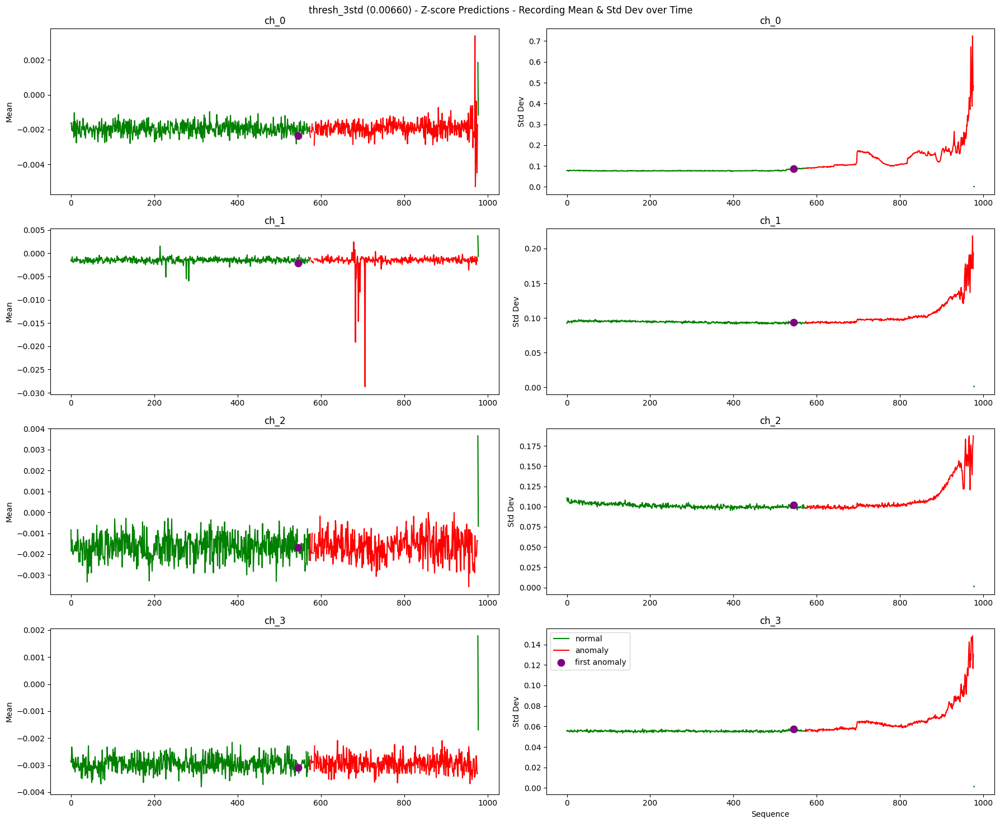

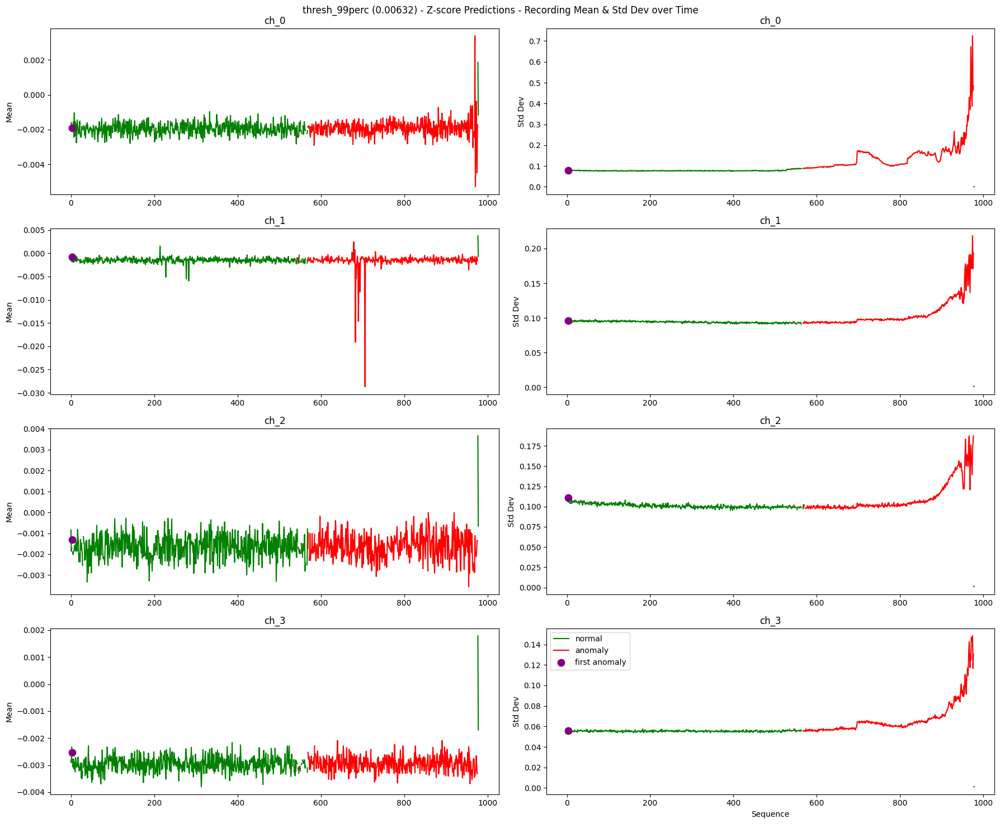

In [226]:
z_score_preds = compute_thresh_and_plot_preds(tot_anom_scores, 'Z-score', k_baseline)

In [19]:
n_files, n_channels, n_measurements = all_seqs.shape

print('Extracting per-channel features...')
channel_feature_dfs = {}
for ch in range(n_channels):
  ch_name = f'ch{ch}'
  ch_cols = [col for col in X_features.columns if col.startswith(ch_name)]
  channel_feature_dfs[ch] = X_features[ch_cols].copy()

Extracting per-channel features...


## IForest

In [250]:
# --- Step 2: Train independent models and score each channel ---
# Define healthy baseline (e.g., skip first 10 startup files, use next 50 files)
k_baseline = 200

anom_scores = np.zeros((n_files, n_channels))
channel_predictions = np.zeros((n_files, n_channels))
channel_models = {}

print('Training per-channel Isolation Forests and scoring...')
for c in range(n_channels):
  df_feats = channel_feature_dfs[c]

  # Scale features for this specific channel
  scaler = StandardScaler()
  scaler.fit(df_feats[:k_baseline])
  scaled_features = scaler.transform(df_feats)

  # Isolate healthy baseline for this channel
  X_baseline = scaled_features[:k_baseline]


  # Train Isolation Forest with novelty=True for this channel
  model = IsolationForest(max_features=0.25, contamination='auto', random_state=42)
  model.fit(X_baseline)
  channel_models[c] = model

  # Compute anomaly score (decision_function returns higher for normal, lower for anomalous)
  # Convert to a positive degradation score where higher = more anomalous
  raw_scores = model.decision_function(scaled_features)
  anom_scores[:, c] = -raw_scores
  channel_predictions[:, c] = model.predict(scaled_features)==-1

# --- Step 3: Result Analysis ---
# channel_scores has shape (984 files, 4 channels)
print('Score matrix shape:', anom_scores.shape)

# You can now easily check which channel spiked first:
# Channel 0 (Bearing 1) should show an aggressive upward trajectory toward file 984.

Training per-channel Isolation Forests and scoring...
Score matrix shape: (979, 4)


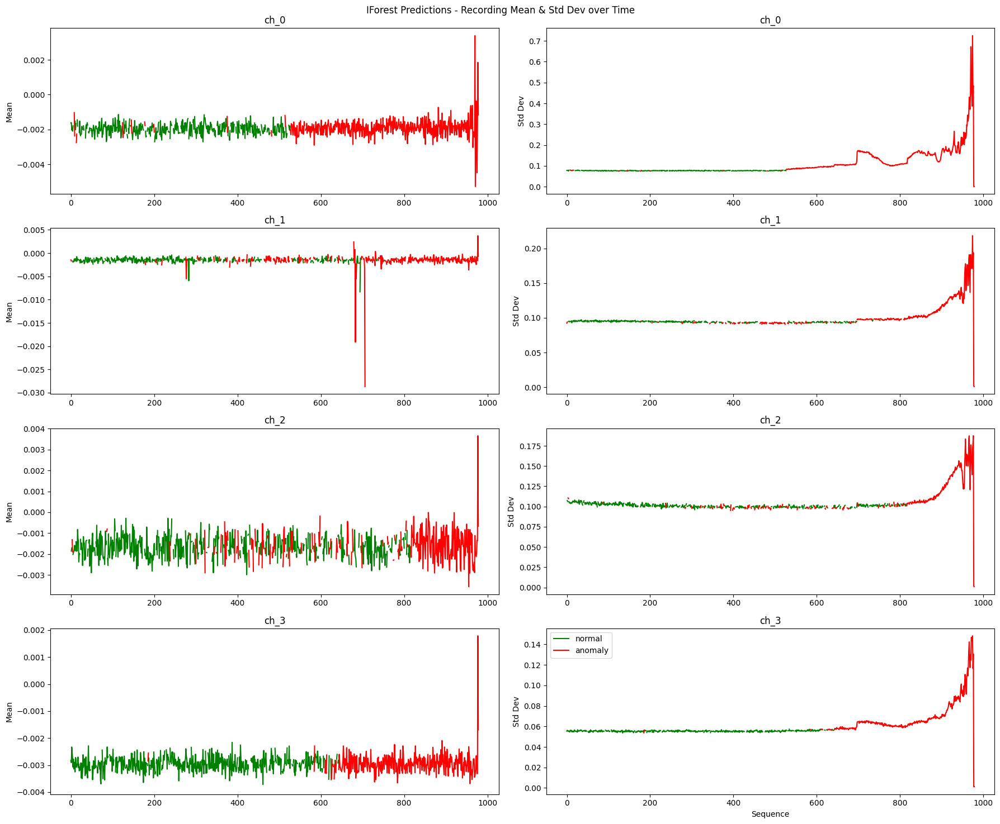

In [ ]:
plot_seq_preds(channel_predictions, f'IForest')

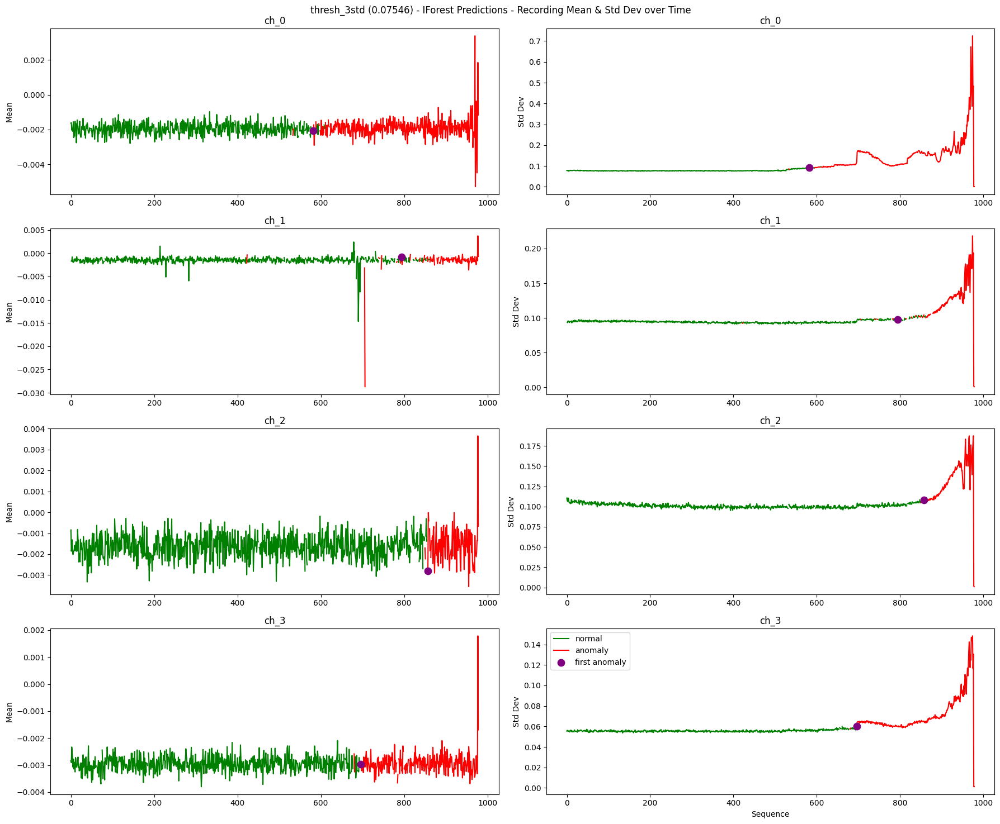

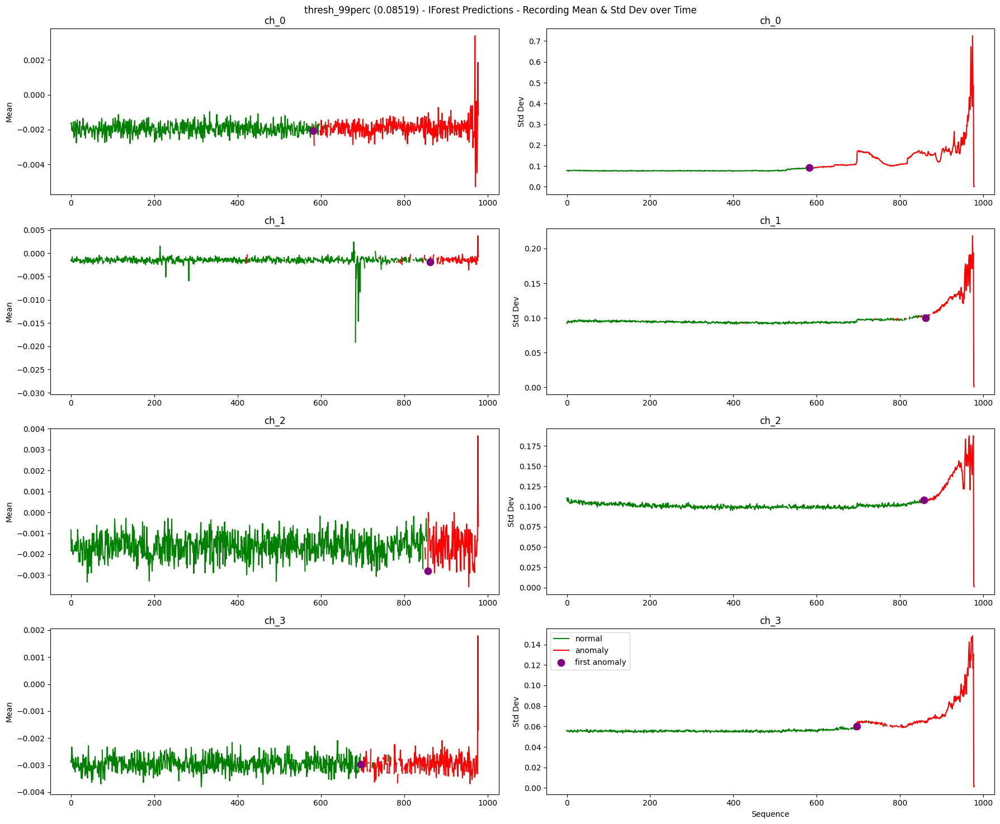

In [251]:
thresh_preds = compute_thresh_and_plot_preds(anom_scores, 'IForest', k_baseline, convolve=True)

## OCSVM

In [ ]:

# --- Step 2: Train independent models and score each channel ---
# Define healthy baseline (e.g., skip first 10 startup files, use next 50 files)
k_baseline = 180

anom_scores = np.zeros((n_files, n_channels))
channel_predictions = np.zeros((n_files, n_channels))
channel_models = {}

print('Training per-channel Isolation Forests and scoring...')
for c in range(n_channels):
  df_feats = channel_feature_dfs[c]

  # Scale features for this specific channel
  scaler = RobustScaler()
  scaler.fit(df_feats[:k_baseline])
  scaled_features = scaler.transform(df_feats)

  # Isolate healthy baseline for this channel
  X_baseline = scaled_features[:k_baseline]

  ocsvm = FeatEngOCSVM()
  ocsvm.fit(X_baseline)

  channel_models[c] = ocsvm

  # Compute anomaly score (decision_function returns higher for normal, lower for anomalous)
  # Convert to a positive degradation score where higher = more anomalous
  raw_scores = ocsvm.decision_function(scaled_features)
  anom_scores[:, c] = -raw_scores
  channel_predictions[:, c] = model.predict(scaled_features)==-1

# --- Step 3: Result Analysis ---
# channel_scores has shape (984 files, 4 channels)
print('Score matrix shape:', anom_scores.shape)

# You can now easily check which channel spiked first:
# Channel 0 (Bearing 1) should show an aggressive upward trajectory toward file 984.

Training per-channel Isolation Forests and scoring...
Score matrix shape: (979, 4)


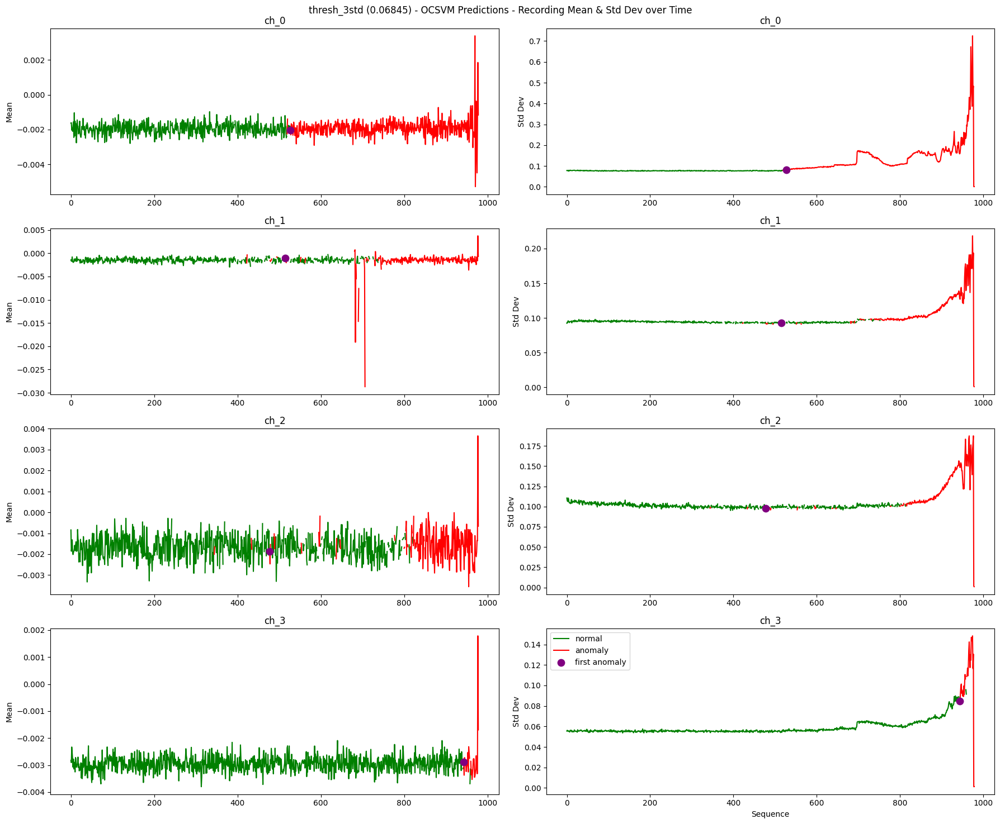

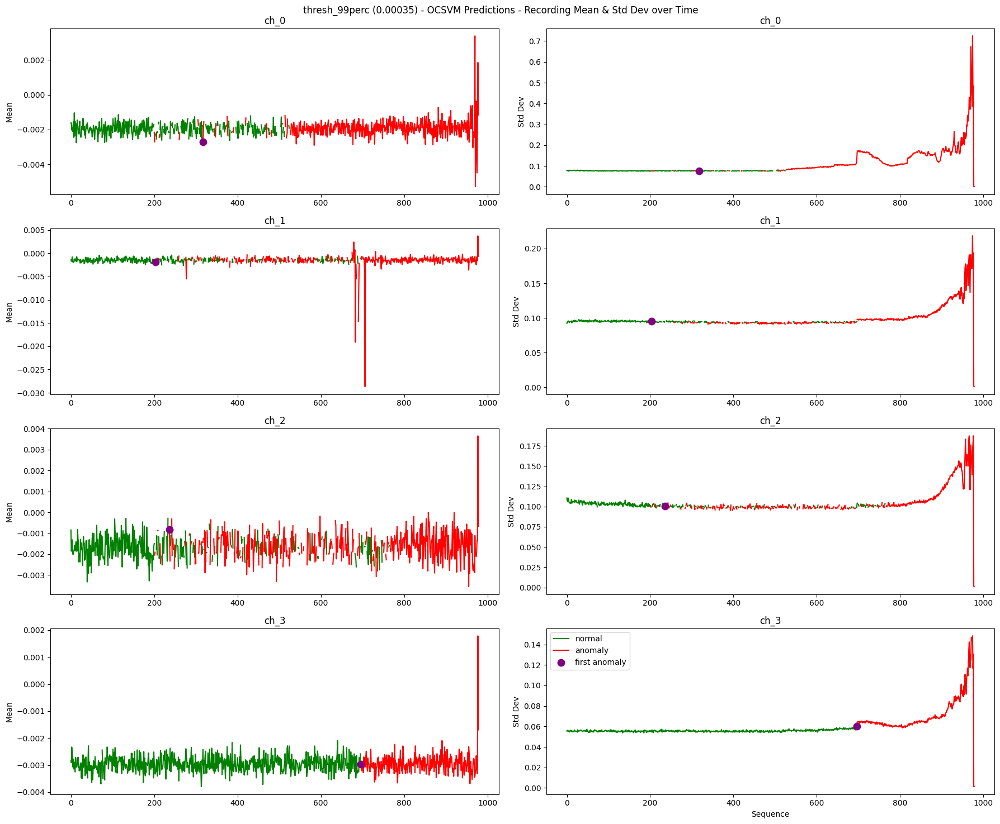

In [261]:
ocsvm_preds = compute_thresh_and_plot_preds(anom_scores, 'OCSVM', k_baseline, convolve=True)

In [262]:
ocsvm_preds['thresh_3std'][:180].sum()/(180*4)

np.float64(0.0)

## Conv AutoEncoder

### Model class

In [68]:


class FullyConvAE(nn.Module):
    def __init__(self,
                 tot_layers:int=5,
                 in_channels:int=4,
                 latent_channels:int=16,
                 ch_mult_factor:int=2,
                 kernel_size:int=7,
                 stride:int=2,
                 padding:int=3,
                 device='cpu'):
        super().__init__()

        self.model_name=self.__class__.__name__
        self.device = device
        self.config = {
            "model_name": self.model_name,
            "tot_layers": tot_layers,
            "in_channels": in_channels,
            "latent_channels": latent_channels,
            "ch_mult_factor": ch_mult_factor,
            "kernel_size": kernel_size,
            "stride": stride,
            "padding": padding
        }

        self.encoder = nn.Sequential()

        layer_sizes = []

        if latent_channels > 0:
            channel_sizes = np.linspace(in_channels if len(layer_sizes) == 0 else layer_sizes[-1][1], latent_channels, tot_layers + 1 - len(layer_sizes), dtype=int)
            layer_sizes.extend([(channel_sizes[i], channel_sizes[i+1]) for i in range(len(channel_sizes)-1)])
        else:
            for i in range(tot_layers - len(layer_sizes)):
                layer_in_dim = layer_sizes[0][1] if i == 0 and len(layer_sizes) > 0 else (layer_out_dim if i > 0 else in_channels)
                layer_out_dim = int(layer_in_dim * ch_mult_factor)
                layer_sizes.append((layer_in_dim, layer_out_dim))

        for i in range(tot_layers):
            layer_in_channels = layer_sizes[i][0]
            layer_out_channels = layer_sizes[i][1]
            self.encoder.append(nn.Conv1d(layer_in_channels, layer_out_channels, kernel_size=kernel_size, stride=stride, padding=padding))
            if i < tot_layers - 1:
                self.encoder.append(nn.LeakyReLU())

        self.latent_dim = layer_sizes[-1][1]

        self.decoder = nn.Sequential()
        for i in range(tot_layers):
            layer_in_channels = layer_sizes[-(i+1)][1]
            layer_out_channels = layer_sizes[-(i+1)][0]
            self.decoder.append(nn.ConvTranspose1d(layer_in_channels, layer_out_channels, kernel_size=kernel_size, stride=stride, padding=padding, output_padding=1 if stride==2 else 0))  # output_padding adjusts size with stride
            if i > 0:
                self.decoder.append(nn.LeakyReLU())

        self.gap = nn.AdaptiveAvgPool1d(1)

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z)

    def loss_fn(self, x, recon_x, reduce=True):
        return F.mse_loss(recon_x, x, reduction='mean' if reduce else 'none')

    def predict_anomaly(self, x, threshold):
        self.eval()
        with torch.no_grad():
            x = x.to(self.device)
            recon_x = self.forward(x)
            mean_dim_reduction = (1,2)
            if len(threshold) == x.shape[1]:
                mean_dim_reduction = 2
            rec_loss = F.l1_loss(recon_x, x, reduction='none').mean(dim=mean_dim_reduction).cpu()
            is_anomaly = rec_loss > threshold
        return is_anomaly, rec_loss

    def extract_latent(self, x):
        return self.gap(self.encoder(x)).squeeze(-1)

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z)

### Data preprocessing & preparation

In [ ]:


class Logger():
  def __init__(self, log_file_path: str, log_file_name: str='training_log.json'):
    self.log_file_path = log_file_path
    self.log_file_name = log_file_name
    self.log_keys = set()
    self.log_values = {}

  def log(self, log_key, log_value, epoch=None):
    if log_key not in self.log_values.keys():
      self.log_values[log_key] = []

    if epoch is not None:
      log_value = (log_value, epoch)

    self.log_values[log_key].append(log_value)

  def save_to_file(self):
    if not os.path.exists(self.log_file_path):
      os.makedirs(self.log_file_path)

    with open(os.path.join(self.log_file_path, self.log_file_name), "w") as f:
      json.dump(self.log_values, f, indent=2)

In [92]:

final_ = torch.from_numpy(all_seqs_old)

In [54]:
normal_seqs = all_seqs[:180]
train_seqs, valid_calib_seqs = train_test_split(normal_seqs, test_size=0.3)
valid_seqs, calib_seqs = train_test_split(valid_calib_seqs, test_size=0.5)
test_seqs = all_seqs.copy()

train_seqs.shape, valid_seqs.shape, calib_seqs.shape, test_seqs.shape

# test_seqs = all_seqs.copy()
# train_seqs.shape, valid_seqs.shape, test_seqs.shape
train_seqs = torch.from_numpy(train_seqs)
valid_seqs = torch.from_numpy(valid_seqs)
calib_seqs = torch.from_numpy(calib_seqs)
test_seqs = torch.from_numpy(test_seqs)

og_file, og_channel, og_seqlen = test_seqs.shape

In [55]:


def chunk_dataset(data, chunk_len=1024, overlap=0.5):
    files, channels, length = data.shape

    # 1. Non-overlapping chunks (safely truncates any remainder)
    if overlap <= 0:
      tot_chunks = length // chunk_len
      trimmed = data[:, :, :tot_chunks * chunk_len]
      return trimmed.reshape(files, channels, tot_chunks, chunk_len), tot_chunks

    # 2. Overlapping chunks using explicit stride = chunk_len * (1 - overlap)
    if overlap < 1:
      stride = max(1, int(chunk_len * (1 - overlap)))
      chunks = sliding_window_view(data, window_shape=chunk_len, axis=2)[:, :, ::stride, :]
      tot_chunks = len(chunks)
      return chunks, tot_chunks

chunk_len = 1024
train_chunks, tot_train_chunks = chunk_dataset(train_seqs,chunk_len=chunk_len)

# no overlap for validation, calibration and test splits
valid_chunks, tot_valid_chunks = chunk_dataset(valid_seqs, chunk_len=chunk_len, overlap=0)
calib_chunks, tot_calib_chunks = chunk_dataset(calib_seqs, chunk_len=chunk_len, overlap=0)
test_chunks, tot_test_chunks = chunk_dataset(test_seqs, chunk_len=chunk_len, overlap=0)
test_chunks.shape

torch.Size([979, 4, 20, 1024])

In [96]:
final_
final_chunks, tot_final_chunks = chunk_dataset(final_, chunk_len=chunk_len, overlap=0)
final_chunks.shape

torch.Size([984, 4, 20, 1024])

In [56]:
def standardize(data:torch.Tensor, mean:torch.Tensor=None, std:torch.Tensor=None):
  if mean is None:
      mean = torch.mean(data, dim=(0,2),keepdim=True)
  if std is None:
      std = torch.std(data, dim=(0,2),keepdim=True)
  return (data - mean) / (std + 1e-9), (mean, std)

def destandardize(data:torch.Tensor, mean:torch.Tensor, std:torch.Tensor):
  mean = mean.view(1, -1, 1)
  std = std.view(1, -1, 1)
  return data * (std + 1e-9) + mean

# def create_sensor_dataset(dfs:List[pd.DataFrame], aggregate_labels:bool=True, seq_length_seconds:float=1., do_sampling_rate_estimation:bool=False, do_standardize:bool=False, standardize_params:tuple=None, do_detrend:bool=False, detrend_method:str='mean', detrend_mean:torch.Tensor=None) -> SensorDataset:
def prepare_dloader(data, standardize_params:tuple=None, do_standardize:bool=False,batch_size:int=32, shuffle:bool=True, is_test=False):
  # 1. transform to torch
  # 2. reshape to (samples, channels, length)
  # 3. standardize
  # 4. create DataSet and DataLoader

  files,channels,chunks,length = data.shape
  data = torch.as_tensor(data).float().permute(0, 2, 1, 3).contiguous()
  data = data.reshape(-1, channels, length)

  if do_standardize:
    # standardize the data
    mean, std = None, None
    if standardize_params is not None and len(standardize_params) == 2:
      mean, std = standardize_params
    data, (mean, std) = standardize(data, mean, std)

  if is_test:
    labels = torch.empty(files*chunks)
  else:
    labels = torch.zeros(files*chunks)
  dataset = TensorDataset(data, labels)


  loader = DataLoader(dataset, shuffle=shuffle, batch_size=32)

  params = {}
  if do_standardize:
      params['standardize'] = {'mean': mean, 'std': std}
  return loader, params

do_standardize=True
train_loader, std_params = prepare_dloader(train_chunks,do_standardize=do_standardize)
valid_loader,_ = prepare_dloader(valid_chunks,do_standardize=do_standardize, standardize_params=std_params)
calib_loader,_ = prepare_dloader(calib_chunks,do_standardize=do_standardize, standardize_params=std_params)
test_loader,_ = prepare_dloader(test_chunks,do_standardize=do_standardize,shuffle=False, standardize_params=std_params, is_test=True)

/tmp/ipykernel_1556/1770509578.py:21: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  data = torch.as_tensor(data).float().permute(0, 2, 1, 3).contiguous()


In [97]:
final_loader,_ = prepare_dloader(final_chunks,do_standardize=do_standardize,shuffle=False, standardize_params=std_params, is_test=True)

In [57]:
def restore_dataset(predictions: torch.Tensor,n_files: int,n_chunks: int,original_length: int = None):
    """
    Restore flattened chunk predictions to original recordings.

    Input:
        (files * chunks_per_file, channels, chunk_len)

    Output:
        (files, channels, original_length)
    """

    total_chunks, channels, chunk_len = predictions.shape

    assert total_chunks == n_files * n_chunks, (
        f"Expected {n_files * n_chunks} chunks, "
        f"received {total_chunks}"
    )

    # Reverse reshape performed in prepare_dloader
    restored = predictions.reshape(n_files, n_chunks, channels, chunk_len)

    # Reverse permutation performed in prepare_dloader
    restored = restored.permute(0, 2, 1, 3).contiguous()

    # Concatenate temporal chunks
    restored = restored.reshape(n_files, channels, n_chunks * chunk_len)

    # Optionally recover original sequence length
    if original_length is not None:
        restored = restored[:, :, :original_length]

    return restored

In [ ]:
print(len(train_loader),len(valid_loader),len(calib_loader),len(test_loader))


for s,l in train_loader:
  print(s.shape, l.shape, l.max())
  print(s[0])
  break

154 17 17 612
torch.Size([32, 4, 1024]) torch.Size([32]) tensor(0.)
tensor([[-0.6080,  0.5945,  0.1161,  ...,  1.5773,  0.1807, -1.3321],
        [ 0.0154,  1.4223, -0.3416,  ..., -0.8036, -0.2891,  0.9918],
        [-1.7802, -1.6547,  0.5561,  ..., -0.3127, -1.5388,  0.2279],
        [-1.2269, -0.0720,  0.0543,  ..., -0.3066, -0.1261,  1.9851]],
       dtype=torch.float64)


In [ ]:
_test_l,_ = prepare_dloader(test_chunks,do_standardize=False,shuffle=False, standardize_params=std_params, is_test=True)
_test_data = []

for x, _ in _test_l:
    _test_data.append(x)

_test_data = torch.cat(_test_data, dim=0)

print(_test_data.shape)




restored = restore_dataset(
    predictions=_test_data,
    n_files=test_seqs.shape[0],
    n_chunks=tot_test_chunks,
    original_length=test_seqs.shape[-1]
)


print("Original:", test_seqs.shape)
print("Restored:", restored.shape)

print(
    "Exact reconstruction:",
    torch.allclose(
        restored,
        torch.as_tensor(test_seqs, dtype=restored.dtype, device=restored.device)
    )
)

torch.Size([19580, 4, 1024])


### Helper funcs

In [44]:
def write_to_json_file(file_path, data):
    #check if the directory exists, if not create it
    dir_name = os.path.dirname(file_path)
    if not os.path.exists(dir_name):
        os.makedirs(dir_name)
    with open(file_path, 'w') as f:
        json.dump(data, f, indent=4)


def save_model(model, optimizer, epoch, eval_metrics, file_name='checkpoint', file_path='./model_checkpoints', run_id:str=None, datetime_in_filename:bool=False, save_metrics_in_separate_file:bool=False):
    if model is None:
        raise ValueError('ERROR: NO MODEL SPECIFIED.')
    if not file_path:
        file_path = './checkpoints'
    if not os.path.exists(file_path):
        os.makedirs(file_path)
    # path = f'{file_path}/{file_name}_{datetime.now().strftime("%Y-%m-%d_%H-%M-%S")}.pth'

    is_metrics = eval_metrics is not None and len(eval_metrics) > 0

    path = f'{file_path}/{file_name}'
    if datetime_in_filename:
        path += f'_{datetime.now().strftime("%Y-%m-%d_%H-%M-%S")}'

    config_path = file_path
    if save_metrics_in_separate_file and is_metrics:
        config_path = path
        eval_path = os.path.join(path, 'metrics.json')
        path = os.path.join(path, 'model')
    path += '.pth'

    config_file_path = os.path.join(config_path, 'model_config.txt')
    write_to_json_file(config_file_path, model.config)

    checkpoint = {
        'model_state_dict': model.state_dict(),
        'epoch': epoch,
    }

    if is_metrics:
        if save_metrics_in_separate_file:
            write_to_json_file(eval_path, eval_metrics)
        else:
            checkpoint['eval_metrics'] = eval_metrics

    if optimizer is not None:
        checkpoint['optimizer_state_dict'] = optimizer.state_dict()

    if run_id:
        checkpoint['run_id'] = run_id

    torch.save(checkpoint, path)

def load_model(model, file_path='./checkpoint.pth', device='cpu'):
    if model is None:
        raise ValueError('ERROR: NO MODEL SPECIFIED.')

    optimizer = None
    epoch = 0
    eval_metrics = {}

    try:
        # load checkpoint file and set model's and optmizier's state dicts
        checkpoint = torch.load(file_path, weights_only=True, map_location=device)
        model.load_state_dict(checkpoint['model_state_dict'])

        epoch = checkpoint['epoch']
        eval_metrics = checkpoint.get('eval_metrics', {})

        optim_state_dict = checkpoint.get('optimizer_state_dict', None)
        if optim_state_dict is not None:
            optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
            optimizer.load_state_dict(optim_state_dict)

            # move optimizer tensors to device
            for param in optimizer.state.values():
                if isinstance(param, torch.Tensor):
                    param.data = param.data.to(device)
                    if isinstance(param, dict):
                        for sub_param in param.values():
                            if isinstance(sub_param, torch.Tensor):
                                sub_param.data = sub_param.data.to(device)
    except FileNotFoundError:
        raise FileNotFoundError('ERROR: NO CHECKPOINT FILE FOUND.')
    except:
        raise RuntimeError('ERROR WHILE LOADING PRE-TRAINED MODEL WEIGHTS.')

    return model, optimizer, epoch, eval_metrics

### Training

In [ ]:
def train_epoch(model, train_loader, optimizer):
    model.train()
    train_loss = 0.0
    for batch_id, batch in enumerate(train_loader):
      seqs, _ = batch
      seqs = seqs.to(device)
      optimizer.zero_grad()

      output = model(seqs)
      args = (output, seqs)
      loss = model.loss_fn(*args)
      loss.backward()
      optimizer.step()

      train_loss += loss.item()

    train_loss /= len(train_loader)
    return train_loss

def validate_epoch(model, val_loader):
  model.eval()
  val_loss = 0.0

  with torch.no_grad():
    for batch in val_loader:
      seqs, _ = batch
      seqs = seqs.to(device)

      output = model(seqs)
      args = (output, seqs)
      loss = model.loss_fn(*args)
      val_loss += loss.item()

  val_loss /= len(val_loader)
  return val_loss

In [ ]:
def train(train_loader, val_loader, model, optimizer=None, num_epochs=50, max_patience=20, verbose=False, device='cpu'):
    run_id = datetime.now().strftime("%Y%m%d-%H%M%S")
    log_file_path = os.path.join('logs', model.model_name, run_id)
    logger = Logger(log_file_path=log_file_path, log_file_name='training_log.json')
    model = model.to(device)
    if optimizer is None:
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=10, factor=0.1)

    tot_epochs = 0
    patience_counter = 0
    best_val_loss = np.inf

    log_every = 1
    save_periodically = False
    save_every = 25

    best_model_state_dict = None

    for epoch in tqdm(range(num_epochs), desc="Training Epochs"):
        # perform training epoch
        train_loss = train_epoch(model, train_loader, optimizer)

        # perform validation epoch
        valid_loss = validate_epoch(model, val_loader)

        # log progress to output (if verbose)
        if verbose and (epoch+1)%log_every == 0:
            print(f"[{epoch+1}] Train Loss: {train_loss:.4f} | Val Loss: {valid_loss:.4f}")

        # # log loss results
        logger.log(log_key='Loss/Train', log_value=train_loss, epoch=tot_epochs)
        logger.log(log_key='Loss/Validation', log_value=valid_loss, epoch=tot_epochs)

        scheduler.step(valid_loss)
        if valid_loss < best_val_loss:
            if verbose:
                print('NEW BEST. Saving model . . .')
            best_val_loss = valid_loss
            patience_counter = 0
            best_model_state_dict = model.state_dict()
            # save newly found best
            save_model(model, optimizer, tot_epochs, {'val_loss':best_val_loss}, file_name=f'best', file_path=f'./checkpoints/{model.model_name}/{run_id}', run_id=run_id)
        else:
            patience_counter += 1

        # periodic save
        if save_periodically and epoch % save_every == 0:
            save_model(model, optimizer, tot_epochs, {'val_loss':valid_loss}, file_name=f'epoch_{tot_epochs}', file_path=f'./checkpoints/{model.model_name}/{run_id}', run_id=run_id)

        if patience_counter > max_patience:
            if verbose:
                print(f"Early stopping triggered at epoch {epoch}")
            break

        tot_epochs += 1

    if best_model_state_dict is not None:
        model.load_state_dict(best_model_state_dict)

    logger.save_to_file()

    return model, best_val_loss, run_id

In [60]:
def compute_reconstruction_errors(model, loader, device='cpu'):
  model.eval()
  model = model.to(device)

  errors = []

  with torch.no_grad():
    for data,_ in loader:
      target = data.clone()

      data = data.to(device)
      target = target.to(device)

      prediction = model(data)

      rec_loss = F.l1_loss(prediction, target, reduction='none')
      errors.extend(rec_loss.cpu())

  return torch.stack(errors)


def compute_ae_thresholds(calib_errors, z_scores=[2.5, 3], perc=95):
  thresholds = {}

  # z_score based threshold
  if not z_scores:
    z_scores = [3]
  errors_mean = calib_errors.mean(dim=(0,2))
  errors_std = calib_errors.std(dim=(0,2))
  for z_score in z_scores:
    thresholds[f'mu_+_{z_score}std'] = errors_mean + z_score * errors_std

  # percentile threshold
  if perc is None:
    perc = 95
  thresholds[f'percent_{perc}'] = torch.tensor(np.percentile(calib_errors, perc, axis=(0,2)))

  # 1.1 * max calib_errors
  thresholds[f'1.1 * cal_max'] = 1.1 * torch.amax(calib_errors, dim=(0, 2))

  return thresholds

In [ ]:
model = FullyConvAE()
opt = torch.optim.Adam(model.parameters())
save_model(model,opt,1,eval_metrics={'f1':0.99},run_id='shish')

load_model(FullyConvAE(),file_path='./model_checkpoints/checkpoint.pth')

(FullyConvAE(
   (encoder): Sequential(
     (0): Conv1d(4, 6, kernel_size=(7,), stride=(2,), padding=(3,))
     (1): LeakyReLU(negative_slope=0.01)
     (2): Conv1d(6, 8, kernel_size=(7,), stride=(2,), padding=(3,))
     (3): LeakyReLU(negative_slope=0.01)
     (4): Conv1d(8, 11, kernel_size=(7,), stride=(2,), padding=(3,))
     (5): LeakyReLU(negative_slope=0.01)
     (6): Conv1d(11, 13, kernel_size=(7,), stride=(2,), padding=(3,))
     (7): LeakyReLU(negative_slope=0.01)
     (8): Conv1d(13, 16, kernel_size=(7,), stride=(2,), padding=(3,))
   )
   (decoder): Sequential(
     (0): ConvTranspose1d(16, 13, kernel_size=(7,), stride=(2,), padding=(3,), output_padding=(1,))
     (1): ConvTranspose1d(13, 11, kernel_size=(7,), stride=(2,), padding=(3,), output_padding=(1,))
     (2): LeakyReLU(negative_slope=0.01)
     (3): ConvTranspose1d(11, 8, kernel_size=(7,), stride=(2,), padding=(3,), output_padding=(1,))
     (4): LeakyReLU(negative_slope=0.01)
     (5): ConvTranspose1d(8, 6, kernel_

In [ ]:
# conv AE params for input shape (4, 1024) = 4,096 floats
tot_layers = [4, 5]          # 4 -> latent len 64; 5 -> latent len 32
latent_channels = [8, 16]    # Gives 256 to 1,024 latent floats (4x to 16x compression)
ch_mult_factor = [2]         # Fixed: e.g., 16 -> 32 -> 64 -> 128 (then projected to latent_channels)
kernel_size = [5, 9]         # 5 for sharp local impulses, 9 for wider periodic patterns
stride = [2]                 # Fixed: halves sequence length per encoder layer

conv_params = [tot_layers, latent_channels, ch_mult_factor, kernel_size, stride]

conv_combinations = list(product(*conv_params))
print(f'Total conv combinations: {len(conv_combinations)}')

Total conv combinations: 8


In [ ]:
# test model-data compatibility
ae = FullyConvAE()
for batch, _ in train_loader:
  rec=ae(batch)

  print(batch.shape, '=>', ae.encode(batch).shape)
  assert batch.shape == rec.shape
  break

torch.Size([32, 4, 1024]) => torch.Size([32, 16, 32])


In [81]:
def compute_padding(kernel_size):
    return (kernel_size - 1) // 2

def build_model_from_params(param_config):
  # if len(param_config)!=5:
    # raise
  return FullyConvAE(tot_layers=param_config['tot_layers'], latent_channels=param_config['latent_channels'], ch_mult_factor=param_config['ch_mult_factor'], kernel_size=param_config['kernel_size'], stride=param_config['stride'], padding=compute_padding(param_config['kernel_size']), device=device)

In [ ]:
best_threshold_type = None
best_threshold_results = None
best_f1 = -1
best_param_config = None
best_run_id = None
best_thresholds = None
best_val_loss = torch.inf

print(f'Training model with {len(conv_combinations)} hyperparameter combinations')
for param_idx, param_config in enumerate(conv_combinations):
  print(f'{param_idx+1}/{len(conv_combinations)}')

  model = build_model_from_params(param_config)

  print(f'\t PARAMS: {param_config}')

  model, best_model_val_loss, run_id = train(train_loader, valid_loader, model, num_epochs=100, max_patience=20, device=device)

  if best_model_val_loss < best_val_loss:
    best_val_loss = best_model_val_loss
    best_param_config = param_config
    best_run_id = run_id
    print(f'NEW BEST PARAM CONFIG: {best_param_config}, VAL LOSS: {best_val_loss}. (RUN ID: {best_run_id})')
  # break

# model_results, thresholds = test_model_on_anomaly_detection(model, test_loader=model_selection_valid_loader, valid_loader=valid_loader, normal_test_loader=normal_test_loader, save_results=False, train_run_id=run_id, device=device)
# find best threshold based on valid set
# for thresh_type, results in model_results.items():
#     avg_f1 = results['classification_report']['weighted avg']['f1-score']
#     if avg_f1 > best_f1:
#       best_f1 = avg_f1
#       best_threshold_type = thresh_type
#       best_threshold_results = results
#       best_param_config = param_config
#       best_run_id = run_id
#       best_thresholds = thresholds

# evaluate best model on held out test set
print()
print(f'BEST PARAM CONFIG: {best_param_config}, VAL LOSS: {best_val_loss}. (RUN ID: {best_run_id})')
best_model, _, _, _ = load_model(build_model_from_params(best_param_config), os.path.join('checkpoints', 'FullyConvAE', best_run_id, 'best.pth'))
# TODO : compute thresholds
calib_errors = compute_reconstruction_errors(best_model,calib_loader)
# candidates = {
#     "mean + 2.5*std": calib_scores.mean(axis=0) + 2.5 * calib_scores.std(axis=0),
#     "mean + 3.5*std": calib_scores.mean(axis=0) + 3.5 * calib_scores.std(axis=0),
#     "99th_pct":       np.percentile(calib_scores, 99, axis=0),
#     "1.1 * cal_max":  1.1 * calib_scores.max(axis=0),
# }
thresholds = compute_ae_thresholds(calib_errors)
all_errors = compute_reconstruction_errors(best_model,test_loader)

Training model with 8 hyperparameter combinations
1/8
	 PARAMS: (4, 8, 2, 5, 2)


Training Epochs: 100%|██████████| 100/100 [01:00<00:00,  1.65it/s]


NEW BEST PARAM CONFIG: (4, 8, 2, 5, 2), VAL LOSS: 0.67734834727119. (RUN ID: 20261115-140947)
2/8
	 PARAMS: (4, 8, 2, 9, 2)


Training Epochs: 100%|██████████| 100/100 [01:00<00:00,  1.65it/s]


NEW BEST PARAM CONFIG: (4, 8, 2, 9, 2), VAL LOSS: 0.613555932746214. (RUN ID: 20261115-141048)
3/8
	 PARAMS: (4, 16, 2, 5, 2)


Training Epochs: 100%|██████████| 100/100 [01:00<00:00,  1.64it/s]


... (8 outputs left out)

8/8
	 PARAMS: (5, 16, 2, 9, 2)


Training Epochs: 100%|██████████| 100/100 [01:09<00:00,  1.45it/s]


BEST PARAM CONFIG: (4, 16, 2, 5, 2), VAL LOSS: 0.4830770457492155. (RUN ID: 20261115-141148)


RuntimeError: ERROR WHILE LOADING PRE-TRAINED MODEL WEIGHTS.

In [ ]:
FullyConvAE(tot_layers=data['tot_layers'], latent_channels=param_config['latent_channels'], ch_mult_factor=param_config['ch_mult_factor'], kernel_size=param_config['kernel_size'], stride=param_config['stride'], padding=compute_padding(param_config['kernel_size']), device=device)

In [69]:
best_model, _, _, _ = load_model(build_model_from_params(data), os.path.join('best.pth'))
best_model

FullyConvAE(
  (encoder): Sequential(
    (0): Conv1d(4, 7, kernel_size=(5,), stride=(2,), padding=(2,))
    (1): LeakyReLU(negative_slope=0.01)
    (2): Conv1d(7, 10, kernel_size=(5,), stride=(2,), padding=(2,))
    (3): LeakyReLU(negative_slope=0.01)
    (4): Conv1d(10, 13, kernel_size=(5,), stride=(2,), padding=(2,))
    (5): LeakyReLU(negative_slope=0.01)
    (6): Conv1d(13, 16, kernel_size=(5,), stride=(2,), padding=(2,))
  )
  (decoder): Sequential(
    (0): ConvTranspose1d(16, 13, kernel_size=(5,), stride=(2,), padding=(2,), output_padding=(1,))
    (1): ConvTranspose1d(13, 10, kernel_size=(5,), stride=(2,), padding=(2,), output_padding=(1,))
    (2): LeakyReLU(negative_slope=0.01)
    (3): ConvTranspose1d(10, 7, kernel_size=(5,), stride=(2,), padding=(2,), output_padding=(1,))
    (4): LeakyReLU(negative_slope=0.01)
    (5): ConvTranspose1d(7, 4, kernel_size=(5,), stride=(2,), padding=(2,), output_padding=(1,))
    (6): LeakyReLU(negative_slope=0.01)
  )
  (gap): AdaptiveAvgPoo

In [ ]:

print(f'BEST PARAM CONFIG: {best_param_config}, VAL LOSS: {best_val_loss}. (RUN ID: {best_run_id})')
best_model, _, _, _ = load_model(build_model_from_params(best_param_config), os.path.join('checkpoints', 'FullyConvAE', best_run_id, 'best.pth'))


calib_errors = compute_reconstruction_errors(best_model,calib_loader)
thresholds = compute_ae_thresholds(calib_errors)
all_errors = compute_reconstruction_errors(best_model,test_loader)

BEST PARAM CONFIG: (4, 16, 2, 5, 2), VAL LOSS: 0.4830770457492155. (RUN ID: 20261115-141148)


In [ ]:
data

In [82]:
param_config = {
    "model_name": "FullyConvAE",
    "tot_layers": 4,
    "in_channels": 4,
    "latent_channels": 16,
    "ch_mult_factor": 2,
    "kernel_size": 5,
    "stride": 2,
    "padding": 2
}
best_model, _, _, _ = load_model(build_model_from_params(param_config), os.path.join('best.pth'))
best_model

FullyConvAE(
  (encoder): Sequential(
    (0): Conv1d(4, 7, kernel_size=(5,), stride=(2,), padding=(2,))
    (1): LeakyReLU(negative_slope=0.01)
    (2): Conv1d(7, 10, kernel_size=(5,), stride=(2,), padding=(2,))
    (3): LeakyReLU(negative_slope=0.01)
    (4): Conv1d(10, 13, kernel_size=(5,), stride=(2,), padding=(2,))
    (5): LeakyReLU(negative_slope=0.01)
    (6): Conv1d(13, 16, kernel_size=(5,), stride=(2,), padding=(2,))
  )
  (decoder): Sequential(
    (0): ConvTranspose1d(16, 13, kernel_size=(5,), stride=(2,), padding=(2,), output_padding=(1,))
    (1): ConvTranspose1d(13, 10, kernel_size=(5,), stride=(2,), padding=(2,), output_padding=(1,))
    (2): LeakyReLU(negative_slope=0.01)
    (3): ConvTranspose1d(10, 7, kernel_size=(5,), stride=(2,), padding=(2,), output_padding=(1,))
    (4): LeakyReLU(negative_slope=0.01)
    (5): ConvTranspose1d(7, 4, kernel_size=(5,), stride=(2,), padding=(2,), output_padding=(1,))
    (6): LeakyReLU(negative_slope=0.01)
  )
  (gap): AdaptiveAvgPoo

In [64]:
thresholds

{'mu_+_2.5std': tensor([1.5098, 1.7413, 1.9174, 1.3379]),
 'mu_+_3std': tensor([1.7150, 1.9730, 2.1796, 1.5156]),
 'percent_95': tensor([1.2798, 1.4735, 1.5905, 1.1353]),
 '1.1 * cal_max': tensor([ 4.9141,  6.8760, 10.7101,  4.2437])}

In [83]:
calib_errors = compute_reconstruction_errors(best_model,calib_loader)
thresholds = compute_ae_thresholds(calib_errors)
all_errors = compute_reconstruction_errors(best_model,test_loader)



In [98]:
final_errors = compute_reconstruction_errors(best_model,final_loader)

In [ ]:
preds.sum(axis=2)/og_seqlen>0.01

array([[False, False, False, False],
       [False, False, False, False],
       [False, False, False, False],
       ...,
       [ True, False, False, False],
       [False, False, False, False],
       [False, False, False, False]], shape=(979, 4))

In [79]:
def plot_anomaly_score(errors, thresh, title=''):
  rel_errors = errors / thresh

  anomaly_score = rel_errors.amax(dim=2)
  x = np.arange(anomaly_score.shape[0])

  fig, axs = plt.subplots(4, 1, figsize=(12, 12), sharex=True)

  for i in range(4):
      y = anomaly_score[:, i]

      axs[i].plot(x, y, linewidth=1, label='normal')

      # mask values <= 1 so red only draws where y > 1
      y_anom = np.ma.masked_where(y < 1.0, y)
      axs[i].plot(x, y_anom, color='red', linewidth=1.5, label='anomaly (> 1.0)')

      # reference threshold line
      axs[i].axhline(1.0, color='red', linestyle='--', alpha=0.5, linewidth=1)
      axs[i].set_ylabel(f'Ch{i}')

  axs[0].legend(loc='upper right')
  plt.suptitle(f'Error / Threshold - {title}')
  plt.tight_layout()
  plt.show()


In [85]:
(restored_errors / thresh_resh).max(axis=2)[0]

tensor([[0.4666, 0.6430, 0.6702, 0.6257],
        [0.4812, 0.5998, 0.8034, 0.6853],
        [0.5780, 0.4871, 0.6657, 0.6184],
        ...,
        [5.2059, 1.5226, 0.6982, 1.5391],
        [0.0305, 0.0218, 0.0085, 0.0444],
        [0.0334, 0.0326, 0.0060, 0.0498]])

In [104]:
restored_errors.shape
final_.shape

torch.Size([984, 4, 20480])

In [105]:
file_preds_per_channel

array([[False,  True,  True,  True],
       [False,  True,  True,  True],
       [False,  True,  True,  True],
       ...,
       [ True,  True,  True,  True],
       [False, False, False, False],
       [False, False, False, False]], shape=(984, 4))

In [109]:
final_.std(axis=2).shape

torch.Size([984, 4])

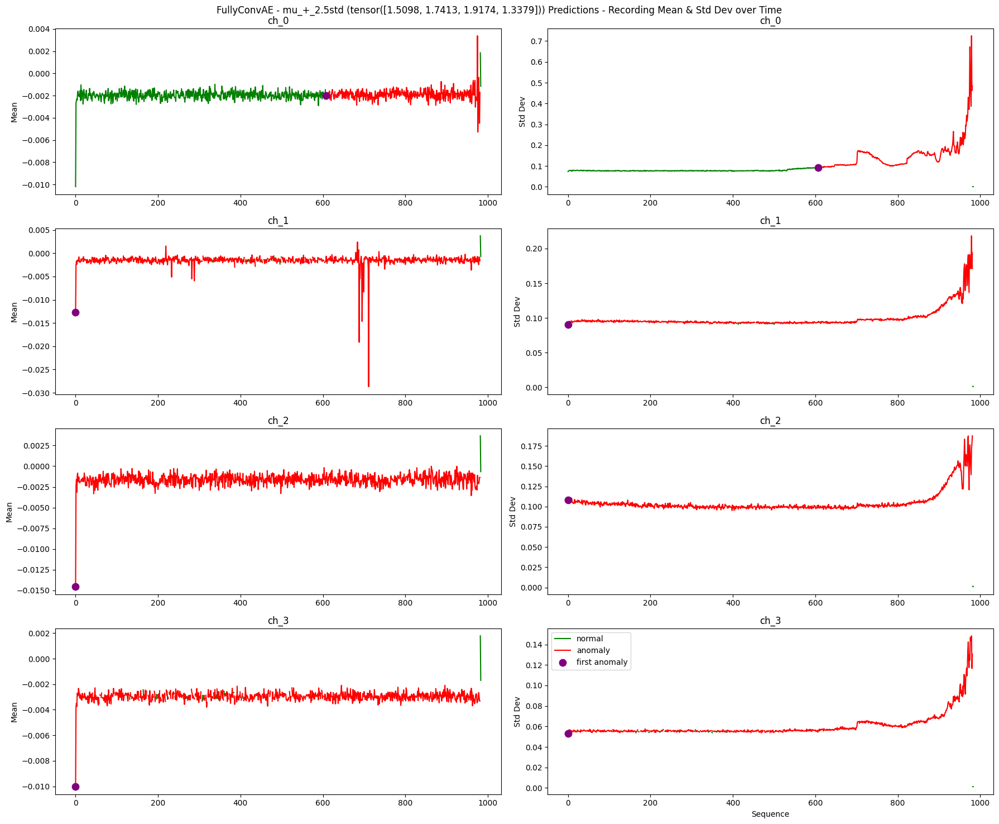

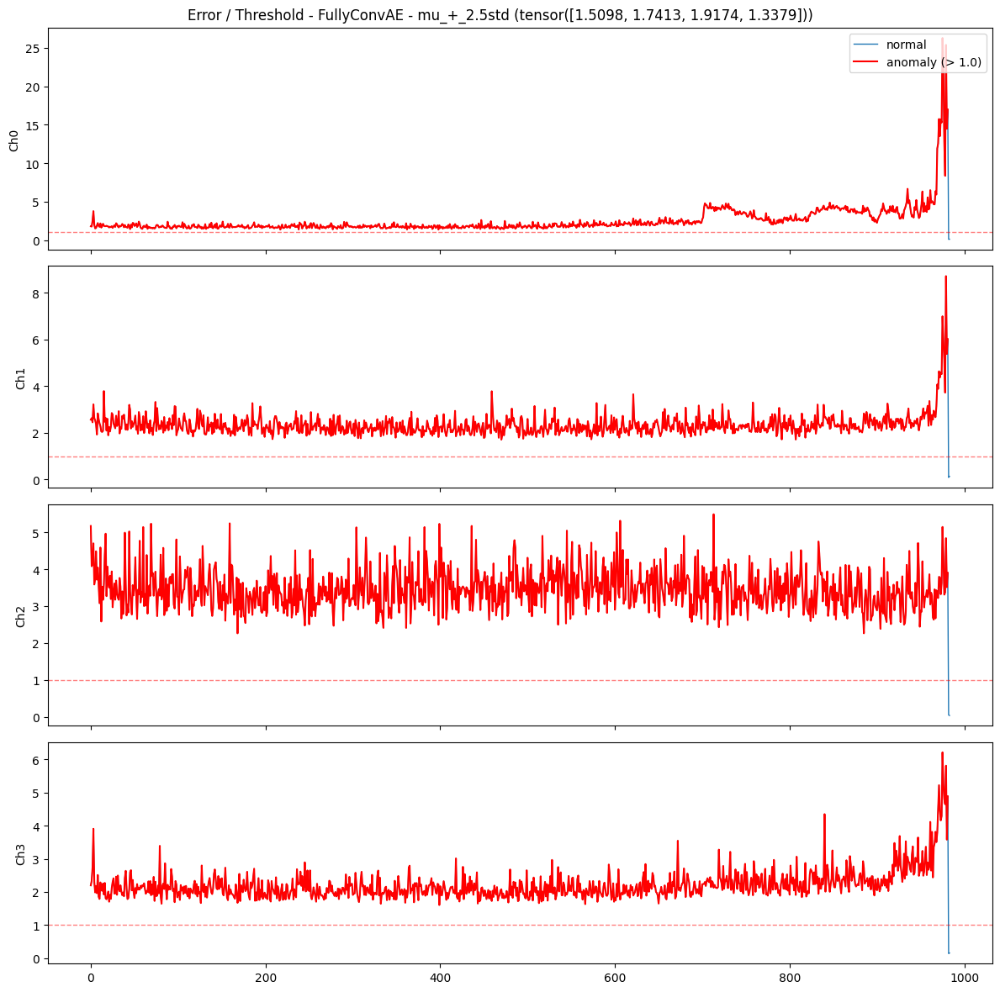

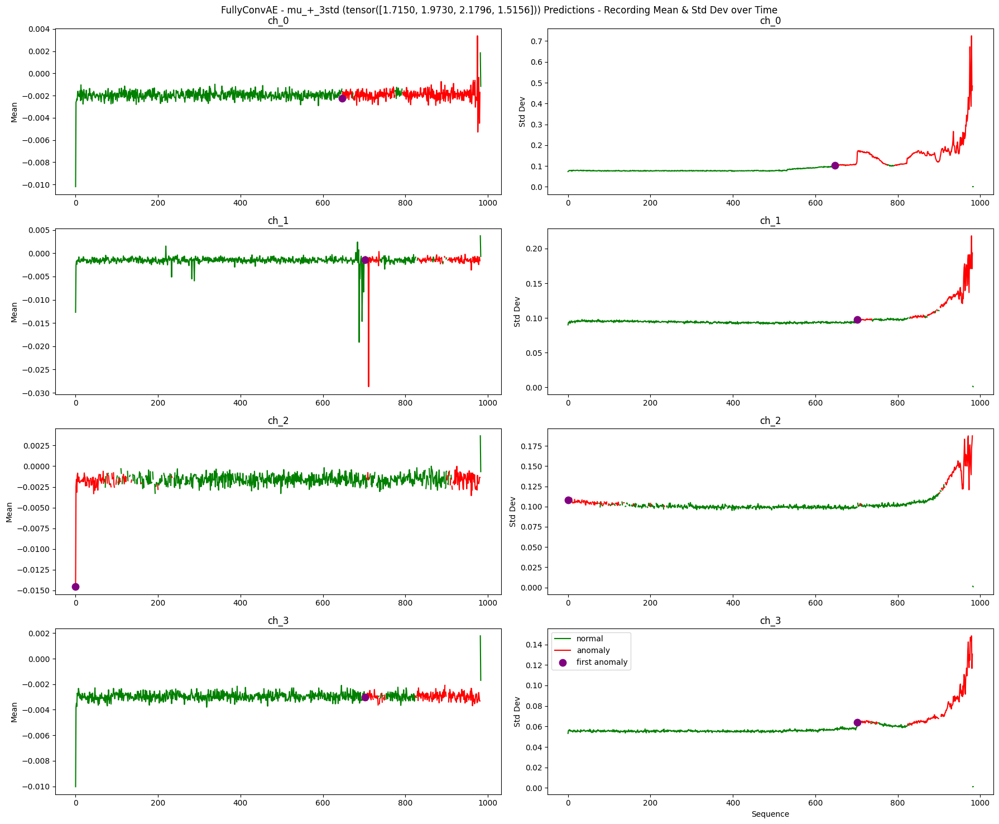

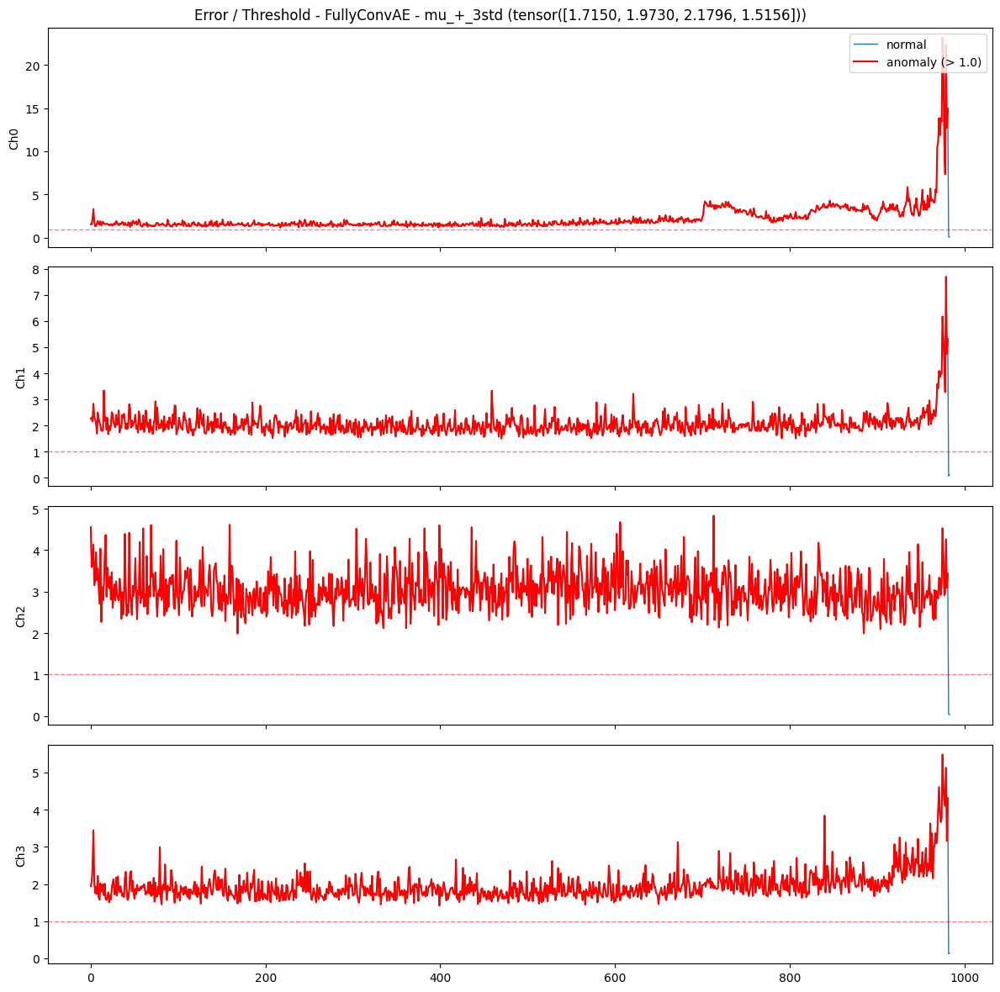

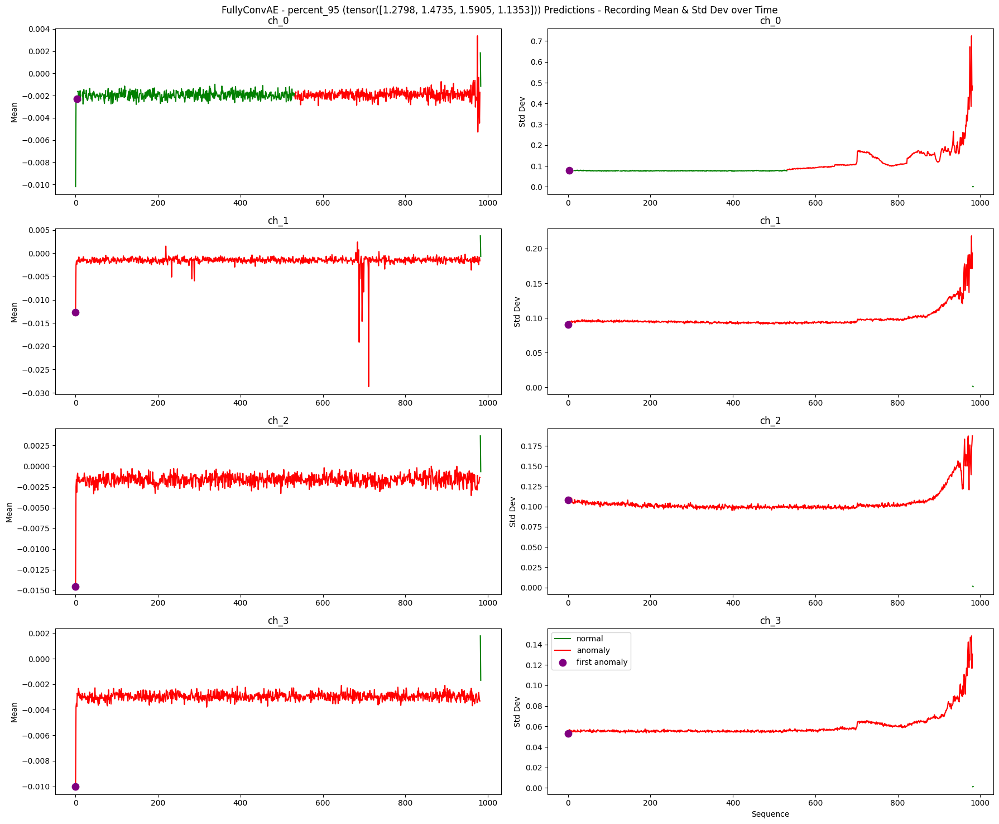

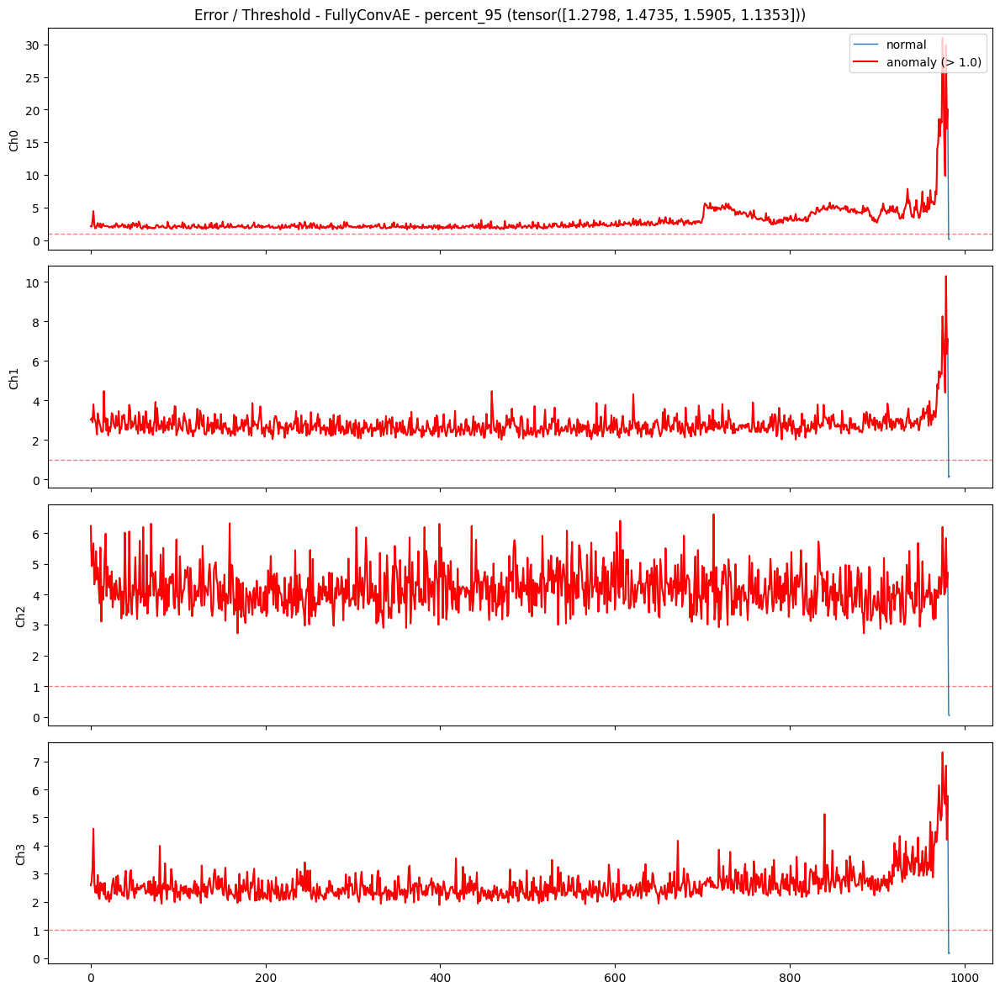

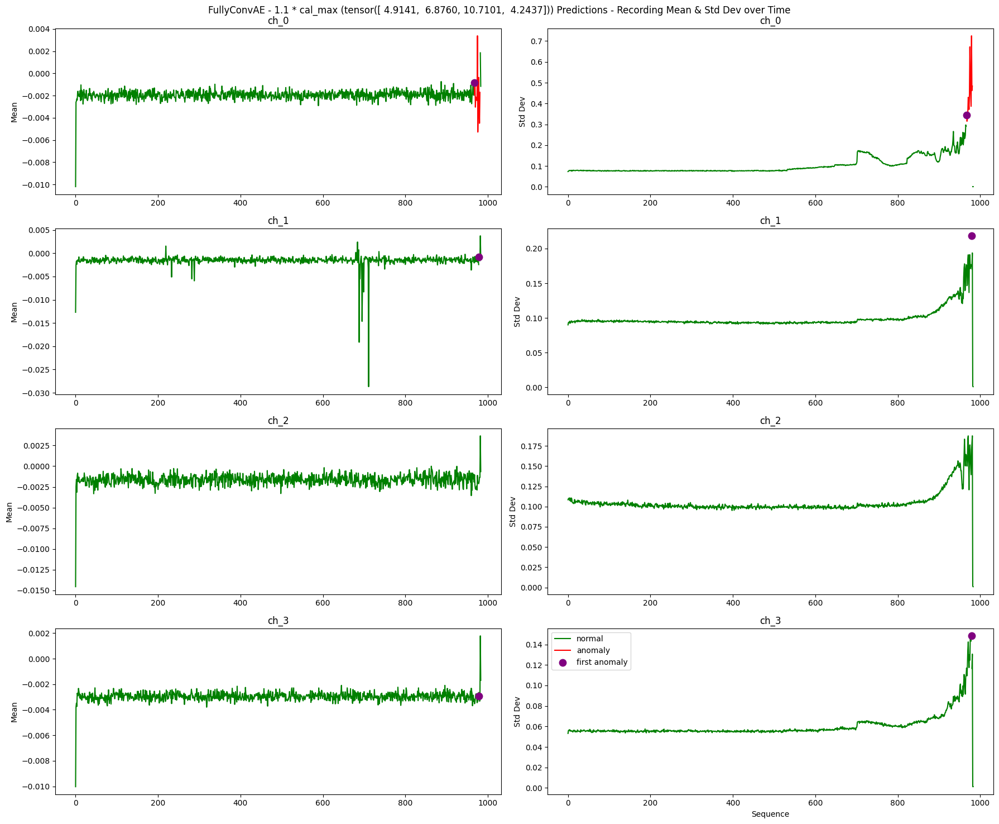

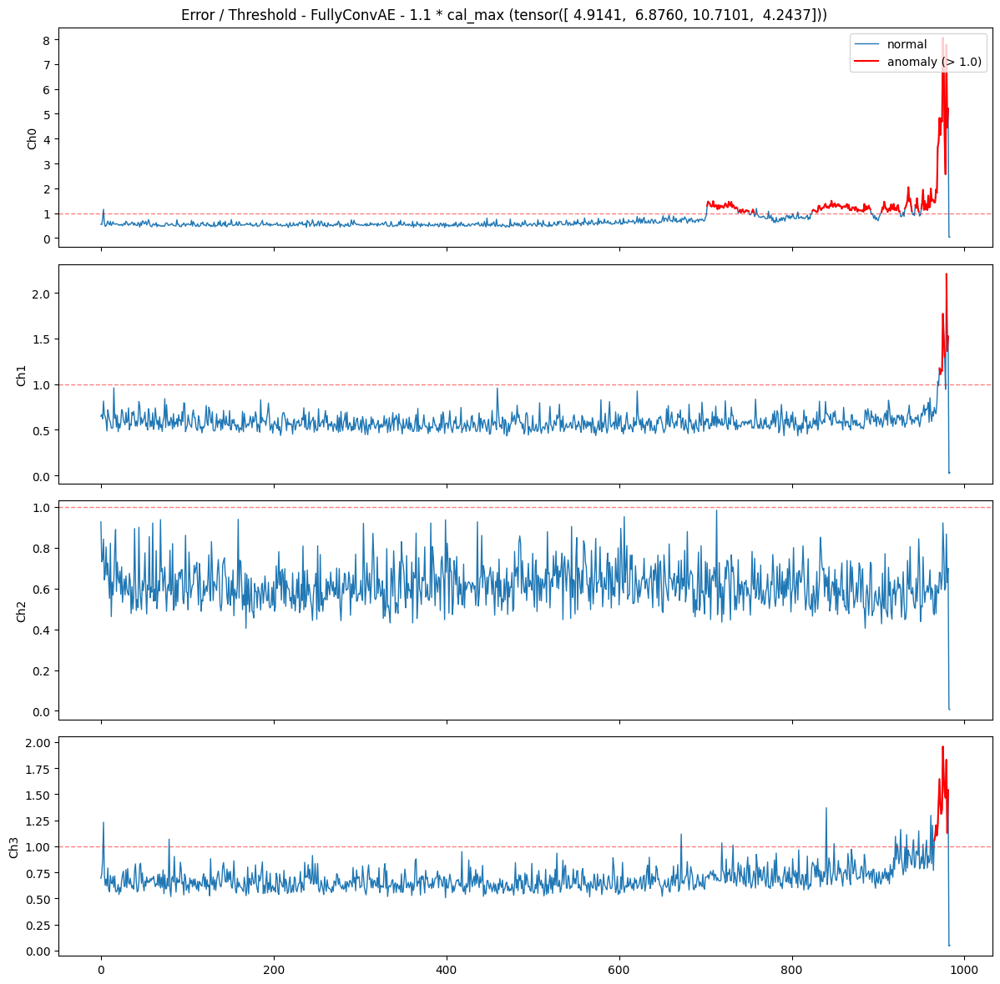

In [147]:
final_seqs_means = final_.mean(axis=2)
final_seqs_stds = final_.std(axis=2)

def _plot_seq_preds(preds, method_name, convolve=False):
  x_axis = np.arange(preds.shape[0])
  fig, axs = plt.subplots(4,2,figsize=(18,15))
  if preds.shape != final_seqs_stds.shape:
    preds = np.broadcast_to(preds[:, None], final_seqs_stds.shape)
  for ch in range(4):

    anom_indices = np.where(preds[:, ch])[0]

    seq_mean = final_seqs_means[:,ch]
    normal_mean = np.where(~preds[:,ch].astype(bool), seq_mean, np.nan)
    anom_mean = np.where(preds[:,ch].astype(bool), seq_mean, np.nan)

    seq_std = final_seqs_stds[:,ch]
    normal_std = np.where(~preds[:,ch].astype(bool), seq_std, np.nan)
    anom_std = np.where(preds[:,ch].astype(bool), seq_std, np.nan)

    axs[ch][0].plot(x_axis, normal_mean, c='green', label='normal')
    axs[ch][0].plot(x_axis, anom_mean, c='red', label='anomaly')
    axs[ch][0].title.set_text(f'ch_{ch}')
    axs[ch][0].set_ylabel('Mean')

    axs[ch][1].plot(x_axis, normal_std, c='green', label='normal')
    axs[ch][1].plot(x_axis, anom_std, c='red', label='anomaly')
    axs[ch][1].title.set_text(f'ch_{ch}')
    axs[ch][1].set_ylabel('Std Dev')

    if len(anom_indices) > 0:
      if convolve:
        sustained = np.convolve(preds[:, ch].astype(int), np.ones(3, dtype=int), mode='valid') == 3
        anom_indices = np.where(sustained)[0]
      first_anom_id = anom_indices[0]
      axs[ch][0].scatter(x_axis[first_anom_id], seq_mean[first_anom_id], c='purple', s=80, zorder=5, label='first anomaly')
      axs[ch][1].scatter(x_axis[first_anom_id], seq_std[first_anom_id], c='purple', s=80, zorder=5, label='first anomaly')


  plt.suptitle(f'{method_name} Predictions - Recording Mean & Std Dev over Time')
  plt.xlabel('Sequence')
  plt.legend()
  plt.tight_layout()
  plt.show()



anom_percs = {}
anom_preds = {}
restored_errors = restore_dataset(final_errors, n_files=984, n_chunks=tot_final_chunks, original_length=og_seqlen)
for name, thresh in thresholds.items():
  thresh_resh = thresh[torch.newaxis, :, torch.newaxis]

  preds = (restored_errors > thresh_resh).float().cpu().numpy()
  anom_perc = preds.sum(axis=2)/og_seqlen
  file_preds_per_channel = anom_perc>0.0125
  anom_preds[name] = file_preds_per_channel
  anom_percs[name] = anom_perc

  rel_errors = restored_errors / thresh_resh
  anomaly_score = (rel_errors.sum(axis=2)/og_seqlen)>0.01

  _plot_seq_preds(file_preds_per_channel, f'FullyConvAE - {name} ({thresh})')
  plot_anomaly_score(restored_errors,thresh_resh, f'FullyConvAE - {name} ({thresh})')
  print()

In [115]:
anom_preds['mu_+_3std']


# Save to file
# torch.save(anom_preds['mu_+_3std'], "results.txt")
with open("results.json", "w", encoding="utf-8") as f:
  json.dump(anom_preds['mu_+_3std'].tolist(), f, indent=4)

# 2. Read back and convert to a tensor
with open("results.json", "r", encoding="utf-8") as f:
  loaded_tensor = torch.tensor(json.load(f))


In [203]:
anom_preds['mu_+_3std']

array([[False, False,  True, False],
       [False, False,  True, False],
       [False, False,  True, False],
       ...,
       [ True,  True,  True,  True],
       [False, False, False, False],
       [False, False, False, False]], shape=(984, 4))

In [123]:
thresholds['mu_+_3std']
anom_percs['mu_+_3std']

array([[0.00175781, 0.00776367, 0.0184082 , 0.00654297],
       [0.00249023, 0.00927734, 0.01777344, 0.00888672],
       [0.00141602, 0.00859375, 0.01865234, 0.00732422],
       ...,
       [0.43154296, 0.23066406, 0.08916016, 0.18510742],
       [0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        ]],
      shape=(984, 4), dtype=float32)

In [151]:
anom_percs['mu_+_3std'].shape

(984, 4)

In [159]:
anomaly_score.shape, t_min.shape

((984, 4), torch.Size([1, 4]))

In [167]:
anomaly_score.shape

(984, 4)

/tmp/ipykernel_1556/535049905.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[0].legend(loc='upper right')


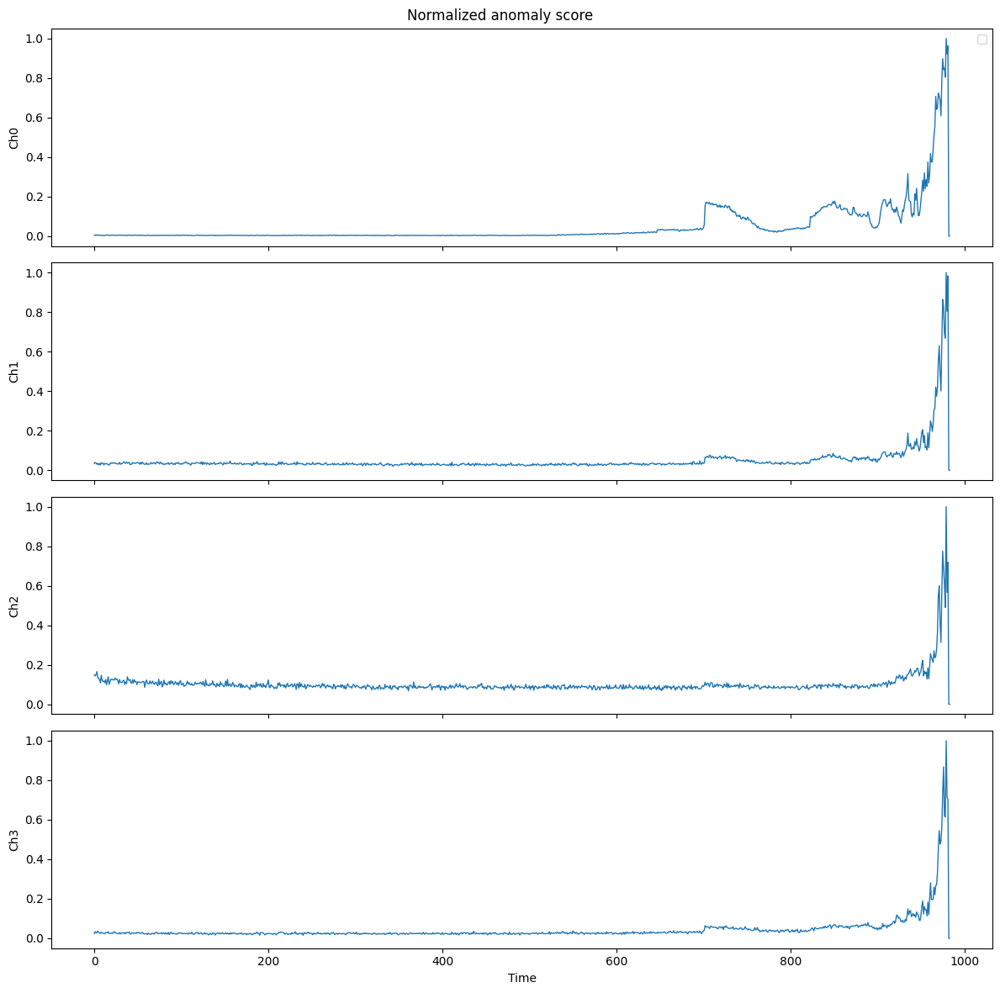

In [171]:
anomaly_score=anom_percs['mu_+_3std']
t_min = anomaly_score.min(axis=0)  # Shape: [1, 3, 1, 1]
t_max = anomaly_score.max(axis=0)  # Shape: [1, 3, 1, 1]


# Adding a tiny epsilon (1e-8) prevents division by zero if all values are identical
anomaly_score = (anomaly_score - t_min) / (t_max - t_min + 1e-8)
x = np.arange(anomaly_score.shape[0])
fig, axs = plt.subplots(4, 1, figsize=(12, 12), sharex=True)
for i in range(4):
    y = anomaly_score[:, i]

    axs[i].plot(x, y, linewidth=1)

    # mask values <= 1 so red only draws where y > 1
    # y_anom = np.ma.masked_where(y < 1.0, y)
    # axs[i].plot(x, y_anom, color='red', linewidth=1.5, label='anomaly (> 1.0)')

    # reference threshold line
    # axs[i].axhline(thresholds['mu_+_3std'][i], color='red', linestyle='--', alpha=0.5, linewidth=1)
    axs[i].set_ylabel(f'Ch{i}')
axs[-1].set_xlabel(f'Time')

axs[0].legend(loc='upper right')
plt.suptitle(f'Normalized anomaly score')
plt.tight_layout()
plt.show()

In [126]:
anomaly_score.shape

(984, 4)

In [131]:
restored_errors.mean(axis=(2)).shape

torch.Size([984, 4])

In [200]:
fpr = anom_percs['mu_+_3std']>0.015
fpr

array([[False, False,  True, False],
       [False, False,  True, False],
       [False, False,  True, False],
       ...,
       [ True,  True,  True,  True],
       [False, False, False, False],
       [False, False, False, False]], shape=(984, 4))

In [204]:
fpr = fpr[5:195]
fpr = anom_preds['mu_+_3std'][5:185]
fpr.sum()/(190*4)

np.float64(0.14473684210526316)

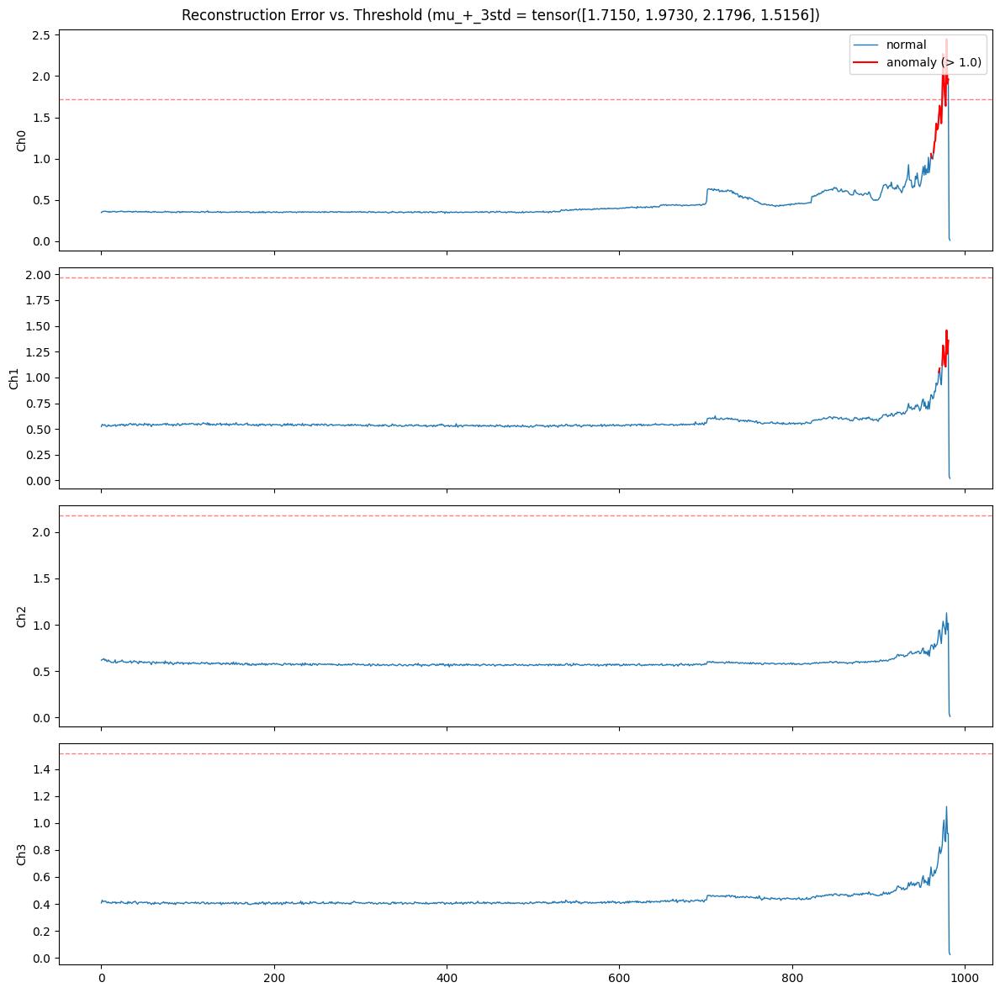

In [133]:
anom_percs['mu_+_3std']
thresholds['mu_+_3std']

# plot_anomaly_score(anom_percs['mu_+_3std'], thresholds['mu_+_3std'])

rel_errors = errors / thresh

anomaly_score = rel_errors.amax(dim=2)
x = np.arange(anomaly_score.shape[0])

anomaly_score = anom_percs['mu_+_3std']
anomaly_score = restored_errors.mean(axis=(2))
x = np.arange(anomaly_score.shape[0])
fig, axs = plt.subplots(4, 1, figsize=(12, 12), sharex=True)
for i in range(4):
    y = anomaly_score[:, i]

    axs[i].plot(x, y, linewidth=1, label='normal')

    # mask values <= 1 so red only draws where y > 1
    y_anom = np.ma.masked_where(y < 1.0, y)
    axs[i].plot(x, y_anom, color='red', linewidth=1.5, label='anomaly (> 1.0)')

    # reference threshold line
    axs[i].axhline(thresholds['mu_+_3std'][i], color='red', linestyle='--', alpha=0.5, linewidth=1)
    axs[i].set_ylabel(f'Ch{i}')

axs[0].legend(loc='upper right')
plt.suptitle(f'Reconstruction Error vs. Threshold (mu_+_3std = {thresholds['mu_+_3std']}')
plt.tight_layout()
plt.show()

In [143]:
mean_restored_errors

tensor([[0.3599, 0.5317, 0.6268, 0.4209],
        [0.3565, 0.5246, 0.6095, 0.4123],
        [0.3556, 0.5256, 0.6035, 0.4077],
        ...,
        [1.9577, 1.3589, 1.0162, 0.9218],
        [0.0332, 0.0393, 0.0461, 0.0435],
        [0.0087, 0.0202, 0.0119, 0.0249]])

In [145]:
preds

array([[0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       ...,
       [1., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.]], shape=(979, 4), dtype=float32)

In [ ]:
file_channel_scores = np.mean(errors, axis=2)

# Alternative: Use 99th percentile to catch spall impacts
# file_channel_scores = np.percentile(errors, 99, axis=2)


# --- Step 2: Establish a Baseline Threshold per Channel ---
# Just like before, isolate your healthy baseline files (e.g., files 10 to 60)
skip_startup = 10
k_baseline = 50

baseline_scores = file_channel_scores[skip_startup : skip_startup + k_baseline, :]

# Compute threshold independently for each channel (e.g., Mean + 3 * Std)
channel_means = baseline_scores.mean(axis=0)  # shape (4,)
channel_stds = baseline_scores.std(axis=0)  # shape (4,)

# Threshold per channel (shape: 4,)
thresholds = channel_means + (3 * channel_stds)


# --- Step 3: Generate the Final [file, channel] Binary Prediction Matrix ---
# Broadcast comparison: (984, 4) > (4,) -> results in a boolean matrix of shape (984, 4)
anomaly_matrix = file_channel_scores > thresholds

# Example check: Which files were flagged as anomalous for Channel 0 (Bearing 1)?
bearing_1_failures = np.where(anomaly_matrix[:, 0])[0]
print(
    'Bearing 1 first flagged at file index:'
    f' {bearing_1_failures[0] if len(bearing_1_failures) > 0 else "None"}'
)

In [142]:
anom_percs = []
anom_preds = {}
restored_errors = restore_dataset(all_errors, n_files=og_file, n_chunks=tot_test_chunks, original_length=og_seqlen)
for name, thresh in thresholds.items():
  thresh_resh = thresh[torch.newaxis, :, torch.newaxis]
  thresh_resh = thresh[torch.newaxis, :]

  mean_restored_errors = restored_errors.mean(axis=2)

  preds = (mean_restored_errors > thresh_resh).float().cpu().numpy()
  # anom_perc = preds.sum(axis=2)/og_seqlen
  file_preds_per_channel = anom_perc>0.0125
  anom_preds[name] = file_preds_per_channel
  anom_percs.append(anom_perc)

  rel_errors = restored_errors / thresh_resh
  anomaly_score = (rel_errors.sum(axis=2)/og_seqlen)>0.01

  plot_seq_preds(file_preds_per_channel, f'FullyConvAE - {name} ({thresh})')
  plot_anomaly_score(restored_errors,thresh_resh, f'FullyConvAE - {name} ({thresh})')
  print()

RuntimeError: The size of tensor a (20480) must match the size of tensor b (4) at non-singleton dimension 2

In [ ]:
def plot_reconstruction_error(error,threshold):
  fig, axs = plt.subplots(4, 1, figsize=(12, 12), sharex=True)
  for i in range(4):
    axs[i].plot(error[:,i])

    # reference threshold line
    axs[i].axhline(threshold[i], color='red', linestyle='--', alpha=0.5, linewidth=1)
    axs[i].set_ylabel(f'Ch{i}')


  axs[0].legend(loc='upper right')
  plt.suptitle(f'Reconstruction Error vs Threshold')
  plt.tight_layout()
  plt.show()

plot_reconstruction_error(restored_errors,thresh)

In [91]:
anom_preds['mu_+_3std']

array([[False, False,  True, False],
       [False, False,  True, False],
       [False, False,  True, False],
       ...,
       [ True,  True,  True,  True],
       [False, False, False, False],
       [False, False, False, False]], shape=(979, 4))